In [ ]:
import pandas as pd

df = pd.read_csv('combined dataset(latest).csv')
print(df.shape)
df.head()

(1698, 65)


,Id (Day),Date,Soil_Type,Soil_Depth_cm,pH,Organic_Matter_%,Nitrogen_%,Phosphorus_mg_kg,Potassium_mg_kg,Calcium_mg_kg,...,Effective_Growing_Days (EGD),Frost_Days (FD),Temp_Shock (TS),Heat_Stress_Days (HSD),Wet_Days (WD),Eff_Solar_Radiation (ESR),Frost_Days_after_Heat_stress (FDAHS),Frost_Days_During_Wet_Days (FDWD),Heat_Stress_During_Eff_solar_Radiation (HSESR),Yield (Production-Hector M. Ton)
0,1,11/1/2015,Silt Loam,26.21311,6.053876,4.103079,0.118100,40.671188,171.029485,528.908782,...,1,0,0,0,1,105.84,0,0,0,1095760
1,2,11/2/2015,Loamy,26.21311,5.621881,5.846555,0.320983,21.255524,162.914697,557.552685,...,1,0,0,0,1,110.53,0,0,0,1095760
2,3,11/3/2015,Loamy,26.21311,6.035004,2.687653,0.186282,28.903979,153.152362,1248.921305,...,1,0,1,1,1,126.21,0,0,0,1095760
3,4,11/4/2015,Clay Loam,26.21311,7.059722,1.810378,0.260113,27.115539,191.324739,717.817067,...,1,0,1,1,0,126.70,0,0,0,1095760
4,5,11/5/2015,Silt Loam,26.21311,5.112229,1.566453,0.248056,28.819822,161.987340,1007.030394,...,1,0,1,1,0,127.54,0,0,0,1095760


In [ ]:
# Check zeros
cols_to_check = ['solarradiation_W/m2', 'solarenergy_MJ/m2 ', 'UVindex']

for col in cols_to_check:
    zero_rows = df[df[col] == 0]
    print(f'{col}: {len(zero_rows)} zero(s)')
    print(zero_rows[['Date', col]])
    print()

solarradiation_W/m2: 1 zero(s)
         Date  solarradiation_W/m2
486  1/1/2018                  0.0

solarenergy_MJ/m2 : 1 zero(s)
         Date  solarenergy_MJ/m2 
486  1/1/2018                 0.0

UVindex: 1 zero(s)
         Date  UVindex
486  1/1/2018        0



In [ ]:
# Fix the 3 suspicious zeros on 1/1/2018 using interpolation
cols_to_fix = ['solarradiation_W/m2', 'solarenergy_MJ/m2 ', 'UVindex']

for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col].replace(0, None))

df[cols_to_fix] = df[cols_to_fix].interpolate(method='linear')

# Verify the fix
print(df.loc[486, ['Date'] + cols_to_fix])

Date                   1/1/2018
solarradiation_W/m2      122.15
solarenergy_MJ/m2          9.85
UVindex                     6.0
Name: 486, dtype: object


In [ ]:
# Yearly yield trend
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly_yield = df.groupby('Year')['Yield (Production-Hector M. Ton)'].mean()
print(yearly_yield)

Year
2015    1.095760e+06
2016    1.131130e+06
2017    1.194996e+06
2018    1.149327e+06
2019    1.180661e+06
2020    1.187289e+06
2021    1.215305e+06
2022    1.168653e+06
2023    1.146288e+06
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
print(df['Soil_Type'].unique())

['Silt Loam' 'Loamy' 'Clay Loam' 'Sandy Loam']


In [ ]:
# One-hot encode Soil_Type
soil_type_dummies = pd.get_dummies(df['Soil_Type'], prefix='Soil_Type')
print(soil_type_dummies.head())

   Soil_Type_Clay Loam  Soil_Type_Loamy  Soil_Type_Sandy Loam  \
0                False            False                 False   
1                False             True                 False   
2                False             True                 False   
3                 True            False                 False   
4                False            False                 False   

   Soil_Type_Silt Loam  
0                 True  
1                False  
2                False  
3                False  
4                 True  


In [ ]:
# One-hot encode Soil_Type and add to df
soil_type_dummies = pd.get_dummies(df['Soil_Type'], prefix='Soil_Type', dtype=int)
df = pd.concat([df, soil_type_dummies], axis=1)
df = df.drop('Soil_Type', axis=1)

# Verify
print(df[['Soil_Type_Clay Loam', 'Soil_Type_Loamy', 'Soil_Type_Sandy Loam', 'Soil_Type_Silt Loam']].head())

   Soil_Type_Clay Loam  Soil_Type_Loamy  Soil_Type_Sandy Loam  \
0                    0                0                     0   
1                    0                1                     0   
2                    0                1                     0   
3                    1                0                     0   
4                    0                0                     0   

   Soil_Type_Silt Loam  
0                    1  
1                    0  
2                    0  
3                    0  
4                    1  


In [ ]:
# One-hot encode remaining categorical columns
one_hot_cols = ['Soil_Texture', 'Soil_Structure', 'preciptype', 'conditions', 'icon']

for col in one_hot_cols:
    dummies = pd.get_dummies(df[col], prefix=col, dtype=int)
    df = pd.concat([df, dummies], axis=1)
    df = df.drop(col, axis=1)

print('Done! New shape:', df.shape)

Done! New shape: (1698, 85)


In [ ]:
# Label encode Common_Pests_Presence
df['Common_Pests_Presence'] = df['Common_Pests_Presence'].replace('Yes', 1).replace('No', 0)

# Label encode Drainage_Quality
df['Drainage_Quality'] = df['Drainage_Quality'].replace('Poor', 0).replace('Fair', 1).replace('Good', 2)

# Verify
print(df[['Common_Pests_Presence', 'Drainage_Quality']].head(10))

   Common_Pests_Presence  Drainage_Quality
0                      0                 2
1                      0                 1
2                      1                 1
3                      1                 2
4                      0                 2
5                      0                 1
6                      0                 2
7                      1                 0
8                      0                 1
9                      0                 2


/tmp/ipykernel_4437/2880718202.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Common_Pests_Presence'] = df['Common_Pests_Presence'].replace('Yes', 1).replace('No', 0)
/tmp/ipykernel_4437/2880718202.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Drainage_Quality'] = df['Drainage_Quality'].replace('Poor', 0).replace('Fair', 1).replace('Good', 2)


In [ ]:
# Confirm no more text columns remaining
print('Remaining text columns:', df.select_dtypes(include='object').columns.tolist())
print()
print('Total columns now:', df.shape[1])
print()
df.head()

Remaining text columns: ['Date']

Total columns now: 85



,Id (Day),Date,Soil_Depth_cm,pH,Organic_Matter_%,Nitrogen_%,Phosphorus_mg_kg,Potassium_mg_kg,Calcium_mg_kg,Magnesium_mg_kg,...,conditions_Clear,conditions_Partially cloudy,conditions_rain,"conditions_rain, Overcast","conditions_rain, Partially cloudy",icon_clear-day,icon_fog,icon_partly-cloudy-day,icon_rain,icon_wind
0,1,11/1/2015,26.21311,6.053876,4.103079,0.118100,40.671188,171.029485,528.908782,176.211120,...,0,0,0,0,1,0,0,0,1,0
1,2,11/2/2015,26.21311,5.621881,5.846555,0.320983,21.255524,162.914697,557.552685,105.063390,...,0,0,0,0,1,0,0,0,1,0
2,3,11/3/2015,26.21311,6.035004,2.687653,0.186282,28.903979,153.152362,1248.921305,106.995379,...,0,1,0,0,0,0,0,1,0,0
3,4,11/4/2015,26.21311,7.059722,1.810378,0.260113,27.115539,191.324739,717.817067,97.918637,...,0,0,0,0,1,0,0,0,1,0
4,5,11/5/2015,26.21311,5.112229,1.566453,0.248056,28.819822,161.987340,1007.030394,80.238259,...,0,1,0,0,0,0,0,1,0,0


In [ ]:
from sklearn.preprocessing import StandardScaler

# Columns to exclude from scaling
exclude_cols = ['Date', 'Year']

# Get only the numerical columns to scale
num_cols = df.select_dtypes(include='number').columns.tolist()
target = 'Yield (Production-Hector M. Ton)'
num_cols = [col for col in num_cols if col not in exclude_cols and col != target]

# Scale
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

# Verify
print(df[num_cols].head())

   Id (Day)  Soil_Depth_cm        pH  Organic_Matter_%  Nitrogen_%  \
0 -1.731031        1.96497 -0.237259          0.314790   -1.447282   
1 -1.728991        1.96497 -0.836784          1.659975    0.843589   
2 -1.726951        1.96497 -0.263450         -0.777287   -0.677402   
3 -1.724911        1.96497  1.158658         -1.454152    0.156263   
4 -1.722871        1.96497 -1.544081         -1.642353    0.020127   

   Phosphorus_mg_kg  Potassium_mg_kg  Calcium_mg_kg  Magnesium_mg_kg  \
0          1.163635        -0.074148      -1.675891         1.202533   
1         -1.043513        -0.259943      -1.576471        -0.464203   
2         -0.174046        -0.483460       0.823191        -0.418943   
3         -0.377354         0.390529      -1.020212        -0.631579   
4         -0.183613        -0.281176      -0.016385        -1.045766   

   Sulfur_mg_kg  ...  conditions_Clear  conditions_Partially cloudy  \
0     -1.067929  ...         -0.769981                     -0.57871   
1   

In [ ]:
# Check scaling worked - mean should be ~0 and std should be ~1
print(df[num_cols].mean().round(2))
print()
print(df[num_cols].std().round(2))

Id (Day)                 -0.0
Soil_Depth_cm             0.0
pH                       -0.0
Organic_Matter_%         -0.0
Nitrogen_%                0.0
                         ... 
icon_clear-day           -0.0
icon_fog                  0.0
icon_partly-cloudy-day    0.0
icon_rain                -0.0
icon_wind                 0.0
Length: 82, dtype: float64

Id (Day)                  1.0
Soil_Depth_cm             1.0
pH                        1.0
Organic_Matter_%          1.0
Nitrogen_%                1.0
                         ... 
icon_clear-day            1.0
icon_fog                  1.0
icon_partly-cloudy-day    1.0
icon_rain                 1.0
icon_wind                 1.0
Length: 82, dtype: float64


In [ ]:
df

,Id (Day),Date,Soil_Depth_cm,pH,Organic_Matter_%,Nitrogen_%,Phosphorus_mg_kg,Potassium_mg_kg,Calcium_mg_kg,Magnesium_mg_kg,...,conditions_Clear,conditions_Partially cloudy,conditions_rain,"conditions_rain, Overcast","conditions_rain, Partially cloudy",icon_clear-day,icon_fog,icon_partly-cloudy-day,icon_rain,icon_wind
0,-1.731031,11/1/2015,1.964970,-0.237259,0.314790,-1.447282,1.163635,-0.074148,-1.675891,1.202533,...,-0.769981,-0.57871,-0.111903,-0.1513,1.38656,-0.769011,-0.059549,-0.572363,1.285739,-0.03434
1,-1.728991,11/2/2015,1.964970,-0.836784,1.659975,0.843589,-1.043513,-0.259943,-1.576471,-0.464203,...,-0.769981,-0.57871,-0.111903,-0.1513,1.38656,-0.769011,-0.059549,-0.572363,1.285739,-0.03434
2,-1.726951,11/3/2015,1.964970,-0.263450,-0.777287,-0.677402,-0.174046,-0.483460,0.823191,-0.418943,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
3,-1.724911,11/4/2015,1.964970,1.158658,-1.454152,0.156263,-0.377354,0.390529,-1.020212,-0.631579,...,-0.769981,-0.57871,-0.111903,-0.1513,1.38656,-0.769011,-0.059549,-0.572363,1.285739,-0.03434
4,-1.722871,11/5/2015,1.964970,-1.544081,-1.642353,0.020127,-0.183613,-0.281176,-0.016385,-1.045766,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1693,1.722871,5/27/2023,-0.769878,1.545720,-0.938583,-0.836858,-0.261919,-1.418087,0.986340,0.689287,...,-0.769981,-0.57871,-0.111903,-0.1513,1.38656,-0.769011,-0.059549,-0.572363,1.285739,-0.03434
1694,1.724911,5/28/2023,-0.769878,-0.694375,0.153674,0.924213,-0.069174,0.452566,-1.482857,0.460885,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
1695,1.726951,5/29/2023,-0.769878,1.661928,0.923401,1.383009,0.633973,-0.389280,1.417442,-0.746925,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
1696,1.728991,5/30/2023,-0.769878,1.258720,0.838900,-0.952790,-0.206397,-1.265850,0.880334,1.754578,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434


In [ ]:
df.to_csv('cleaned_dataset.csv', index=False)

In [ ]:
# Split into training and testing sets
train_years = [2017, 2018, 2019, 2020, 2021, 2022]
test_years = [2023]

df_train = df[df['Year'].isin(train_years)]
df_test = df[df['Year'].isin(test_years)]

print('Training set shape:', df_train.shape)
print('Testing set shape:', df_test.shape)

Training set shape: (1273, 85)
Testing set shape: (151, 85)


In [ ]:
# Separate features (X) and target (y)
target = 'Yield (Production-Hector M. Ton)'

X_train = df_train.drop(columns=[target, 'Date', 'Year'])
y_train = df_train[target]

X_test = df_test.drop(columns=[target, 'Date', 'Year'])
y_test = df_test[target]

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

X_train shape: (1273, 82)
y_train shape: (1273,)
X_test shape: (151, 82)
y_test shape: (151,)


In [ ]:
from sklearn.linear_model import LinearRegression

# Build and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print('Model trained successfully')

Model trained successfully


In [ ]:
print('Training set:')
df_train.head()

Training set:


,Id (Day),Date,Soil_Depth_cm,pH,Organic_Matter_%,Nitrogen_%,Phosphorus_mg_kg,Potassium_mg_kg,Calcium_mg_kg,Magnesium_mg_kg,...,conditions_Clear,conditions_Partially cloudy,conditions_rain,"conditions_rain, Overcast","conditions_rain, Partially cloudy",icon_clear-day,icon_fog,icon_partly-cloudy-day,icon_rain,icon_wind
274,-1.172042,1/1/2017,-1.203102,0.286646,0.999953,-0.940453,1.075639,0.773465,0.609492,1.562317,...,1.298734,-0.57871,-0.111903,-0.1513,-0.72121,1.300372,-0.059549,-0.572363,-0.777763,-0.03434
275,-1.170002,1/2/2017,-1.203102,0.216350,-1.202563,-0.037076,-0.897278,1.173797,1.201591,-1.183467,...,1.298734,-0.57871,-0.111903,-0.1513,-0.72121,1.300372,-0.059549,-0.572363,-0.777763,-0.03434
276,-1.167961,1/3/2017,-1.203102,-0.292324,1.439914,-0.527640,0.028471,-1.007256,-0.023453,1.025726,...,1.298734,-0.57871,-0.111903,-0.1513,-0.72121,1.300372,-0.059549,-0.572363,-0.777763,-0.03434
277,-1.165921,1/4/2017,-1.203102,-1.191825,1.490253,1.665878,0.064804,0.186000,-0.401036,0.402143,...,1.298734,-0.57871,-0.111903,-0.1513,-0.72121,1.300372,-0.059549,-0.572363,-0.777763,-0.03434
278,-1.163881,1/5/2017,-1.203102,1.311897,1.056877,1.679712,0.211680,1.177473,0.763816,-0.828712,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434


In [ ]:
print('Testing set:')
df_test.head()

Testing set:


,Id (Day),Date,Soil_Depth_cm,pH,Organic_Matter_%,Nitrogen_%,Phosphorus_mg_kg,Potassium_mg_kg,Calcium_mg_kg,Magnesium_mg_kg,...,conditions_Clear,conditions_Partially cloudy,conditions_rain,"conditions_rain, Overcast","conditions_rain, Partially cloudy",icon_clear-day,icon_fog,icon_partly-cloudy-day,icon_rain,icon_wind
1547,1.425015,1/1/2023,-0.769878,-0.043380,-1.247870,1.458223,1.385684,1.103304,0.213834,-0.696876,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
1548,1.427055,1/2/2023,-0.769878,-0.314573,-1.206498,-0.782477,-1.065939,-1.259448,1.371817,-0.952095,...,1.298734,-0.57871,-0.111903,-0.1513,-0.72121,1.300372,-0.059549,-0.572363,-0.777763,-0.03434
1549,1.429095,1/3/2023,-0.769878,-0.399532,1.417582,-1.291642,-0.465308,1.316797,0.639964,1.267589,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
1550,1.431135,1/4/2023,-0.769878,-0.660666,0.620135,-1.613911,-0.513598,1.181113,1.672859,-1.125613,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434
1551,1.433175,1/5/2023,-0.769878,-1.623597,-0.172326,-0.905981,1.220456,0.690966,0.430989,-1.582074,...,-0.769981,1.72798,-0.111903,-0.1513,-0.72121,-0.769011,-0.059549,1.747142,-0.777763,-0.03434


In [ ]:
import matplotlib.pyplot as plt


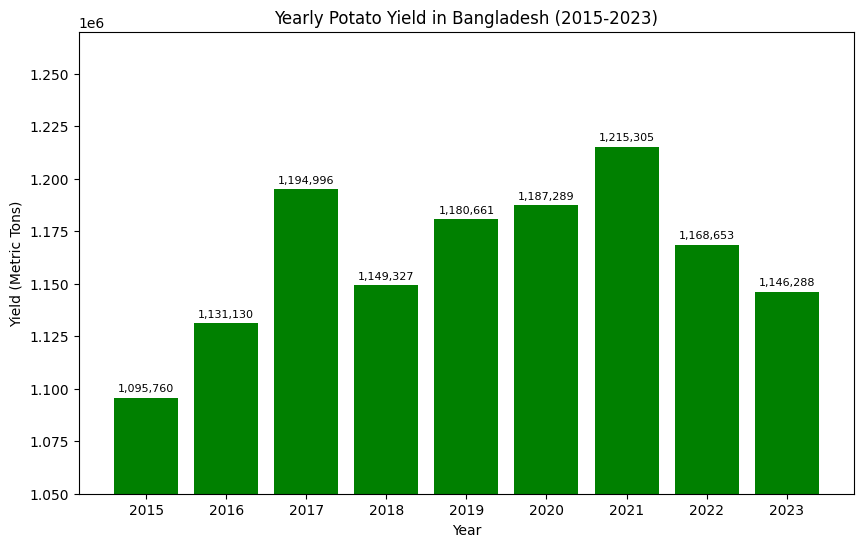

In [ ]:
df_original = pd.read_csv('combined dataset(latest).csv')
df_original['Year'] = pd.to_datetime(df_original['Date']).dt.year

yearly_yield = df_original.groupby('Year')['Yield (Production-Hector M. Ton)'].mean()

plt.figure(figsize=(10, 6))
bars = plt.bar(yearly_yield.index, yearly_yield.values, color='green')
plt.title('Yearly Potato Yield in Bangladesh (2015-2023)')
plt.xlabel('Year')
plt.ylabel('Yield (Metric Tons)')
plt.xticks(yearly_yield.index)
plt.ylim(1_050_000, 1_270_000)
plt.bar_label(bars, labels=[f'{v:,.0f}' for v in yearly_yield.values], padding=3, fontsize=8)
plt.show()

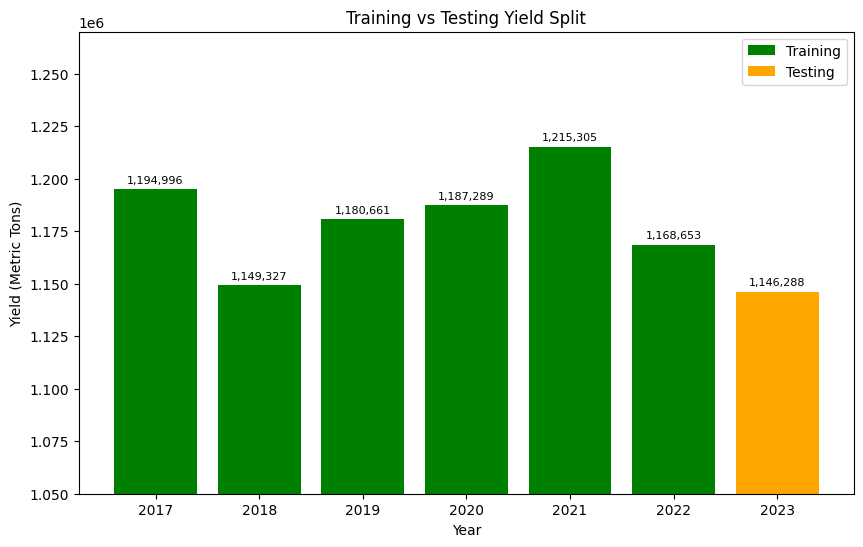

In [ ]:
# Yield for training years vs testing year
train_yield = df_original[df_original['Year'].isin([2017, 2018, 2019, 2020, 2021, 2022])]
test_yield = df_original[df_original['Year'] == 2023]

train_avg = train_yield.groupby('Year')['Yield (Production-Hector M. Ton)'].mean()
test_avg = test_yield.groupby('Year')['Yield (Production-Hector M. Ton)'].mean()

plt.figure(figsize=(10, 6))
train_bars = plt.bar(train_avg.index, train_avg.values, color='green', label='Training')
test_bars = plt.bar(test_avg.index, test_avg.values, color='orange', label='Testing')
plt.title('Training vs Testing Yield Split')
plt.xlabel('Year')
plt.ylabel('Yield (Metric Tons)')
plt.xticks(list(train_avg.index) + list(test_avg.index))
plt.ylim(1_050_000, 1_270_000)
plt.legend()
plt.bar_label(train_bars, labels=[f'{v:,.0f}' for v in train_avg.values], padding=3, fontsize=8)
plt.bar_label(test_bars, labels=[f'{v:,.0f}' for v in test_avg.values], padding=3, fontsize=8)
plt.show()

In [ ]:
# Check exact column names for temperature and precipitation
print([col for col in df_original.columns if 'temp' in col.lower() or 'precip' in col.lower() or 'ph' in col.lower()])

['pH', 'Phosphorus_mg_kg', 'Soil_Temperature_C', 'tempmax_C', 'tempmin_C', 'avg_temp_C', 'precipitation_mm ', 'precipprob%', 'precipcover%', 'preciptype', 'Moonphase', 'Temp_Shock (TS) ']


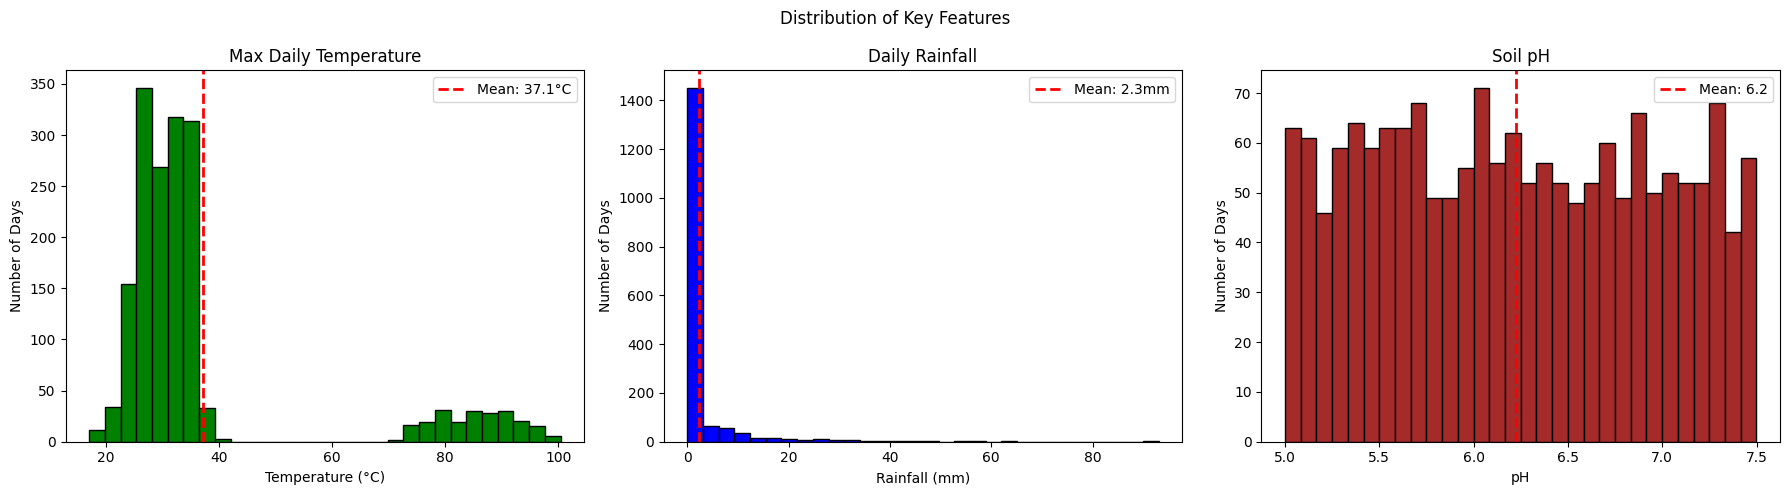

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Temperature
axes[0].hist(df_original['tempmax_C'], bins=30, color='green', edgecolor='black')
axes[0].axvline(df_original['tempmax_C'].mean(), color='red', linestyle='dashed', linewidth=2, label=f'Mean: {df_original["tempmax_C"].mean():.1f}°C')
axes[0].set_title('Max Daily Temperature')
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Number of Days')
axes[0].legend()

# Rainfall
axes[1].hist(df_original['precipitation_mm '], bins=30, color='blue', edgecolor='black')
axes[1].axvline(df_original['precipitation_mm '].mean(), color='red', linestyle='dashed', linewidth=2, label=f'Mean: {df_original["precipitation_mm "].mean():.1f}mm')
axes[1].set_title('Daily Rainfall')
axes[1].set_xlabel('Rainfall (mm)')
axes[1].set_ylabel('Number of Days')
axes[1].legend()

# Soil pH
axes[2].hist(df_original['pH'], bins=30, color='brown', edgecolor='black')
axes[2].axvline(df_original['pH'].mean(), color='red', linestyle='dashed', linewidth=2, label=f'Mean: {df_original["pH"].mean():.1f}')
axes[2].set_title('Soil pH')
axes[2].set_xlabel('pH')
axes[2].set_ylabel('Number of Days')
axes[2].legend()

plt.suptitle('Distribution of Key Features')
plt.tight_layout()
plt.show()

## Data Dictionary

### Soil Properties
| Column Name | Description | Units | Data Type |
|---|---|---|---|
| Soil_Type | Type of soil in the field | Category | Text (encoded) |
| Soil_Depth_cm | Depth of soil layer | cm | Numeric |
| pH | Acidity or alkalinity of the soil | pH scale (0-14) | Numeric |
| Organic_Matter_% | Percentage of organic content in soil | % | Numeric |
| Nitrogen_% | Nitrogen content in soil | % | Numeric |
| Phosphorus_mg_kg | Phosphorus content in soil | mg/kg | Numeric |
| Potassium_mg_kg | Potassium content in soil | mg/kg | Numeric |
| Soil_Temperature_C | Temperature of the soil | °C | Numeric |
| Drainage_Quality | Quality of water drainage in soil | Category (Poor/Fair/Good) | Numeric (encoded) |

### Weather Features
| Column Name | Description | Units | Data Type |
|---|---|---|---|
| tempmax_C | Maximum daily air temperature | °C | Numeric |
| tempmin_C | Minimum daily air temperature | °C | Numeric |
| avg_temp_C | Average daily air temperature | °C | Numeric |
| precipitation_mm | Total daily rainfall | mm | Numeric |
| precipprob% | Probability of precipitation | % | Numeric |
| precipcover% | Percentage of day with precipitation | % | Numeric |
| humidity% | Relative humidity | % | Numeric |
| windspeed_km/h | Daily wind speed | km/h | Numeric |
| cloudcover% | Percentage of sky covered by clouds | % | Numeric |
| solarradiation_W/m2 | Solar radiation received | W/m² | Numeric |
| UVindex | UV radiation index | Index (0-11+) | Numeric |

### Crop Stress Indicators
| Column Name | Description | Units | Data Type |
|---|---|---|---|
| Temp_Shock (TS) | Days with sudden temperature change | Days | Numeric |
| Heat_Stress_Days (HSD) | Days where temperature exceeded heat threshold | Days | Numeric |
| Wet_Days (WD) | Days with significant rainfall | Days | Numeric |
| Frost_Days (FD) | Days where frost occurred | Days | Numeric |
| Eff_Solar_Radiation (ESR) | Effective solar radiation for crop growth | W/m² | Numeric |

In [ ]:
import seaborn as sns

# Define the feature groups from your data dictionary
weather_features = ['tempmax_C', 'tempmin_C', 'avg_temp_C', 'precipitation_mm ',
                    'precipprob%', 'precipcover%', 'humidity%', 'windspeed_km/h',
                    'cloudcover%', 'solarradiation_W/m2', 'UVindex']

soil_features = ['Soil_Depth_cm', 'pH', 'Organic_Matter_%', 'Nitrogen_%',
                 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Soil_Temperature_C',
                 'Drainage_Quality']

crop_stress_features = ['Temp_Shock (TS) ', 'Heat_Stress_Days (HSD)',
                        'Wet_Days (WD)', 'Frost_Days (FD)', 'Eff_Solar_Radiation (ESR)']

target = 'Yield (Production-Hector M. Ton)'

# Calculate correlation of each feature group with yield
all_features = weather_features + soil_features + crop_stress_features
corr_with_yield = df[all_features + [target]].corr()[target].drop(target)

print(corr_with_yield.sort_values(ascending=False))

avg_temp_C                   0.261340
tempmin_C                    0.261183
tempmax_C                    0.252642
Heat_Stress_Days (HSD)       0.095914
Temp_Shock (TS)              0.095914
Nitrogen_%                   0.039183
Eff_Solar_Radiation (ESR)    0.033964
solarradiation_W/m2          0.032934
UVindex                      0.021045
Phosphorus_mg_kg             0.016772
Potassium_mg_kg              0.005417
pH                           0.005154
Soil_Temperature_C          -0.004478
Drainage_Quality            -0.018594
Organic_Matter_%            -0.026024
windspeed_km/h              -0.028880
humidity%                   -0.029329
precipprob%                 -0.029897
precipitation_mm            -0.038866
precipcover%                -0.039615
Wet_Days (WD)               -0.052887
cloudcover%                 -0.086037
Soil_Depth_cm               -0.319916
Frost_Days (FD)                   NaN
Name: Yield (Production-Hector M. Ton), dtype: float64


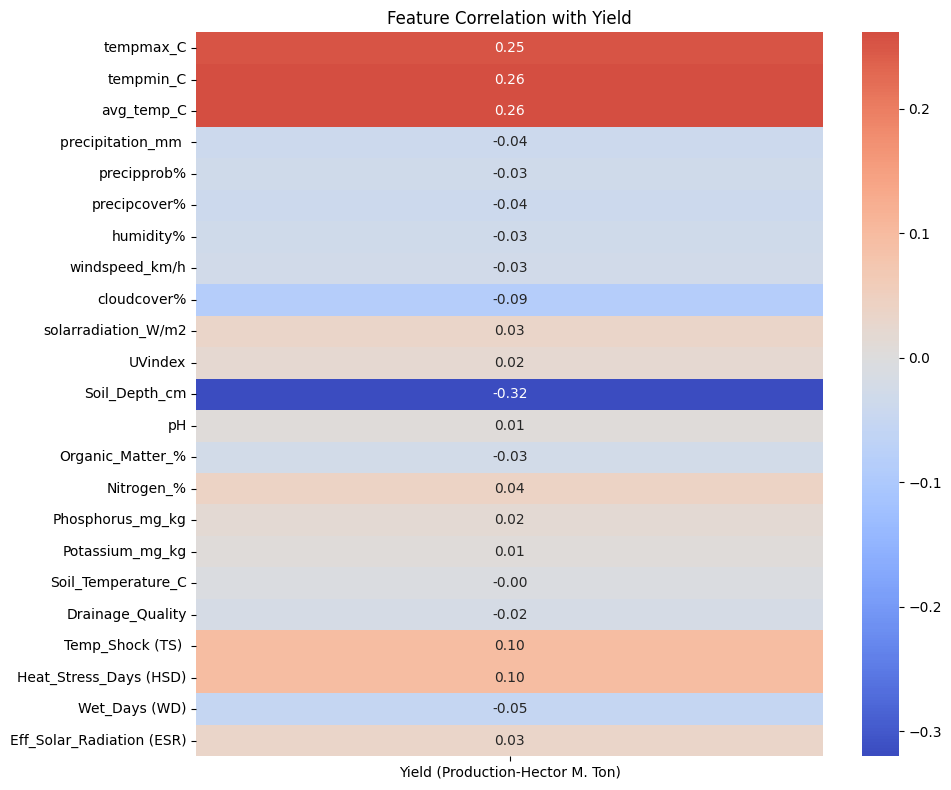

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_with_yield.drop('Frost_Days (FD)').to_frame(),
            annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation with Yield')
plt.tight_layout()
plt.show()

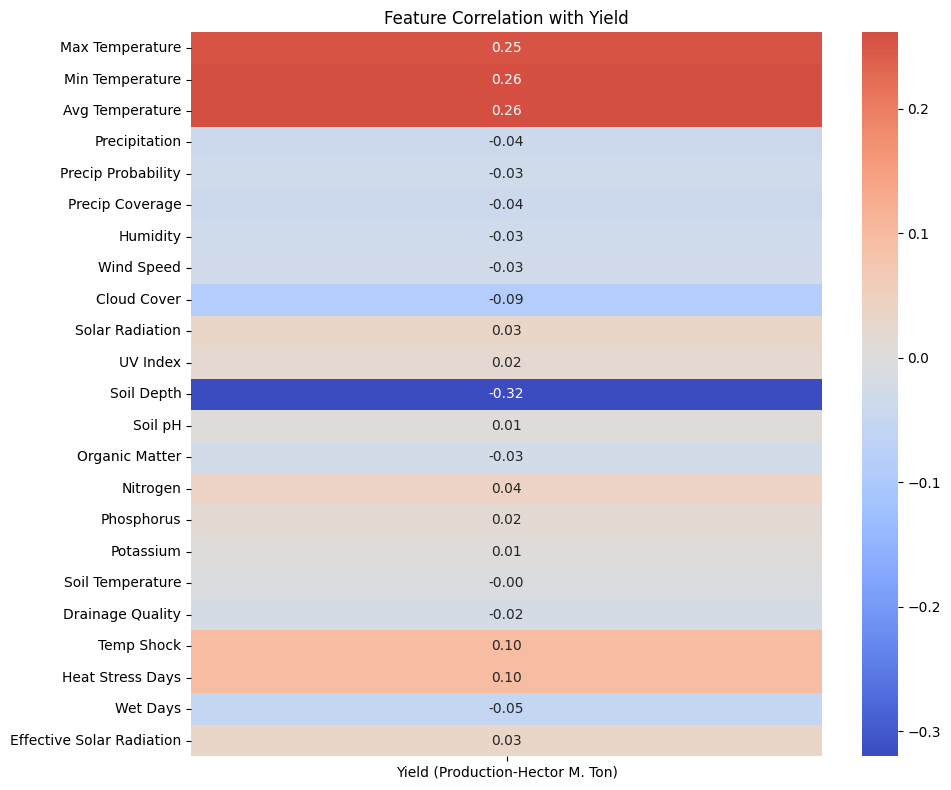

In [ ]:
# Rename features for display
label_map = {
    'tempmax_C': 'Max Temperature',
    'tempmin_C': 'Min Temperature',
    'avg_temp_C': 'Avg Temperature',
    'precipitation_mm ': 'Precipitation',
    'precipprob%': 'Precip Probability',
    'precipcover%': 'Precip Coverage',
    'humidity%': 'Humidity',
    'windspeed_km/h': 'Wind Speed',
    'cloudcover%': 'Cloud Cover',
    'solarradiation_W/m2': 'Solar Radiation',
    'UVindex': 'UV Index',
    'Soil_Depth_cm': 'Soil Depth',
    'pH': 'Soil pH',
    'Organic_Matter_%': 'Organic Matter',
    'Nitrogen_%': 'Nitrogen',
    'Phosphorus_mg_kg': 'Phosphorus',
    'Potassium_mg_kg': 'Potassium',
    'Soil_Temperature_C': 'Soil Temperature',
    'Drainage_Quality': 'Drainage Quality',
    'Temp_Shock (TS) ': 'Temp Shock',
    'Heat_Stress_Days (HSD)': 'Heat Stress Days',
    'Wet_Days (WD)': 'Wet Days',
    'Frost_Days (FD)': 'Frost Days',
    'Eff_Solar_Radiation (ESR)': 'Effective Solar Radiation'
}

corr_renamed = corr_with_yield.drop('Frost_Days (FD)').rename(index=label_map)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_renamed.to_frame(), annot=True, cmap='coolwarm',
            center=0, fmt='.2f')
plt.title('Feature Correlation with Yield')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Combination 1 - strongest correlated features
combo1_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm']

# Train
X_train_c1 = X_train[combo1_features]
X_test_c1 = X_test[combo1_features]

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_c1, y_train)

# Test
y_pred_c1 = rf_model.predict(X_test_c1)

# Evaluate
rmse_c1 = np.sqrt(mean_squared_error(y_test, y_pred_c1))
r2_c1 = r2_score(y_test, y_pred_c1)

print('Combination 1 Results:')
print(f'Features: {combo1_features}')
print(f'RMSE: {rmse_c1:.2f}')
print(f'R²: {r2_c1:.4f}')

Combination 1 Results:
Features: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm']
RMSE: 0.00
R²: 1.0000


In [ ]:
print(X_train.columns.tolist())

['Id (Day)', 'Soil_Depth_cm', 'pH', 'Organic_Matter_%', 'Nitrogen_%', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Calcium_mg_kg', 'Magnesium_mg_kg', 'Sulfur_mg_kg', 'Sand_%', 'Silt_%', 'Clay_%', 'Bulk_Density_g_cm3', 'Moisture_Content_%', 'Tuber_Yield_Potential_kg_ha', 'Soil_Compaction_kPa', 'Common_Pests_Presence', 'Drainage_Quality', 'Irrigation_Applied_mm', 'Soil_Temperature_C', 'Rainfall_mm', 'Humidity_%', 'Sunlight_Exposure_hours', 'tempmax_C', 'tempmin_C', 'avg_temp_C', 'feelslikemax_C', 'feelslikemin_C', 'feelslike_C', 'dew_mm', 'humidity%', 'precipitation_mm ', 'precipprob%', 'precipcover%', 'snow_Cm', 'snowdepth_Cm', 'windgust_km/h', 'windspeed_km/h', 'winddir_◦', 'sealevelpressure_mb', 'cloudcover%', 'visibility_km', 'solarradiation_W/m2', 'solarenergy_MJ/m2 ', 'UVindex', 'Moonphase', 'Degree_Days (DD)', 'Effective_Growing_Days (EGD)', 'Frost_Days (FD)', 'Temp_Shock (TS) ', 'Heat_Stress_Days (HSD)', 'Wet_Days (WD)', 'Eff_Solar_Radiation (ESR)', 'Frost_Days_after_Heat_stress (FDAH

In [ ]:
print(y_train.describe())

count    1.273000e+03
mean     1.182709e+06
std      3.187323e+04
min      1.134920e+06
25%      1.169947e+06
50%      1.177688e+06
75%      1.219265e+06
max      1.230501e+06
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
print(y_test.describe())

count        151.0
mean     1146288.0
std            0.0
min      1146288.0
25%      1146288.0
50%      1146288.0
75%      1146288.0
max      1146288.0
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
print(X_train_c1.describe())

        avg_temp_C    tempmin_C    tempmax_C  Heat_Stress_Days (HSD)  \
count  1273.000000  1273.000000  1273.000000             1273.000000   
mean      0.119014     0.117549     0.119743                0.033950   
std       1.122818     1.121198     1.123237                0.996757   
min      -1.066333    -1.080769    -1.057006               -1.093909   
25%      -0.520920    -0.533652    -0.478275               -1.093909   
50%      -0.293665    -0.290489    -0.320440                0.914153   
75%      -0.066410     0.013465    -0.109992                0.914153   
max       3.211746     3.381273     3.330825                0.914153   

       Temp_Shock (TS)   Soil_Depth_cm  
count       1273.000000    1273.000000  
mean           0.033950      -0.179810  
std            0.996757       0.718485  
min           -1.093909      -1.203102  
25%           -1.093909      -1.028592  
50%            0.914153      -0.363590  
75%            0.914153       0.651319  
max            0.914153

In [ ]:
print(y_test.describe())

count        151.0
mean     1146288.0
std            0.0
min      1146288.0
25%      1146288.0
50%      1146288.0
75%      1146288.0
max      1146288.0
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
print(df['Yield (Production-Hector M. Ton)'].describe())

count    1.698000e+03
mean     1.169876e+06
std      4.137244e+04
min      1.095760e+06
25%      1.137762e+06
50%      1.169947e+06
75%      1.184989e+06
max      1.230501e+06
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
print(df['Yield (Production-Hector M. Ton)'].describe())

count    1.698000e+03
mean     1.169876e+06
std      4.137244e+04
min      1.095760e+06
25%      1.137762e+06
50%      1.169947e+06
75%      1.184989e+06
max      1.230501e+06
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
print(y_test.describe())

count        151.0
mean     1146288.0
std            0.0
min      1146288.0
25%      1146288.0
50%      1146288.0
75%      1146288.0
max      1146288.0
Name: Yield (Production-Hector M. Ton), dtype: float64


In [ ]:
# Aggregate by year - average all daily features into one row per year
feature_cols = X_train.columns.tolist()

# Combine train and test back together temporarily
df_yearly = df.groupby('Year')[feature_cols + [target]].mean()

print(df_yearly.shape)
print(df_yearly)

(9, 83)
      Id (Day)  Soil_Depth_cm        pH  Organic_Matter_%  Nitrogen_%  \
Year                                                                    
2015 -1.669828       1.964970  0.051902         -0.104374   -0.239965   
2016 -1.390333       1.057682  0.080535          0.035036   -0.062618   
2017 -0.956810      -1.152889 -0.001293         -0.056979    0.040295   
2018 -0.524308      -0.716997 -0.046391         -0.001768    0.119850   
2019 -0.091805      -0.065923 -0.058439         -0.015458   -0.048382   
2020  0.341718      -0.072935  0.035044          0.091435    0.012861   
2021  0.775241       0.661583 -0.016975         -0.028721    0.084795   
2022  1.207744       0.267798  0.001529         -0.014904   -0.048648   
2023  1.578023      -0.769878 -0.013324          0.029193   -0.040537   

      Phosphorus_mg_kg  Potassium_mg_kg  Calcium_mg_kg  Magnesium_mg_kg  \
Year                                                                      
2015         -0.161058        -0.09327

In [ ]:
# Split into train and test by year
train_years = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
test_years = [2023]

df_train_y = df_yearly[df_yearly.index.isin(train_years)]
df_test_y = df_yearly[df_yearly.index.isin(test_years)]

# Combo 1 features
combo1_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm']

X_train_y = df_train_y[combo1_features]
y_train_y = df_train_y[target]

X_test_y = df_test_y[combo1_features]
y_test_y = df_test_y[target]

# Train Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_y, y_train_y)

# Predict and evaluate
y_pred_y = rf.predict(X_test_y)

rmse = np.sqrt(mean_squared_error(y_test_y, y_pred_y))
r2 = r2_score(y_test_y, y_pred_y)

print(f'Predicted yield 2023: {y_pred_y[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse:,.0f}')
print(f'R²: {r2:.4f}')

Predicted yield 2023: 1,183,902 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 37,614
R²: nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


In [ ]:
# Combination 2 - adding cloudcover% and Wet_Days
combo2_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)']

X_train_c2 = df_train_y[combo2_features]
X_test_c2 = df_test_y[combo2_features]

rf2 = RandomForestRegressor(n_estimators=100, random_state=42)
rf2.fit(X_train_c2, y_train_y)

y_pred_c2 = rf2.predict(X_test_c2)

rmse_c2 = np.sqrt(mean_squared_error(y_test_y, y_pred_c2))

print(f'Predicted yield 2023: {y_pred_c2[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse_c2:,.0f}')

Predicted yield 2023: 1,180,094 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 33,806


In [ ]:
# Combination 3 - adding precipitation_mm and precipcover%
combo3_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'precipitation_mm ', 'precipcover%']

X_train_y3 = df_train_y[combo3_features]
X_test_y3 = df_test_y[combo3_features]

rf3 = RandomForestRegressor(n_estimators=100, random_state=42)
rf3.fit(X_train_y3, y_train_y)

y_pred_y3 = rf3.predict(X_test_y3)

rmse3 = np.sqrt(mean_squared_error(y_test_y, y_pred_y3))

print(f'Predicted yield 2023: {y_pred_y3[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse3:,.0f}')

Predicted yield 2023: 1,181,238 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 34,950


In [ ]:
# Combination 4 - adding Nitrogen_% and Eff_Solar_Radiation
combo4_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'precipitation_mm ', 'precipcover%',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)']

X_train_y4 = df_train_y[combo4_features]
X_test_y4 = df_test_y[combo4_features]

rf4 = RandomForestRegressor(n_estimators=100, random_state=42)
rf4.fit(X_train_y4, y_train_y)

y_pred_y4 = rf4.predict(X_test_y4)

rmse4 = np.sqrt(mean_squared_error(y_test_y, y_pred_y4))

print(f'Predicted yield 2023: {y_pred_y4[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse4:,.0f}')

Predicted yield 2023: 1,178,686 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 32,398


In [ ]:
# Combination 5 - combo 2 + Nitrogen and Eff Solar Radiation (skipping precip features)
combo5_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)']

X_train_y5 = df_train_y[combo5_features]
X_test_y5 = df_test_y[combo5_features]

rf5 = RandomForestRegressor(n_estimators=100, random_state=42)
rf5.fit(X_train_y5, y_train_y)

y_pred_y5 = rf5.predict(X_test_y5)

rmse5 = np.sqrt(mean_squared_error(y_test_y, y_pred_y5))

print(f'Predicted yield 2023: {y_pred_y5[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse5:,.0f}')

Predicted yield 2023: 1,175,636 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 29,348


In [ ]:
# Combination 6 - combo 5 + solarradiation and humidity
combo6_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'solarradiation_W/m2', 'humidity%']

X_train_y6 = df_train_y[combo6_features]
X_test_y6 = df_test_y[combo6_features]

rf6 = RandomForestRegressor(n_estimators=100, random_state=42)
rf6.fit(X_train_y6, y_train_y)

y_pred_y6 = rf6.predict(X_test_y6)

rmse6 = np.sqrt(mean_squared_error(y_test_y, y_pred_y6))

print(f'Predicted yield 2023: {y_pred_y6[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse6:,.0f}')

Predicted yield 2023: 1,177,528 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 31,240


In [ ]:
# Combination 7 - combo 5 + windspeed and UVindex
combo7_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'windspeed_km/h', 'UVindex']

X_train_y7 = df_train_y[combo7_features]
X_test_y7 = df_test_y[combo7_features]

rf7 = RandomForestRegressor(n_estimators=100, random_state=42)
rf7.fit(X_train_y7, y_train_y)

y_pred_y7 = rf7.predict(X_test_y7)

rmse7 = np.sqrt(mean_squared_error(y_test_y, y_pred_y7))

print(f'Predicted yield 2023: {y_pred_y7[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse7:,.0f}')

Predicted yield 2023: 1,176,443 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 30,155


In [ ]:
# Combination 8 - combo 5 + Phosphorus and Potassium
combo8_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg']

X_train_y8 = df_train_y[combo8_features]
X_test_y8 = df_test_y[combo8_features]

rf8 = RandomForestRegressor(n_estimators=100, random_state=42)
rf8.fit(X_train_y8, y_train_y)

y_pred_y8 = rf8.predict(X_test_y8)

rmse8 = np.sqrt(mean_squared_error(y_test_y, y_pred_y8))

print(f'Predicted yield 2023: {y_pred_y8[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse8:,.0f}')

Predicted yield 2023: 1,172,433 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 26,145


In [ ]:
# Combination 9 - combo 8 + Organic_Matter and Drainage_Quality
combo9_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality']

X_train_y9 = df_train_y[combo9_features]
X_test_y9 = df_test_y[combo9_features]

rf9 = RandomForestRegressor(n_estimators=100, random_state=42)
rf9.fit(X_train_y9, y_train_y)

y_pred_y9 = rf9.predict(X_test_y9)

rmse9 = np.sqrt(mean_squared_error(y_test_y, y_pred_y9))

print(f'Predicted yield 2023: {y_pred_y9[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse9:,.0f}')

Predicted yield 2023: 1,171,161 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 24,873


In [ ]:
# Combination 10 - combo 9 + pH and Soil_Temperature_C
combo10_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C']

X_train_y10 = df_train_y[combo10_features]
X_test_y10 = df_test_y[combo10_features]

rf10 = RandomForestRegressor(n_estimators=100, random_state=42)
rf10.fit(X_train_y10, y_train_y)

y_pred_y10 = rf10.predict(X_test_y10)

rmse10 = np.sqrt(mean_squared_error(y_test_y, y_pred_y10))

print(f'Predicted yield 2023: {y_pred_y10[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse10:,.0f}')

Predicted yield 2023: 1,169,997 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 23,709


In [ ]:
# Combination 11 - combo 10 minus Temp_Shock
combo11_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C']

X_train_y11 = df_train_y[combo11_features]
X_test_y11 = df_test_y[combo11_features]

rf11 = RandomForestRegressor(n_estimators=100, random_state=42)
rf11.fit(X_train_y11, y_train_y)

y_pred_y11 = rf11.predict(X_test_y11)

rmse11 = np.sqrt(mean_squared_error(y_test_y, y_pred_y11))

print(f'Predicted yield 2023: {y_pred_y11[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse11:,.0f}')

Predicted yield 2023: 1,171,247 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 24,959


In [ ]:
# Combination 12 - combo 10 minus Heat_Stress_Days
combo12_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C']

X_train_y12 = df_train_y[combo12_features]
X_test_y12 = df_test_y[combo12_features]

rf12 = RandomForestRegressor(n_estimators=100, random_state=42)
rf12.fit(X_train_y12, y_train_y)

y_pred_y12 = rf12.predict(X_test_y12)

rmse12 = np.sqrt(mean_squared_error(y_test_y, y_pred_y12))

print(f'Predicted yield 2023: {y_pred_y12[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse12:,.0f}')

Predicted yield 2023: 1,171,247 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 24,959


In [ ]:
# Combination 13 - combo 10 minus avg_temp_C
combo13_features = ['tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C']

X_train_y13 = df_train_y[combo13_features]
X_test_y13 = df_test_y[combo13_features]

rf13 = RandomForestRegressor(n_estimators=100, random_state=42)
rf13.fit(X_train_y13, y_train_y)

y_pred_y13 = rf13.predict(X_test_y13)

rmse13 = np.sqrt(mean_squared_error(y_test_y, y_pred_y13))

print(f'Predicted yield 2023: {y_pred_y13[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse13:,.0f}')

Predicted yield 2023: 1,172,449 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 26,161


In [ ]:
# Combination 14 - combo 10 minus all temperature features
combo14_features = ['Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C']

X_train_y14 = df_train_y[combo14_features]
X_test_y14 = df_test_y[combo14_features]

rf14 = RandomForestRegressor(n_estimators=100, random_state=42)
rf14.fit(X_train_y14, y_train_y)

y_pred_y14 = rf14.predict(X_test_y14)

rmse14 = np.sqrt(mean_squared_error(y_test_y, y_pred_y14))

print(f'Predicted yield 2023: {y_pred_y14[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse14:,.0f}')

Predicted yield 2023: 1,169,391 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 23,103


In [ ]:
# Combination 15 - combo 14 + precipitation_mm and precipcover%
combo15_features = ['Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C',
                   'precipitation_mm ', 'precipcover%']

X_train_y15 = df_train_y[combo15_features]
X_test_y15 = df_test_y[combo15_features]

rf15 = RandomForestRegressor(n_estimators=100, random_state=42)
rf15.fit(X_train_y15, y_train_y)

y_pred_y15 = rf15.predict(X_test_y15)

rmse15 = np.sqrt(mean_squared_error(y_test_y, y_pred_y15))

print(f'Predicted yield 2023: {y_pred_y15[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse15:,.0f}')

Predicted yield 2023: 1,170,052 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 23,764


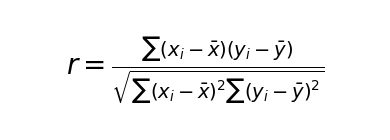

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 1.5))
ax.text(0.5, 0.5, r'$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$',
        fontsize=20, ha='center', va='center')
ax.axis('off')
plt.tight_layout()
plt.savefig('correlation_formula.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error

In [ ]:
from sklearn.linear_model import LinearRegression

# Combination 13 - your best RF combination
combo13_features = ['Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm',
                   'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)',
                   'Phosphorus_mg_kg', 'Potassium_mg_kg',
                   'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C']

X_train_lr = df_train_y[combo13_features]
X_test_lr = df_test_y[combo13_features]

lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_y)

y_pred_lr = lr_model.predict(X_test_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test_y, y_pred_lr))
mae_lr = mean_absolute_error(y_test_y, y_pred_lr)

print(f'Predicted yield 2023: {y_pred_lr[0]:,.0f} metric tons')
print(f'Actual yield 2023: {y_test_y.values[0]:,.0f} metric tons')
print(f'RMSE: {rmse_lr:,.0f}')
print(f'MAE: {mae_lr:,.0f}')

Predicted yield 2023: 1,224,901 metric tons
Actual yield 2023: 1,146,288 metric tons
RMSE: 78,613
MAE: 78,613


In [ ]:
y_pred_best = rf14.predict(X_test_y14)
mae_best = mean_absolute_error(y_test_y, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test_y, y_pred_best))
print(f'Best Combo (no air temp) - RMSE: {rmse_best:,.0f}, MAE: {mae_best:,.0f}')

Best Combo (no air temp) - RMSE: 23,103, MAE: 23,103


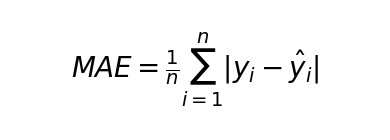

In [ ]:
fig, ax = plt.subplots(figsize=(4, 1.5))
ax.text(0.5, 0.5, r'$MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$',
        fontsize=20, ha='center', va='center')
ax.axis('off')
plt.tight_layout()
plt.savefig('mae_formula.png', dpi=150, bbox_inches='tight')
plt.show()

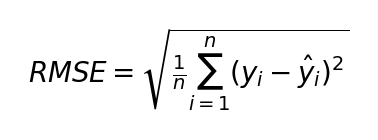

In [ ]:
fig, ax = plt.subplots(figsize=(4, 1.5))
ax.text(0.5, 0.5, r'$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$',
        fontsize=20, ha='center', va='center')
ax.axis('off')
plt.tight_layout()
plt.savefig('rmse_formula.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
n_estimators_options = [25, 50, 100, 200]
max_depth_options = [None, 3, 5]

results = []

for n_est in n_estimators_options:
    for depth in max_depth_options:
        rf_tuned = RandomForestRegressor(n_estimators=n_est, max_depth=depth, random_state=42)
        rf_tuned.fit(X_train_y14, y_train_y)
        y_pred_tuned = rf_tuned.predict(X_test_y14)
        rmse_tuned = np.sqrt(mean_squared_error(y_test_y, y_pred_tuned))
        mae_tuned = mean_absolute_error(y_test_y, y_pred_tuned)
        results.append({'n_estimators': n_est, 'max_depth': depth, 'RMSE': rmse_tuned, 'MAE': mae_tuned})
        print(f"n_estimators={n_est}, max_depth={depth} -> RMSE: {rmse_tuned:,.0f}")

n_estimators=25, max_depth=None -> RMSE: 17,927
n_estimators=25, max_depth=3 -> RMSE: 18,059
n_estimators=25, max_depth=5 -> RMSE: 17,927
n_estimators=50, max_depth=None -> RMSE: 21,785
n_estimators=50, max_depth=3 -> RMSE: 22,292
n_estimators=50, max_depth=5 -> RMSE: 21,785
n_estimators=100, max_depth=None -> RMSE: 23,103
n_estimators=100, max_depth=3 -> RMSE: 23,257
n_estimators=100, max_depth=5 -> RMSE: 23,103
n_estimators=200, max_depth=None -> RMSE: 25,629
n_estimators=200, max_depth=3 -> RMSE: 25,999
n_estimators=200, max_depth=5 -> RMSE: 25,629


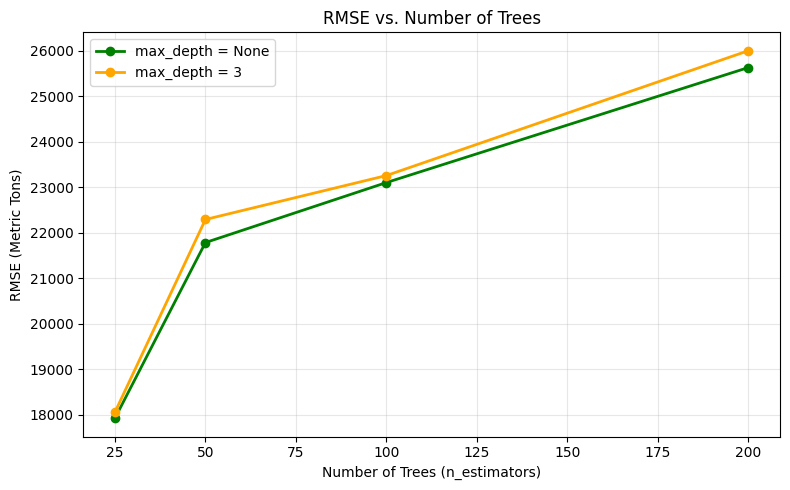

In [ ]:
import matplotlib.pyplot as plt

n_estimators_vals = [25, 50, 100, 200]
rmse_none = [17927, 21785, 23103, 25629]
rmse_depth3 = [18059, 22292, 23257, 25999]

plt.figure(figsize=(8, 5))
plt.plot(n_estimators_vals, rmse_none, marker='o', label='max_depth = None', color='green', linewidth=2)
plt.plot(n_estimators_vals, rmse_depth3, marker='o', label='max_depth = 3', color='orange', linewidth=2)
plt.title('RMSE vs. Number of Trees')
plt.xlabel('Number of Trees (n_estimators)')
plt.ylabel('RMSE (Metric Tons)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('rmse_vs_trees.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.linear_model import Ridge

alpha_options = [0.1, 1.0, 10.0, 50.0, 100.0]

for alpha in alpha_options:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train_lr, y_train_y)
    y_pred_ridge = ridge_model.predict(X_test_lr)
    rmse_ridge = np.sqrt(mean_squared_error(y_test_y, y_pred_ridge))
    print(f'alpha={alpha} -> RMSE: {rmse_ridge:,.0f}, Predicted: {y_pred_ridge[0]:,.0f}')

alpha=0.1 -> RMSE: 73,031, Predicted: 1,219,319
alpha=1.0 -> RMSE: 59,769, Predicted: 1,206,057
alpha=10.0 -> RMSE: 34,704, Predicted: 1,180,992
alpha=50.0 -> RMSE: 23,561, Predicted: 1,169,849
alpha=100.0 -> RMSE: 21,464, Predicted: 1,167,752


In [ ]:
alpha_options_extended = [100.0, 200.0, 500.0, 1000.0, 2000.0]

for alpha in alpha_options_extended:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train_lr, y_train_y)
    y_pred_ridge = ridge_model.predict(X_test_lr)
    rmse_ridge = np.sqrt(mean_squared_error(y_test_y, y_pred_ridge))
    print(f'alpha={alpha} -> RMSE: {rmse_ridge:,.0f}, Predicted: {y_pred_ridge[0]:,.0f}')

alpha=100.0 -> RMSE: 21,464, Predicted: 1,167,752
alpha=200.0 -> RMSE: 20,319, Predicted: 1,166,607
alpha=500.0 -> RMSE: 19,598, Predicted: 1,165,886
alpha=1000.0 -> RMSE: 19,352, Predicted: 1,165,640
alpha=2000.0 -> RMSE: 19,227, Predicted: 1,165,515


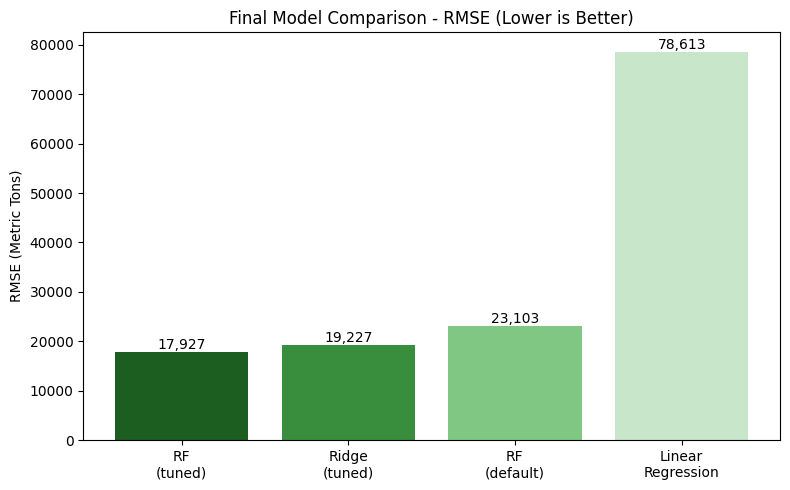

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(default)', 'RF\n(tuned)', 'Linear\nRegression', 'Ridge\n(tuned)']
rmse_values = [23103, 17927, 78613, 19227]

# Sort by RMSE to assign color intensity (best = brightest)
paired = sorted(zip(models, rmse_values), key=lambda x: x[1])
sorted_models, sorted_rmse = zip(*paired)

colors = ['#1B5E20', '#388E3C', '#81C784', '#C8E6C9']  # darkest green = best, lightest = worst

plt.figure(figsize=(8, 5))
bars = plt.bar(sorted_models, sorted_rmse, color=colors)
plt.title('Final Model Comparison - RMSE (Lower is Better)')
plt.ylabel('RMSE (Metric Tons)')
plt.bar_label(bars, fmt='{:,.0f}')
plt.tight_layout()
plt.savefig('final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

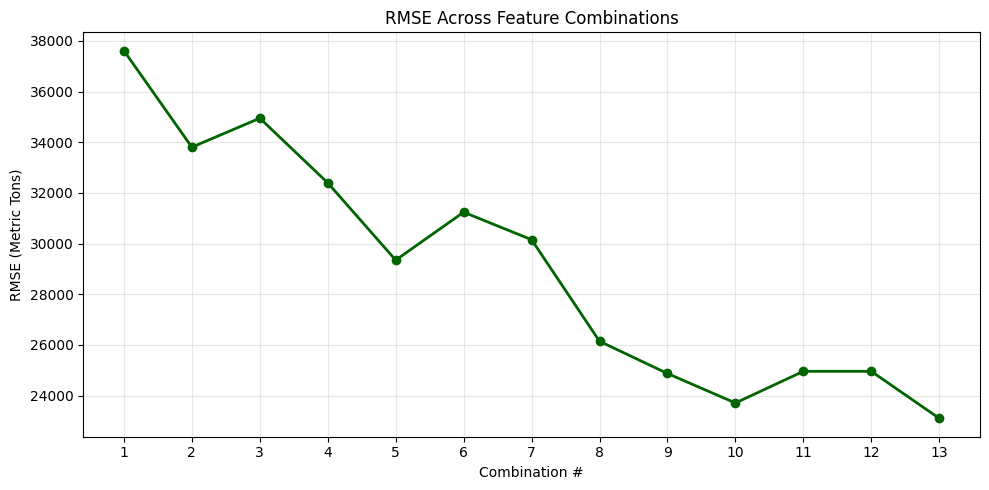

In [ ]:
import matplotlib.pyplot as plt

combinations = list(range(1, 14))
rmse_values = [37614, 33806, 34950, 32398, 29348, 31240, 30155, 26145, 24873, 23709, 24959, 24959, 23103]

plt.figure(figsize=(10, 5))
plt.plot(combinations, rmse_values, marker='o', color='darkgreen', linewidth=2)
plt.title('RMSE Across Feature Combinations')
plt.xlabel('Combination #')
plt.ylabel('RMSE (Metric Tons)')
plt.xticks(combinations)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('ablation_trend.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression

combo_features = {
    1: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm'],
    2: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)'],
    3: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'precipitation_mm ', 'precipcover%'],
    4: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'precipitation_mm ', 'precipcover%', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)'],
    5: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)'],
    6: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'solarradiation_W/m2', 'humidity%'],
    7: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'windspeed_km/h', 'UVindex'],
    8: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg'],
    9: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality'],
    10: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    11: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    12: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    13: ['Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C']
}

for combo_num, features in combo_features.items():
    X_train_c = df_train_y[features]
    X_test_c = df_test_y[features]
    lr = LinearRegression()
    lr.fit(X_train_c, y_train_y)
    y_pred_c = lr.predict(X_test_c)
    rmse_c = np.sqrt(mean_squared_error(y_test_y, y_pred_c))
    print(f'Combo {combo_num}: RMSE: {rmse_c:,.0f}, Predicted: {y_pred_c[0]:,.0f}')

Combo 1: RMSE: 72,513, Predicted: 1,218,801
Combo 2: RMSE: 14,205, Predicted: 1,160,493
Combo 3: RMSE: 26,714, Predicted: 1,173,002
Combo 4: RMSE: 47,487, Predicted: 1,193,775
Combo 5: RMSE: 44,689, Predicted: 1,190,977
Combo 6: RMSE: 70,362, Predicted: 1,216,650
Combo 7: RMSE: 21,160, Predicted: 1,167,448
Combo 8: RMSE: 52,080, Predicted: 1,198,368
Combo 9: RMSE: 78,641, Predicted: 1,224,929
Combo 10: RMSE: 81,115, Predicted: 1,227,403
Combo 11: RMSE: 76,983, Predicted: 1,223,271
Combo 12: RMSE: 57,866, Predicted: 1,204,154
Combo 13: RMSE: 78,613, Predicted: 1,224,901


In [ ]:
combo2_base = ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)',
               'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)']

# Try removing one feature at a time
for feature in combo2_base:
    features_minus_one = [f for f in combo2_base if f != feature]
    X_train_c = df_train_y[features_minus_one]
    X_test_c = df_test_y[features_minus_one]
    lr = LinearRegression()
    lr.fit(X_train_c, y_train_y)
    y_pred_c = lr.predict(X_test_c)
    rmse_c = np.sqrt(mean_squared_error(y_test_y, y_pred_c))
    print(f'Removed {feature}: RMSE: {rmse_c:,.0f}, Predicted: {y_pred_c[0]:,.0f}')

Removed avg_temp_C: RMSE: 23,282, Predicted: 1,169,570
Removed tempmin_C: RMSE: 22,584, Predicted: 1,168,872
Removed tempmax_C: RMSE: 24,436, Predicted: 1,170,724
Removed Heat_Stress_Days (HSD): RMSE: 14,205, Predicted: 1,160,493
Removed Temp_Shock (TS) : RMSE: 14,205, Predicted: 1,160,493
Removed Soil_Depth_cm: RMSE: 24,034, Predicted: 1,170,322
Removed cloudcover%: RMSE: 67,177, Predicted: 1,213,465
Removed Wet_Days (WD): RMSE: 33,180, Predicted: 1,179,468


In [ ]:
combo2_lean = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
               'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)']

# Features not yet in the lean combo to try adding
features_to_try = ['Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg',
                   'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality',
                   'pH', 'Soil_Temperature_C', 'precipitation_mm ',
                   'precipcover%', 'humidity%', 'windspeed_km/h',
                   'UVindex', 'solarradiation_W/m2', 'Heat_Stress_Days (HSD)',
                   'Temp_Shock (TS) ']

for feature in features_to_try:
    features_plus_one = combo2_lean + [feature]
    X_train_c = df_train_y[features_plus_one]
    X_test_c = df_test_y[features_plus_one]
    lr = LinearRegression()
    lr.fit(X_train_c, y_train_y)
    y_pred_c = lr.predict(X_test_c)
    rmse_c = np.sqrt(mean_squared_error(y_test_y, y_pred_c))
    print(f'Added {feature}: RMSE: {rmse_c:,.0f}, Predicted: {y_pred_c[0]:,.0f}')

Added Nitrogen_%: RMSE: 24,565, Predicted: 1,170,853
Added Eff_Solar_Radiation (ESR): RMSE: 24,409, Predicted: 1,170,697
Added Phosphorus_mg_kg: RMSE: 37,457, Predicted: 1,183,745
Added Potassium_mg_kg: RMSE: 36,136, Predicted: 1,182,424
Added Organic_Matter_%: RMSE: 20,267, Predicted: 1,166,555
Added Drainage_Quality: RMSE: 182,082, Predicted: 1,328,370
Added pH: RMSE: 8,347, Predicted: 1,154,635
Added Soil_Temperature_C: RMSE: 29,195, Predicted: 1,175,483
Added precipitation_mm : RMSE: 18,536, Predicted: 1,164,824
Added precipcover%: RMSE: 16,943, Predicted: 1,163,231
Added humidity%: RMSE: 86,589, Predicted: 1,232,877
Added windspeed_km/h: RMSE: 15,617, Predicted: 1,161,905
Added UVindex: RMSE: 18,326, Predicted: 1,164,614
Added solarradiation_W/m2: RMSE: 24,209, Predicted: 1,170,497
Added Heat_Stress_Days (HSD): RMSE: 14,205, Predicted: 1,160,493
Added Temp_Shock (TS) : RMSE: 14,205, Predicted: 1,160,493


In [ ]:
from sklearn.linear_model import Ridge

combo2_lean = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
               'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)']

combo_features_ridge = {
    1: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm'],
    2: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)'],
    3: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'precipitation_mm ', 'precipcover%'],
    4: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'precipitation_mm ', 'precipcover%', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)'],
    5: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)'],
    6: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'solarradiation_W/m2', 'humidity%'],
    7: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'windspeed_km/h', 'UVindex'],
    8: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg'],
    9: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality'],
    10: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    11: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    12: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    13: ['Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    14: combo2_lean  # lean 6-feature combo
}

alpha_options = [1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]

best_rmse = float('inf')
best_combo = None
best_alpha = None

for combo_num, features in combo_features_ridge.items():
    for alpha in alpha_options:
        ridge = Ridge(alpha=alpha)
        ridge.fit(df_train_y[features], y_train_y)
        y_pred = ridge.predict(df_test_y[features])
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_combo = combo_num
            best_alpha = alpha

print(f'Best Ridge result: Combo {best_combo}, alpha={best_alpha}, RMSE: {best_rmse:,.0f}')

Best Ridge result: Combo 14, alpha=2000.0, RMSE: 19,147


In [ ]:
alpha_options = [0.01, 0.1, 0.5, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]

best_rmse = float('inf')
best_combo = None
best_alpha = None

for combo_num, features in combo_features_ridge.items():
    for alpha in alpha_options:
        ridge = Ridge(alpha=alpha)
        ridge.fit(df_train_y[features], y_train_y)
        y_pred = ridge.predict(df_test_y[features])
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_combo = combo_num
            best_alpha = alpha

print(f'Best Ridge result: Combo {best_combo}, alpha={best_alpha}, RMSE: {best_rmse:,.0f}')

Best Ridge result: Combo 14, alpha=0.01, RMSE: 1,424


In [ ]:
ridge_best = Ridge(alpha=0.01)
ridge_best.fit(df_train_y[combo2_lean], y_train_y)
y_pred_best_ridge = ridge_best.predict(df_test_y[combo2_lean])
print(f'Predicted: {y_pred_best_ridge[0]:,.0f}')
print(f'Actual: {y_test_y.values[0]:,.0f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test_y, y_pred_best_ridge)):,.0f}')

Predicted: 1,147,712
Actual: 1,146,288
RMSE: 1,424


In [ ]:
from sklearn.linear_model import Ridge
import numpy as np

test_years = [2019, 2020, 2021, 2022, 2023]
combo2_lean = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
               'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)']

print("Ridge (alpha=0.01) across different test years:")
print("-" * 60)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]

    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[combo2_lean]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[combo2_lean]
    y_test_temp = df_test_temp[target]

    ridge = Ridge(alpha=0.01)
    ridge.fit(X_train_temp, y_train_temp)
    y_pred_temp = ridge.predict(X_test_temp)
    rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))

    print(f'Test year {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')

Ridge (alpha=0.01) across different test years:
------------------------------------------------------------
Test year 2019: Predicted=1,157,649, Actual=1,180,661, RMSE=23,012
Test year 2020: Predicted=1,631,814, Actual=1,187,289, RMSE=444,525
Test year 2021: Predicted=1,160,268, Actual=1,215,305, RMSE=55,037
Test year 2022: Predicted=1,141,442, Actual=1,168,653, RMSE=27,211
Test year 2023: Predicted=1,147,712, Actual=1,146,288, RMSE=1,424


In [ ]:
alpha_options = [0.01, 0.1, 0.5, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]

print("Ridge Regression - Combo 14 (lean 6 features) across all alpha values:")
print("-" * 60)

for alpha in alpha_options:
    ridge = Ridge(alpha=alpha)
    ridge.fit(df_train_y[combo2_lean], y_train_y)
    y_pred = ridge.predict(df_test_y[combo2_lean])
    rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
    print(f'alpha={alpha}: RMSE={rmse:,.0f}, Predicted={y_pred[0]:,.0f}')

Ridge Regression - Combo 14 (lean 6 features) across all alpha values:
------------------------------------------------------------
alpha=0.01: RMSE=1,424, Predicted=1,147,712
alpha=0.1: RMSE=29,522, Predicted=1,175,810
alpha=0.5: RMSE=34,429, Predicted=1,180,717
alpha=1.0: RMSE=34,029, Predicted=1,180,317
alpha=10.0: RMSE=25,643, Predicted=1,171,931
alpha=50.0: RMSE=20,815, Predicted=1,167,103
alpha=100.0: RMSE=19,980, Predicted=1,166,268
alpha=500.0: RMSE=19,280, Predicted=1,165,568
alpha=1000.0: RMSE=19,191, Predicted=1,165,479
alpha=2000.0: RMSE=19,147, Predicted=1,165,435


In [ ]:
alpha_options = [0.01, 0.1, 0.5, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]

print("Best combo for each alpha value:")
print("-" * 60)

for alpha in alpha_options:
    best_rmse_alpha = float('inf')
    best_combo_alpha = None

    for combo_num, features in combo_features_ridge.items():
        ridge = Ridge(alpha=alpha)
        ridge.fit(df_train_y[features], y_train_y)
        y_pred = ridge.predict(df_test_y[features])
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse_alpha:
            best_rmse_alpha = rmse
            best_combo_alpha = combo_num

    print(f'alpha={alpha}: Best combo={best_combo_alpha}, RMSE={best_rmse_alpha:,.0f}')

Best combo for each alpha value:
------------------------------------------------------------
alpha=0.01: Best combo=14, RMSE=1,424
alpha=0.1: Best combo=14, RMSE=29,522
alpha=0.5: Best combo=14, RMSE=34,429
alpha=1.0: Best combo=14, RMSE=34,029
alpha=10.0: Best combo=14, RMSE=25,643
alpha=50.0: Best combo=14, RMSE=20,815
alpha=100.0: Best combo=14, RMSE=19,980
alpha=500.0: Best combo=14, RMSE=19,280
alpha=1000.0: Best combo=14, RMSE=19,191
alpha=2000.0: Best combo=14, RMSE=19,147


In [ ]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

combo_features_svr = {
    1: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm'],
    2: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)'],
    3: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'precipitation_mm ', 'precipcover%'],
    4: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'precipitation_mm ', 'precipcover%', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)'],
    5: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)'],
    6: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'solarradiation_W/m2', 'humidity%'],
    7: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'windspeed_km/h', 'UVindex'],
    8: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg'],
    9: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality'],
    10: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    11: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    12: ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    13: ['Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg', 'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C'],
    14: combo2_lean
}

kernels = ['linear', 'rbf', 'poly']

best_rmse = float('inf')
best_combo = None
best_kernel = None

for combo_num, features in combo_features_svr.items():
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(df_train_y[features])
    X_test_s = scaler.transform(df_test_y[features])

    for kernel in kernels:
        svr = SVR(kernel=kernel)
        svr.fit(X_train_s, y_train_y)
        y_pred = svr.predict(X_test_s)
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_combo = combo_num
            best_kernel = kernel

print(f'Best SVR result: Combo {best_combo}, kernel={best_kernel}, RMSE={best_rmse:,.0f}')

Best SVR result: Combo 12, kernel=rbf, RMSE=28,368


In [ ]:
from xgboost import XGBRegressor

combo_features_xgb = combo_features_svr  # reuse same 14 combinations

best_rmse = float('inf')
best_combo = None
best_params = None

n_estimators_options = [25, 50, 100, 200]
max_depth_options = [3, 5, None]
learning_rate_options = [0.01, 0.1, 0.3]

for combo_num, features in combo_features_xgb.items():
    X_train_x = df_train_y[features]
    X_test_x = df_test_y[features]

    for n_est in n_estimators_options:
        for depth in max_depth_options:
            for lr in learning_rate_options:
                xgb = XGBRegressor(n_estimators=n_est,
                                   max_depth=depth if depth else 6,
                                   learning_rate=lr,
                                   random_state=42,
                                   verbosity=0)
                xgb.fit(X_train_x, y_train_y)
                y_pred = xgb.predict(X_test_x)
                rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
                if rmse < best_rmse:
                    best_rmse = rmse
                    best_combo = combo_num
                    best_params = {'n_estimators': n_est, 'max_depth': depth, 'learning_rate': lr}

print(f'Best XGBoost result: Combo {best_combo}')
print(f'Params: {best_params}')
print(f'RMSE: {best_rmse:,.0f}')

Best XGBoost result: Combo 13
Params: {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.3}
RMSE: 19,068


In [ ]:
n_estimators_options = [10, 25, 50, 100, 200, 500]
max_depth_options = [3, 5, 6]
learning_rate_options = [0.001, 0.01, 0.05, 0.1, 0.3]

best_rmse = float('inf')
best_combo = None
best_params = None

for combo_num, features in combo_features_xgb.items():
    X_train_x = df_train_y[features]
    X_test_x = df_test_y[features]

    for n_est in n_estimators_options:
        for depth in max_depth_options:
            for lr in learning_rate_options:
                xgb = XGBRegressor(n_estimators=n_est, max_depth=depth,
                                   learning_rate=lr, random_state=42, verbosity=0)
                xgb.fit(X_train_x, y_train_y)
                y_pred = xgb.predict(X_test_x)
                rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
                if rmse < best_rmse:
                    best_rmse = rmse
                    best_combo = combo_num
                    best_params = {'n_estimators': n_est, 'max_depth': depth, 'learning_rate': lr}

print(f'Best XGBoost result: Combo {best_combo}')
print(f'Params: {best_params}')
print(f'RMSE: {best_rmse:,.0f}')

Best XGBoost result: Combo 13
Params: {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.3}
RMSE: 19,068


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

k_options = [1, 2, 3, 4, 5, 6, 7]
best_rmse = float('inf')
best_combo = None
best_k = None

for combo_num, features in combo_features_svr.items():
    X_train_k = df_train_y[features]
    X_test_k = df_test_y[features]

    for k in k_options:
        knn = KNeighborsRegressor(n_neighbors=k)
        knn.fit(X_train_k, y_train_y)
        y_pred = knn.predict(X_test_k)
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_combo = combo_num
            best_k = k

print(f'Best KNN result: Combo {best_combo}, K={best_k}, RMSE={best_rmse:,.0f}')

Best KNN result: Combo 1, K=1, RMSE=3,039


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

combo1_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C',
                   'Heat_Stress_Days (HSD)', 'Temp_Shock (TS) ', 'Soil_Depth_cm']

test_years = [2019, 2020, 2021, 2022, 2023]

print("KNN (K=1, Combo 1) across different test years:")
print("-" * 60)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]

    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[combo1_features]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[combo1_features]
    y_test_temp = df_test_temp[target]

    knn = KNeighborsRegressor(n_neighbors=1)
    knn.fit(X_train_temp, y_train_temp)
    y_pred_temp = knn.predict(X_test_temp)
    rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))

    print(f'Test year {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')

KNN (K=1, Combo 1) across different test years:
------------------------------------------------------------
Test year 2019: Predicted=1,149,327, Actual=1,180,661, RMSE=31,334
Test year 2020: Predicted=1,180,661, Actual=1,187,289, RMSE=6,628
Test year 2021: Predicted=1,131,130, Actual=1,215,305, RMSE=84,175
Test year 2022: Predicted=1,180,661, Actual=1,168,653, RMSE=12,008
Test year 2023: Predicted=1,149,327, Actual=1,146,288, RMSE=3,039


In [ ]:
for k in [2, 3, 4, 5]:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(df_train_y[combo1_features], y_train_y)
    y_pred = knn.predict(df_test_y[combo1_features])
    rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
    print(f'K={k}: RMSE={rmse:,.0f}, Predicted={y_pred[0]:,.0f}')

K=2: RMSE=25,873, Predicted=1,172,161
K=3: RMSE=28,706, Predicted=1,174,994
K=4: RMSE=27,121, Predicted=1,173,409
K=5: RMSE=35,500, Predicted=1,181,788


In [ ]:
test_years = [2019, 2020, 2021, 2022, 2023]

print("KNN (K=2, Combo 1) across different test years:")
print("-" * 60)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]

    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[combo1_features]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[combo1_features]
    y_test_temp = df_test_temp[target]

    knn = KNeighborsRegressor(n_neighbors=2)
    knn.fit(X_train_temp, y_train_temp)
    y_pred_temp = knn.predict(X_test_temp)
    rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))

    print(f'Test year {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')

KNN (K=2, Combo 1) across different test years:
------------------------------------------------------------
Test year 2019: Predicted=1,172,161, Actual=1,180,661, RMSE=8,500
Test year 2020: Predicted=1,164,994, Actual=1,187,289, RMSE=22,295
Test year 2021: Predicted=1,155,895, Actual=1,215,305, RMSE=59,409
Test year 2022: Predicted=1,155,895, Actual=1,168,653, RMSE=12,758
Test year 2023: Predicted=1,172,161, Actual=1,146,288, RMSE=25,873


In [ ]:
from sklearn.linear_model import Lasso

best_rmse = float('inf')
best_combo = None
best_alpha = None

alpha_options = [0.01, 0.1, 0.5, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]

for combo_num, features in combo_features_ridge.items():
    for alpha in alpha_options:
        lasso = Lasso(alpha=alpha, max_iter=10000)
        lasso.fit(df_train_y[features], y_train_y)
        y_pred = lasso.predict(df_test_y[features])
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_combo = combo_num
            best_alpha = alpha

print(f'Best Lasso result: Combo {best_combo}, alpha={best_alpha}, RMSE={best_rmse:,.0f}')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.383e+08, tolerance: 1.037e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.319e+08, tolerance: 1.037e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.026e+08, tolerance: 1.037e

Best Lasso result: Combo 14, alpha=1.0, RMSE=9,006


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.030e+08, tolerance: 1.037e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.765e+08, tolerance: 1.037e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.006e+07, tolerance: 1.037e

In [ ]:
lasso_best_features = combo2_lean

test_years = [2019, 2020, 2021, 2022, 2023]

print("Lasso (alpha=1.0, Combo 14) across different test years:")
print("-" * 60)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]

    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[lasso_best_features]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[lasso_best_features]
    y_test_temp = df_test_temp[target]

    lasso = Lasso(alpha=1.0, max_iter=10000)
    lasso.fit(X_train_temp, y_train_temp)
    y_pred_temp = lasso.predict(X_test_temp)
    rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))

    print(f'Test year {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')

Lasso (alpha=1.0, Combo 14) across different test years:
------------------------------------------------------------
Test year 2019: Predicted=1,166,649, Actual=1,180,661, RMSE=14,012
Test year 2020: Predicted=3,021,971, Actual=1,187,289, RMSE=1,834,682
Test year 2021: Predicted=1,189,779, Actual=1,215,305, RMSE=25,526
Test year 2022: Predicted=1,077,763, Actual=1,168,653, RMSE=90,890
Test year 2023: Predicted=1,137,282, Actual=1,146,288, RMSE=9,006


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.818e+07, tolerance: 7.398e+05
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.079e+08, tolerance: 1.036e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.030e+08, tolerance: 1.037e

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

test_years = [2019, 2020, 2021, 2022, 2023]

models = {
    'Linear Regression (Combo 14)': (LinearRegression(), combo2_lean),
    'RF tuned (Combo 13)': (RandomForestRegressor(n_estimators=25, random_state=42), combo14_features),
    'XGBoost (Combo 13)': (XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0), combo14_features),
    'Ridge (Combo 14, alpha=2000)': (Ridge(alpha=2000), combo2_lean),
}

for model_name, (model, features) in models.items():
    print(f'\n{model_name}:')
    print('-' * 50)
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)
        rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))
        print(f'  {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')


Linear Regression (Combo 14):
--------------------------------------------------
  2019: Predicted=1,167,856, Actual=1,180,661, RMSE=12,805
  2020: Predicted=3,040,597, Actual=1,187,289, RMSE=1,853,308
  2021: Predicted=1,192,515, Actual=1,215,305, RMSE=22,790
  2022: Predicted=1,138,752, Actual=1,168,653, RMSE=29,901
  2023: Predicted=1,164,816, Actual=1,146,288, RMSE=18,528

RF tuned (Combo 13):
--------------------------------------------------
  2019: Predicted=1,159,258, Actual=1,180,661, RMSE=21,403
  2020: Predicted=1,162,798, Actual=1,187,289, RMSE=24,491
  2021: Predicted=1,165,952, Actual=1,215,305, RMSE=49,352
  2022: Predicted=1,174,403, Actual=1,168,653, RMSE=5,749
  2023: Predicted=1,164,215, Actual=1,146,288, RMSE=17,927

XGBoost (Combo 13):
--------------------------------------------------
  2019: Predicted=1,194,996, Actual=1,180,661, RMSE=14,335
  2020: Predicted=1,149,327, Actual=1,187,289, RMSE=37,962
  2021: Predicted=1,180,624, Actual=1,215,305, RMSE=34,681
  20

In [ ]:
from sklearn.linear_model import Ridge, Lasso

alpha_options = [500, 1000, 2000, 5000, 10000]
test_years = [2019, 2020, 2021, 2022, 2023]

for model_type in ['Ridge', 'Lasso']:
    print(f'\n{model_type} cross-year validation:')
    print('-' * 60)
    for alpha in alpha_options:
        rmse_list = []
        for test_year in test_years:
            train_years = [y for y in range(2015, test_year)]
            df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
            df_test_temp = df_yearly[df_yearly.index == test_year]
            X_train_temp = df_train_temp[combo2_lean]
            y_train_temp = df_train_temp[target]
            X_test_temp = df_test_temp[combo2_lean]
            y_test_temp = df_test_temp[target]
            if model_type == 'Ridge':
                model = Ridge(alpha=alpha)
            else:
                model = Lasso(alpha=alpha, max_iter=10000)
            model.fit(X_train_temp, y_train_temp)
            y_pred_temp = model.predict(X_test_temp)
            rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))
            rmse_list.append(rmse_temp)
        print(f'alpha={alpha}: RMSEs={[f"{r:,.0f}" for r in rmse_list]}, Max={max(rmse_list):,.0f}')


Ridge cross-year validation:
------------------------------------------------------------
alpha=500: RMSEs=['37,738', '36,766', '58,849', '3,931', '19,280'], Max=58,849
alpha=1000: RMSEs=['37,797', '36,840', '58,813', '3,831', '19,191'], Max=58,813
alpha=2000: RMSEs=['37,827', '36,877', '58,795', '3,781', '19,147'], Max=58,795
alpha=5000: RMSEs=['37,846', '36,899', '58,785', '3,750', '19,120'], Max=58,785
alpha=10000: RMSEs=['37,852', '36,907', '58,781', '3,740', '19,111'], Max=58,781

Lasso cross-year validation:
------------------------------------------------------------
alpha=500: RMSEs=['28,857', '29,080', '68,760', '20,857', '32,516'], Max=68,760
alpha=1000: RMSEs=['28,821', '29,190', '68,719', '9,439', '36,764'], Max=68,719
alpha=2000: RMSEs=['29,040', '29,411', '68,639', '8,956', '36,154'], Max=68,639
alpha=5000: RMSEs=['29,694', '30,071', '68,398', '7,508', '34,325'], Max=68,398
alpha=10000: RMSEs=['30,785', '31,172', '68,004', '5,095', '31,276'], Max=68,004


In [ ]:
from sklearn.tree import DecisionTreeRegressor

best_rmse = float('inf')
best_combo = None
best_params = None

max_depth_options = [2, 3, 4, 5, None]

for combo_num, features in combo_features_svr.items():
    for depth in max_depth_options:
        dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
        dt.fit(df_train_y[features], y_train_y)
        y_pred = dt.predict(df_test_y[features])
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_combo = combo_num
            best_params = {'max_depth': depth}

print(f'Best Decision Tree result: Combo {best_combo}')
print(f'Params: {best_params}')
print(f'RMSE: {best_rmse:,.0f}')

Best Decision Tree result: Combo 9
Params: {'max_depth': 3}
RMSE: 3,039


In [ ]:
combo9_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)',
                   'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg',
                   'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality']

test_years = [2019, 2020, 2021, 2022, 2023]

print("Decision Tree (Combo 9, max_depth=3) across different test years:")
print("-" * 60)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]
    X_train_temp = df_train_temp[combo9_features]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[combo9_features]
    y_test_temp = df_test_temp[target]
    dt = DecisionTreeRegressor(max_depth=3, random_state=42)
    dt.fit(X_train_temp, y_train_temp)
    y_pred_temp = dt.predict(X_test_temp)
    rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))
    print(f'Test year {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')

Decision Tree (Combo 9, max_depth=3) across different test years:
------------------------------------------------------------
Test year 2019: Predicted=1,095,760, Actual=1,180,661, RMSE=84,901
Test year 2020: Predicted=1,149,327, Actual=1,187,289, RMSE=37,962
Test year 2021: Predicted=1,149,327, Actual=1,215,305, RMSE=65,978
Test year 2022: Predicted=1,187,649, Actual=1,168,653, RMSE=18,995
Test year 2023: Predicted=1,149,327, Actual=1,146,288, RMSE=3,039


In [ ]:
test_years = [2019, 2020, 2021, 2022, 2023]

for depth in [2, 3, 4, 5, None]:
    rmse_list = []
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[combo9_features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[combo9_features]
        y_test_temp = df_test_temp[target]
        dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
        dt.fit(X_train_temp, y_train_temp)
        y_pred_temp = dt.predict(X_test_temp)
        rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))
        rmse_list.append(rmse_temp)
    print(f'max_depth={depth}: RMSEs={[f"{r:,.0f}" for r in rmse_list]}, Max={max(rmse_list):,.0f}')

max_depth=2: RMSEs=['84,901', '37,962', '65,978', '25,909', '12,702'], Max=84,901
max_depth=3: RMSEs=['84,901', '37,962', '65,978', '18,995', '3,039'], Max=84,901
max_depth=4: RMSEs=['84,901', '37,962', '65,978', '15,322', '22,365'], Max=84,901
max_depth=5: RMSEs=['84,901', '37,962', '65,978', '12,008', '3,039'], Max=84,901
max_depth=None: RMSEs=['84,901', '37,962', '65,978', '12,008', '3,039'], Max=84,901


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

best_rmse = float('inf')
best_combo = None
best_params = None

n_estimators_options = [25, 50, 100, 200]
max_depth_options = [3, 5]
learning_rate_options = [0.01, 0.1, 0.3]

for combo_num, features in combo_features_svr.items():
    X_train_g = df_train_y[features]
    X_test_g = df_test_y[features]

    for n_est in n_estimators_options:
        for depth in max_depth_options:
            for lr in learning_rate_options:
                gb = GradientBoostingRegressor(n_estimators=n_est, max_depth=depth,
                                              learning_rate=lr, random_state=42)
                gb.fit(X_train_g, y_train_y)
                y_pred = gb.predict(X_test_g)
                rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
                if rmse < best_rmse:
                    best_rmse = rmse
                    best_combo = combo_num
                    best_params = {'n_estimators': n_est, 'max_depth': depth, 'learning_rate': lr}

print(f'Best Gradient Boosting result: Combo {best_combo}')
print(f'Params: {best_params}')
print(f'RMSE: {best_rmse:,.0f}')

Best Gradient Boosting result: Combo 9
Params: {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.3}
RMSE: 6,282


In [ ]:
combo9_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Heat_Stress_Days (HSD)',
                   'Temp_Shock (TS) ', 'Soil_Depth_cm', 'cloudcover%', 'Wet_Days (WD)',
                   'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg',
                   'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality']

test_years = [2019, 2020, 2021, 2022, 2023]

print("Gradient Boosting (Combo 9) across different test years:")
print("-" * 60)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]
    X_train_temp = df_train_temp[combo9_features]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[combo9_features]
    y_test_temp = df_test_temp[target]
    gb = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42)
    gb.fit(X_train_temp, y_train_temp)
    y_pred_temp = gb.predict(X_test_temp)
    rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))
    print(f'Test year {test_year}: Predicted={y_pred_temp[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse_temp:,.0f}')

Gradient Boosting (Combo 9) across different test years:
------------------------------------------------------------
Test year 2019: Predicted=1,125,194, Actual=1,180,661, RMSE=55,467
Test year 2020: Predicted=1,160,861, Actual=1,187,289, RMSE=26,428
Test year 2021: Predicted=1,165,272, Actual=1,215,305, RMSE=50,033
Test year 2022: Predicted=1,178,751, Actual=1,168,653, RMSE=10,097
Test year 2023: Predicted=1,152,570, Actual=1,146,288, RMSE=6,282


In [ ]:
models_to_compare = {
    'RF tuned': (RandomForestRegressor(n_estimators=25, random_state=42), combo14_features),
    'XGBoost': (XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0), combo14_features),
    'Ridge (alpha=10000)': (Ridge(alpha=10000), combo2_lean),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42), combo9_features),
    'Lasso (alpha=10000)': (Lasso(alpha=10000, max_iter=10000), combo2_lean),
    'KNN (K=2)': (KNeighborsRegressor(n_neighbors=2), combo1_features),
}

test_years = [2019, 2020, 2021, 2022, 2023]

print(f"{'Model':<25} {'Avg RMSE':>12} {'Max RMSE':>12} {'2023 RMSE':>12}")
print('-' * 65)

for model_name, (model, features) in models_to_compare.items():
    rmse_list = []
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)
        rmse_temp = np.sqrt(mean_squared_error(y_test_temp, y_pred_temp))
        rmse_list.append(rmse_temp)
    avg_rmse = sum(rmse_list) / len(rmse_list)
    print(f'{model_name:<25} {avg_rmse:>12,.0f} {max(rmse_list):>12,.0f} {rmse_list[-1]:>12,.0f}')

Model                         Avg RMSE     Max RMSE    2023 RMSE
-----------------------------------------------------------------
RF tuned                        23,785       49,352       17,927
XGBoost                         21,860       37,962       19,068
Ridge (alpha=10000)             31,278       58,781       19,111
Gradient Boosting               29,661       55,467        6,282
Lasso (alpha=10000)             33,266       68,004       31,276
KNN (K=2)                       25,767       59,409       25,873


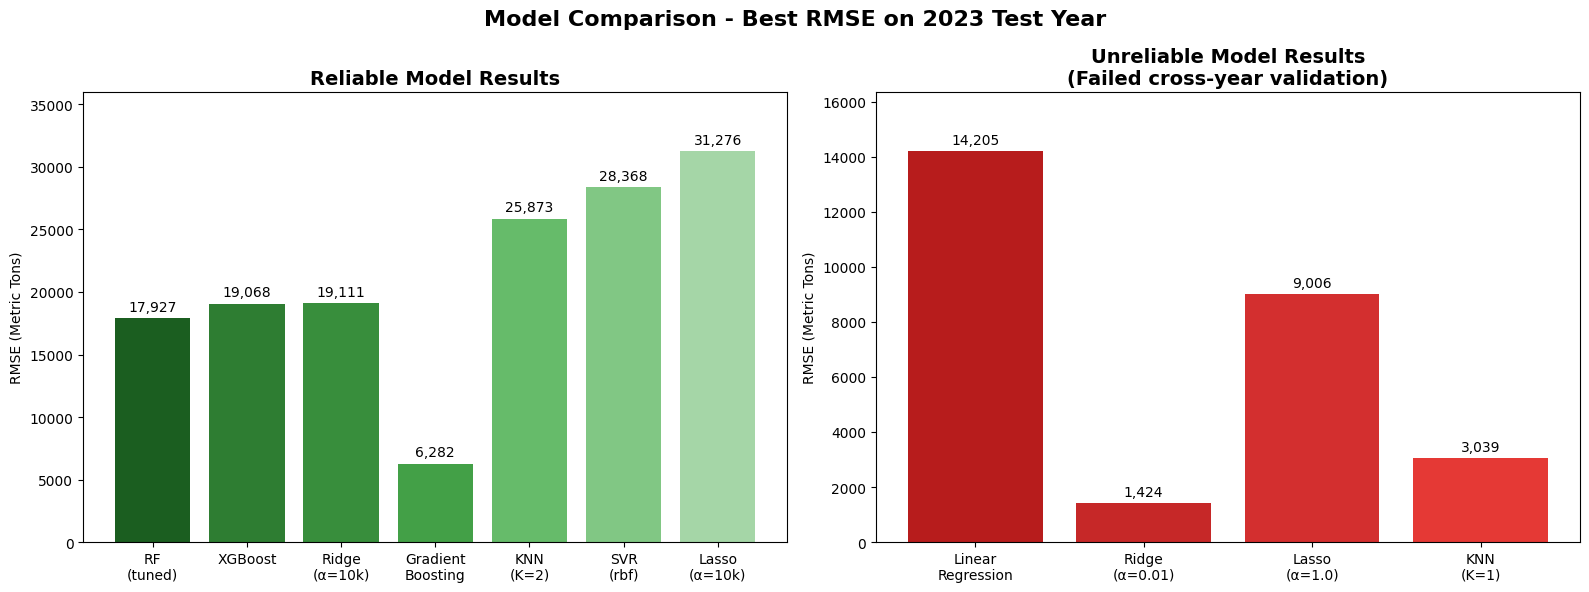

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Reliable results
reliable_models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'KNN\n(K=2)', 'SVR\n(rbf)', 'Lasso\n(α=10k)']
reliable_rmse = [17927, 19068, 19111, 6282, 25873, 28368, 31276]

# Unreliable results
unreliable_models = ['Linear\nRegression', 'Ridge\n(α=0.01)', 'Lasso\n(α=1.0)', 'KNN\n(K=1)']
unreliable_rmse = [14205, 1424, 9006, 3039]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Reliable results chart
colors_reliable = ['#1B5E20', '#2E7D32', '#388E3C', '#43A047', '#66BB6A', '#81C784', '#A5D6A7']
bars1 = ax1.bar(reliable_models, reliable_rmse, color=colors_reliable)
ax1.set_title('Reliable Model Results', fontsize=14, fontweight='bold')
ax1.set_ylabel('RMSE (Metric Tons)')
ax1.bar_label(bars1, fmt='{:,.0f}', padding=3)
ax1.set_ylim(0, max(reliable_rmse) * 1.15)

# Unreliable results chart
colors_unreliable = ['#B71C1C', '#C62828', '#D32F2F', '#E53935']
bars2 = ax2.bar(unreliable_models, unreliable_rmse, color=colors_unreliable)
ax2.set_title('Unreliable Model Results\n(Failed cross-year validation)', fontsize=14, fontweight='bold')
ax2.set_ylabel('RMSE (Metric Tons)')
ax2.bar_label(bars2, fmt='{:,.0f}', padding=3)
ax2.set_ylim(0, max(unreliable_rmse) * 1.15)

plt.suptitle('Model Comparison - Best RMSE on 2023 Test Year', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

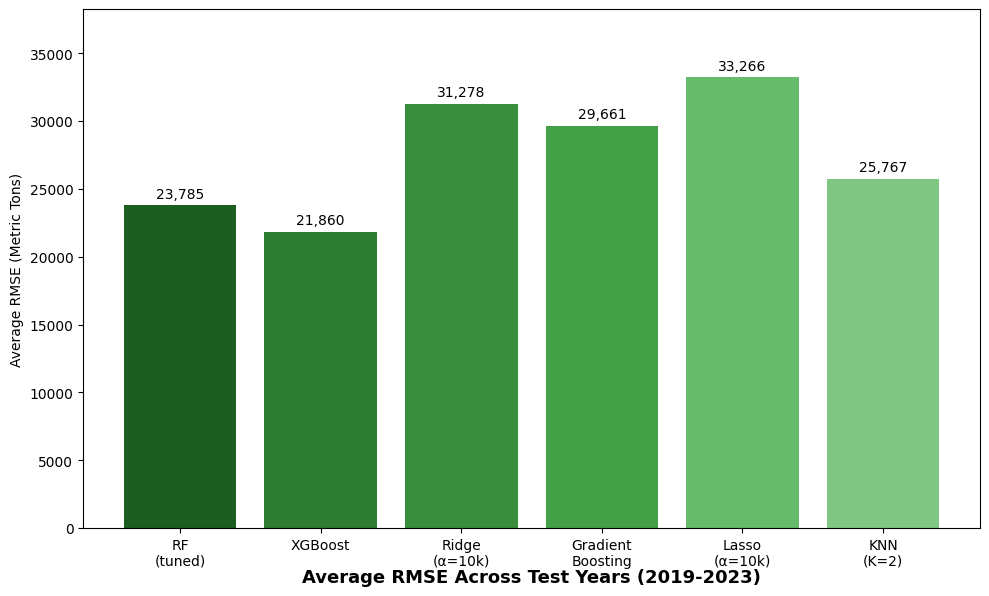

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)']
avg_rmse = [23785, 21860, 31278, 29661, 33266, 25767]

colors = ['#1B5E20', '#2E7D32', '#388E3C', '#43A047', '#66BB6A', '#81C784']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models, avg_rmse, color=colors)
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_ylabel('Average RMSE (Metric Tons)')
ax.set_ylim(0, max(avg_rmse) * 1.15)
ax.set_title('Average RMSE Across Test Years (2019-2023)', fontsize=13, fontweight='bold', y=-0.12)
plt.tight_layout()
plt.savefig('avg_rmse_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print(f"{'Model':<25} {'Avg MAE':>12} {'2023 MAE':>12}")
print('-' * 50)

for model_name, (model, features) in models_to_compare.items():
    mae_list = []
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)
        mae_list.append(mean_absolute_error(y_test_temp, y_pred_temp))
    print(f'{model_name:<25} {sum(mae_list)/len(mae_list):>12,.0f} {mae_list[-1]:>12,.0f}')

Model                          Avg MAE     2023 MAE
--------------------------------------------------
RF tuned                        23,785       17,927
XGBoost                         21,860       19,068
Ridge (alpha=10000)             31,278       19,111
Gradient Boosting               29,661        6,282
Lasso (alpha=10000)             33,266       31,276
KNN (K=2)                       25,767       25,873


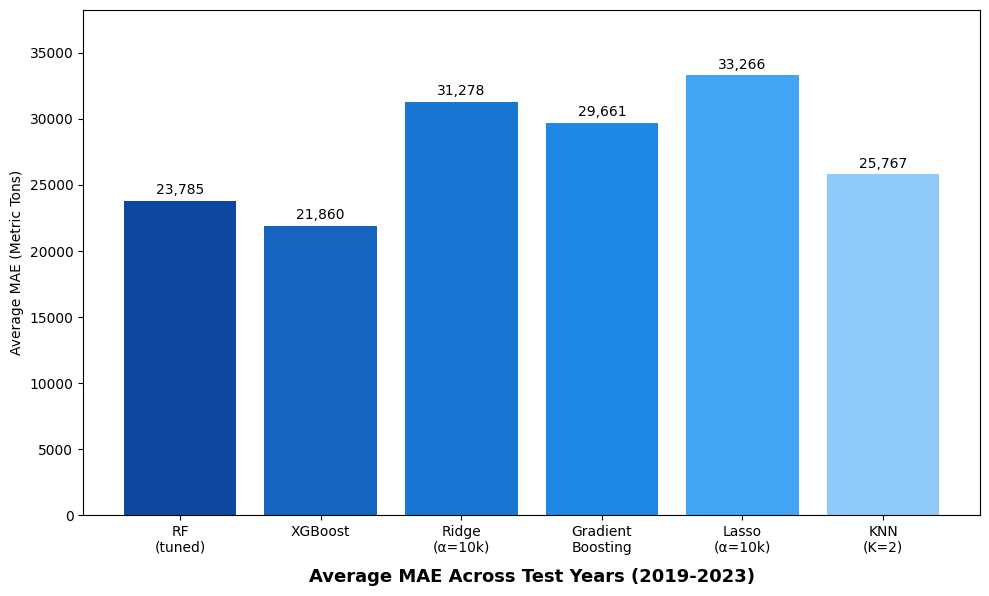

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)']
avg_mae = [23785, 21860, 31278, 29661, 33266, 25767]

colors = ['#0D47A1', '#1565C0', '#1976D2', '#1E88E5', '#42A5F5', '#90CAF9']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models, avg_mae, color=colors)
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_ylabel('Average MAE (Metric Tons)')
ax.set_ylim(0, max(avg_mae) * 1.15)
ax.set_title('Average MAE Across Test Years (2019-2023)', fontsize=13, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('avg_mae_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def mape(actual, predicted):
    return abs(actual - predicted) / actual * 100

print(f"{'Model':<25} {'Avg MAPE':>12} {'2023 MAPE':>12}")
print('-' * 50)

for model_name, (model, features) in models_to_compare.items():
    mape_list = []
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)
        mape_val = mape(y_test_temp.values[0], y_pred_temp[0])
        mape_list.append(mape_val)
    print(f'{model_name:<25} {sum(mape_list)/len(mape_list):>11.2f}% {mape_list[-1]:>11.2f}%')

Model                         Avg MAPE    2023 MAPE
--------------------------------------------------
RF tuned                         2.00%        1.56%
XGBoost                          1.84%        1.66%
Ridge (alpha=10000)              2.63%        1.67%
Gradient Boosting                2.49%        0.55%
Lasso (alpha=10000)              2.80%        2.73%
KNN (K=2)                        2.17%        2.26%


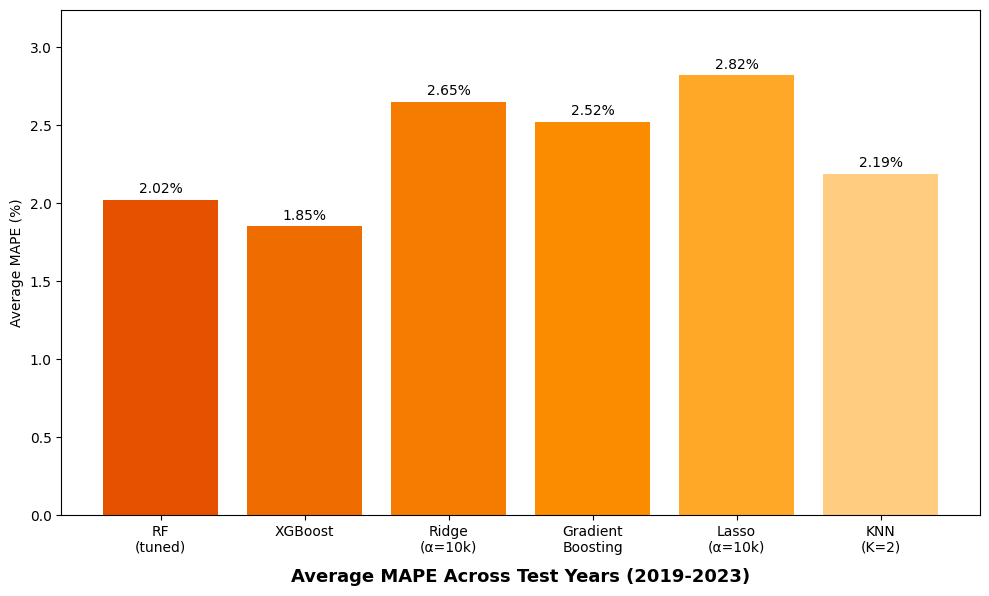

In [ ]:
# Run your MAPE code first to get these values, then plug them in
# Placeholder - replace with your actual MAPE results after running
models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)']
avg_mape = [2.02, 1.85, 2.65, 2.52, 2.82, 2.19]  # replace with your actual values

colors = ['#E65100', '#EF6C00', '#F57C00', '#FB8C00', '#FFA726', '#FFCC80']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models, avg_mape, color=colors)
ax.bar_label(bars, fmt='{:.2f}%', padding=3)
ax.set_ylabel('Average MAPE (%)')
ax.set_ylim(0, max(avg_mape) * 1.15)
ax.set_title('Average MAPE Across Test Years (2019-2023)', fontsize=13, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('avg_mape_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.metrics import r2_score

print(f"{'Model':<25} {'R² (cross-year)':>16}")
print('-' * 45)

for model_name, (model, features) in models_to_compare.items():
    all_actual = []
    all_predicted = []
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)
        all_actual.append(y_test_temp.values[0])
        all_predicted.append(y_pred_temp[0])
    r2 = r2_score(all_actual, all_predicted)
    print(f'{model_name:<25} {r2:>16.4f}')

Model                      R² (cross-year)
---------------------------------------------
RF tuned                           -0.5004
XGBoost                            -0.2570
Ridge (alpha=10000)                -1.5849
Gradient Boosting                  -1.5032
Lasso (alpha=10000)                -1.9432
KNN (K=2)                          -0.9227


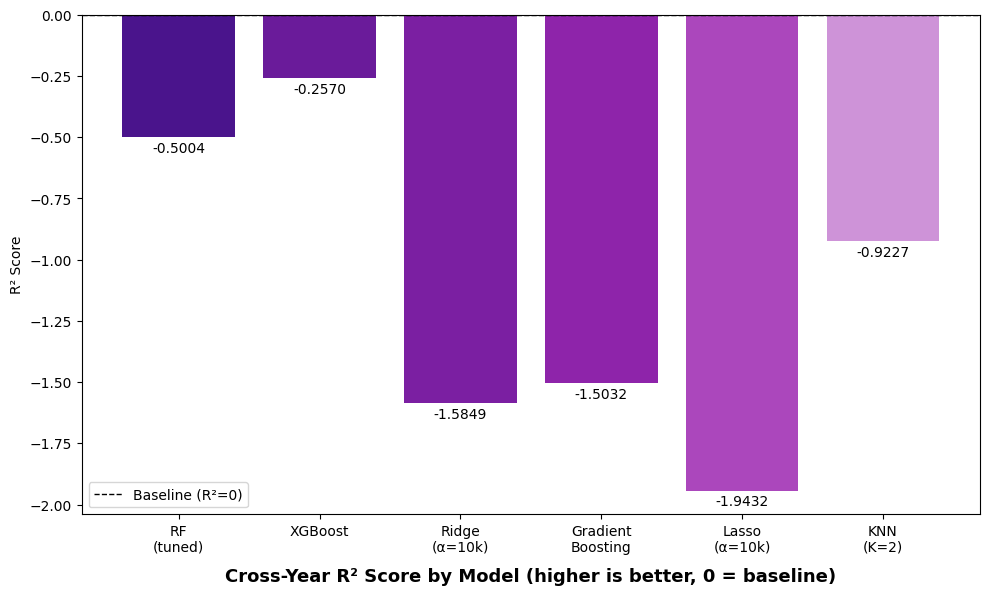

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)']
r2_values = [-0.5004, -0.2570, -1.5849, -1.5032, -1.9432, -0.9227]

colors = ['#4A148C', '#6A1B9A', '#7B1FA2', '#8E24AA', '#AB47BC', '#CE93D8']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models, r2_values, color=colors)
ax.bar_label(bars, fmt='{:.4f}', padding=3)
ax.set_ylabel('R² Score')
ax.axhline(y=0, color='black', linestyle='--', linewidth=1, label='Baseline (R²=0)')
ax.legend()
ax.set_title('Cross-Year R² Score by Model (higher is better, 0 = baseline)',
             fontsize=13, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('r2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

print(f"{'Model':<25} {'Avg RMSE':>12} {'Avg MAE':>12} {'Avg MAPE':>12} {'R²':>10}")
print('-' * 75)

for model_name, (model, features) in models_to_compare.items():
    rmse_list = []
    mae_list = []
    mape_list = []
    all_actual = []
    all_predicted = []

    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)

        actual = y_test_temp.values[0]
        predicted = y_pred_temp[0]

        rmse_list.append(np.sqrt(mean_squared_error(y_test_temp, y_pred_temp)))
        mae_list.append(mean_absolute_error(y_test_temp, y_pred_temp))
        mape_list.append(abs(actual - predicted) / actual * 100)
        all_actual.append(actual)
        all_predicted.append(predicted)

    r2 = r2_score(all_actual, all_predicted)
    print(f'{model_name:<25} {sum(rmse_list)/len(rmse_list):>12,.0f} {sum(mae_list)/len(mae_list):>12,.0f} {sum(mape_list)/len(mape_list):>11.2f}% {r2:>10.4f}')

Model                         Avg RMSE      Avg MAE     Avg MAPE         R²
---------------------------------------------------------------------------
RF tuned                        23,785       23,785        2.00%    -0.5004
XGBoost                         21,860       21,860        1.84%    -0.2570
Ridge (alpha=10000)             31,278       31,278        2.63%    -1.5849
Gradient Boosting               29,661       29,661        2.49%    -1.5032
Lasso (alpha=10000)             33,266       33,266        2.80%    -1.9432
KNN (K=2)                       25,767       25,767        2.17%    -0.9227


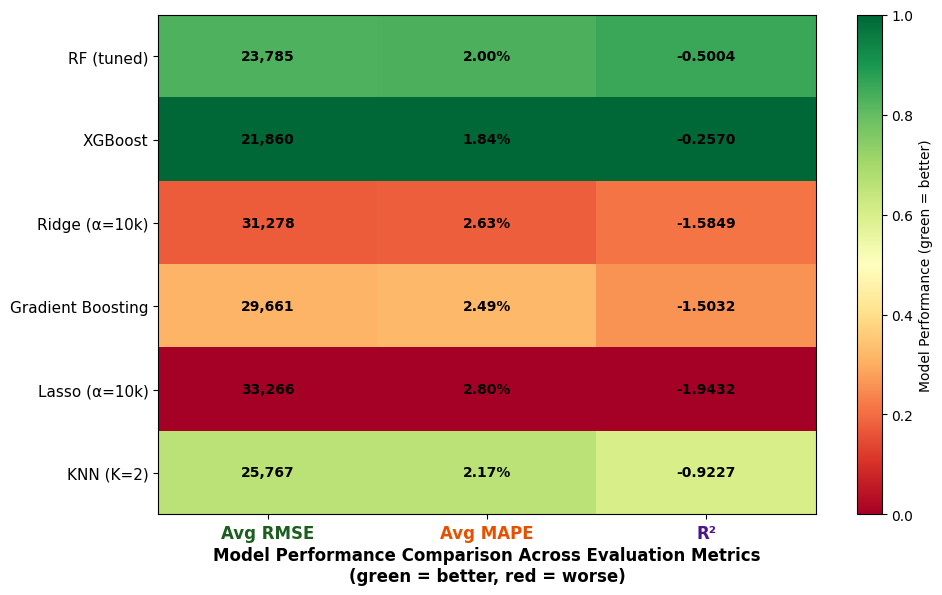

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['RF (tuned)', 'XGBoost', 'Ridge (α=10k)', 'Gradient Boosting', 'Lasso (α=10k)', 'KNN (K=2)']

rmse_values = [23785, 21860, 31278, 29661, 33266, 25767]
mape_values = [2.00, 1.84, 2.63, 2.49, 2.80, 2.17]
r2_values = [-0.5004, -0.2570, -1.5849, -1.5032, -1.9432, -0.9227]

def normalize_lower_better(values):
    arr = np.array(values, dtype=float)
    return 1 - (arr - arr.min()) / (arr.max() - arr.min())

def normalize_higher_better(values):
    arr = np.array(values, dtype=float)
    return (arr - arr.min()) / (arr.max() - arr.min())

rmse_norm = normalize_lower_better(rmse_values)
mape_norm = normalize_lower_better(mape_values)
r2_norm = normalize_higher_better(r2_values)

data = np.array([rmse_norm, mape_norm, r2_norm]).T

# Use your established metric colors for each column
col_colors = ['#1B5E20', '#E65100', '#4A148C']  # green=RMSE, orange=MAPE, purple=R²

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Avg RMSE', 'Avg MAPE', 'R²'], fontsize=12)
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=11)

# Color the x axis labels with their established metric colors
for tick, color in zip(ax.get_xticklabels(), col_colors):
    tick.set_color(color)
    tick.set_fontweight('bold')

labels = [
    [f'{v:,.0f}' for v in rmse_values],
    [f'{v:.2f}%' for v in mape_values],
    [f'{v:.4f}' for v in r2_values]
]

for i in range(len(models)):
    for j in range(3):
        ax.text(j, i, labels[j][i], ha='center', va='center', fontsize=10, fontweight='bold')

plt.colorbar(im, ax=ax, label='Model Performance (green = better)')
ax.set_title('Model Performance Comparison Across Evaluation Metrics\n(green = better, red = worse)',
             fontsize=12, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('performance_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

combo12_features = ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Soil_Depth_cm', 'cloudcover%',
                    'Wet_Days (WD)', 'Nitrogen_%', 'Eff_Solar_Radiation (ESR)', 'Phosphorus_mg_kg',
                    'Potassium_mg_kg', 'Organic_Matter_%', 'Drainage_Quality', 'pH', 'Soil_Temperature_C']

models_to_compare_full = {
    'RF tuned': (RandomForestRegressor(n_estimators=25, random_state=42), combo14_features),
    'XGBoost': (XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0), combo14_features),
    'Ridge (alpha=10000)': (Ridge(alpha=10000), combo2_lean),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42), combo9_features),
    'Lasso (alpha=10000)': (Lasso(alpha=10000, max_iter=10000), combo2_lean),
    'KNN (K=2)': (KNeighborsRegressor(n_neighbors=2), combo1_features),
    'SVR (rbf)': (SVR(kernel='rbf'), combo12_features),
    'Decision Tree': (DecisionTreeRegressor(max_depth=2, random_state=42), combo9_features),
}

results_full = {}

print(f"{'Model':<25} {'Avg RMSE':>12} {'Avg MAPE':>12} {'R²':>10}")
print('-' * 65)

for model_name, (model, features) in models_to_compare_full.items():
    rmse_list = []
    mape_list = []
    all_actual = []
    all_predicted = []
    for test_year in test_years:
        train_years = [y for y in range(2015, test_year)]
        df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
        df_test_temp = df_yearly[df_yearly.index == test_year]
        X_train_temp = df_train_temp[features]
        y_train_temp = df_train_temp[target]
        X_test_temp = df_test_temp[features]
        y_test_temp = df_test_temp[target]
        model.fit(X_train_temp, y_train_temp)
        y_pred_temp = model.predict(X_test_temp)
        actual = y_test_temp.values[0]
        predicted = y_pred_temp[0]
        rmse_list.append(np.sqrt(mean_squared_error(y_test_temp, y_pred_temp)))
        mape_list.append(abs(actual - predicted) / actual * 100)
        all_actual.append(actual)
        all_predicted.append(predicted)
    r2 = r2_score(all_actual, all_predicted)
    avg_rmse = sum(rmse_list)/len(rmse_list)
    avg_mape = sum(mape_list)/len(mape_list)
    results_full[model_name] = {'rmse': avg_rmse, 'mape': avg_mape, 'r2': r2}
    print(f'{model_name:<25} {avg_rmse:>12,.0f} {avg_mape:>11.2f}% {r2:>10.4f}')

Model                         Avg RMSE     Avg MAPE         R²
-----------------------------------------------------------------
RF tuned                        23,785        2.00%    -0.5004
XGBoost                         21,860        1.84%    -0.2570
Ridge (alpha=10000)             31,278        2.63%    -1.5849
Gradient Boosting               29,661        2.49%    -1.5032
Lasso (alpha=10000)             33,266        2.80%    -1.9432
KNN (K=2)                       25,767        2.17%    -0.9227
SVR (rbf)                       33,817        2.85%    -1.5564
Decision Tree                   45,491        3.83%    -4.3946


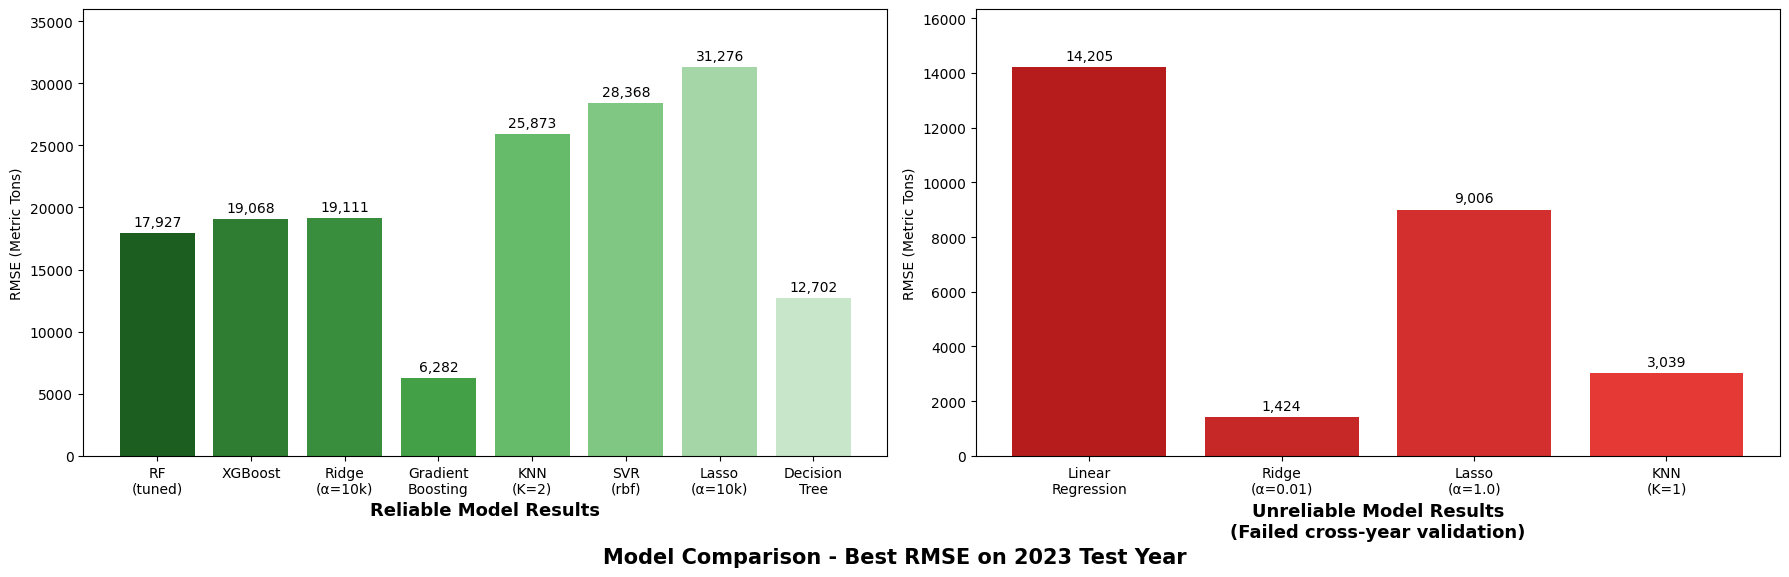

In [ ]:
import matplotlib.pyplot as plt

reliable_models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'KNN\n(K=2)', 'SVR\n(rbf)', 'Lasso\n(α=10k)', 'Decision\nTree']
reliable_rmse = [17927, 19068, 19111, 6282, 25873, 28368, 31276, 12702]

unreliable_models = ['Linear\nRegression', 'Ridge\n(α=0.01)', 'Lasso\n(α=1.0)', 'KNN\n(K=1)']
unreliable_rmse = [14205, 1424, 9006, 3039]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

colors_reliable = ['#1B5E20', '#2E7D32', '#388E3C', '#43A047', '#66BB6A', '#81C784', '#A5D6A7', '#C8E6C9']
bars1 = ax1.bar(reliable_models, reliable_rmse, color=colors_reliable)
ax1.set_ylabel('RMSE (Metric Tons)')
ax1.bar_label(bars1, fmt='{:,.0f}', padding=3)
ax1.set_ylim(0, max(reliable_rmse) * 1.15)
ax1.set_title('Reliable Model Results', fontsize=13, fontweight='bold', y=-0.15)

colors_unreliable = ['#B71C1C', '#C62828', '#D32F2F', '#E53935']
bars2 = ax2.bar(unreliable_models, unreliable_rmse, color=colors_unreliable)
ax2.set_ylabel('RMSE (Metric Tons)')
ax2.bar_label(bars2, fmt='{:,.0f}', padding=3)
ax2.set_ylim(0, max(unreliable_rmse) * 1.15)
ax2.set_title('Unreliable Model Results\n(Failed cross-year validation)', fontsize=13, fontweight='bold', y=-0.2)

plt.suptitle('Model Comparison - Best RMSE on 2023 Test Year', fontsize=15, fontweight='bold', y=0.02)
plt.tight_layout()
plt.savefig('chart1_2023_rmse.png', dpi=150, bbox_inches='tight')
plt.show()

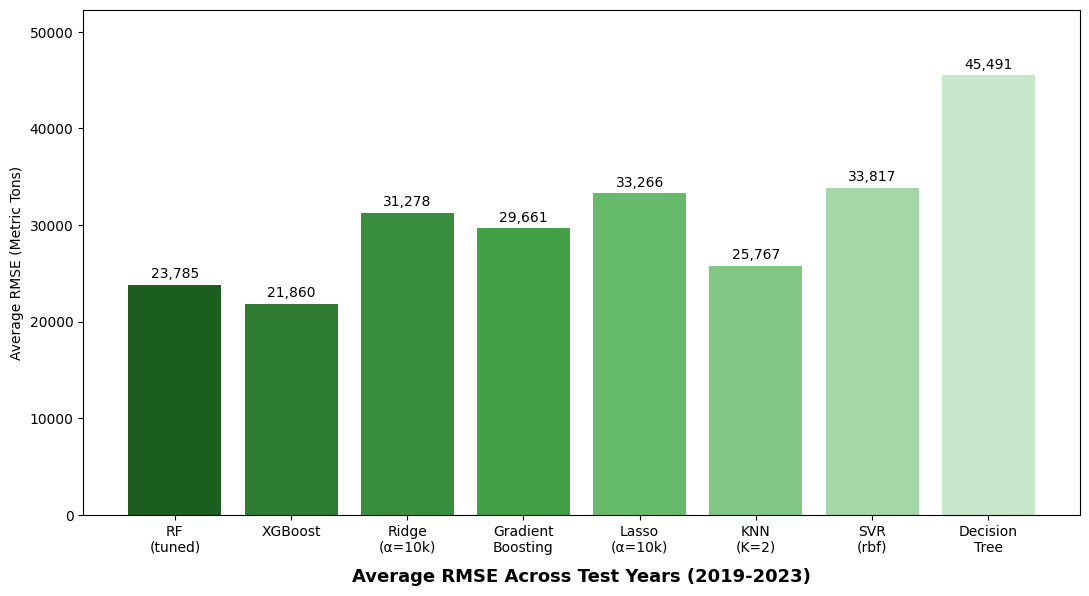

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)', 'SVR\n(rbf)', 'Decision\nTree']
avg_rmse = [23785, 21860, 31278, 29661, 33266, 25767, 33817, 45491]

colors = ['#1B5E20', '#2E7D32', '#388E3C', '#43A047', '#66BB6A', '#81C784', '#A5D6A7', '#C8E6C9']

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(models, avg_rmse, color=colors)
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_ylabel('Average RMSE (Metric Tons)')
ax.set_ylim(0, max(avg_rmse) * 1.15)
ax.set_title('Average RMSE Across Test Years (2019-2023)', fontsize=13, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('chart2_avg_rmse.png', dpi=150, bbox_inches='tight')
plt.show()

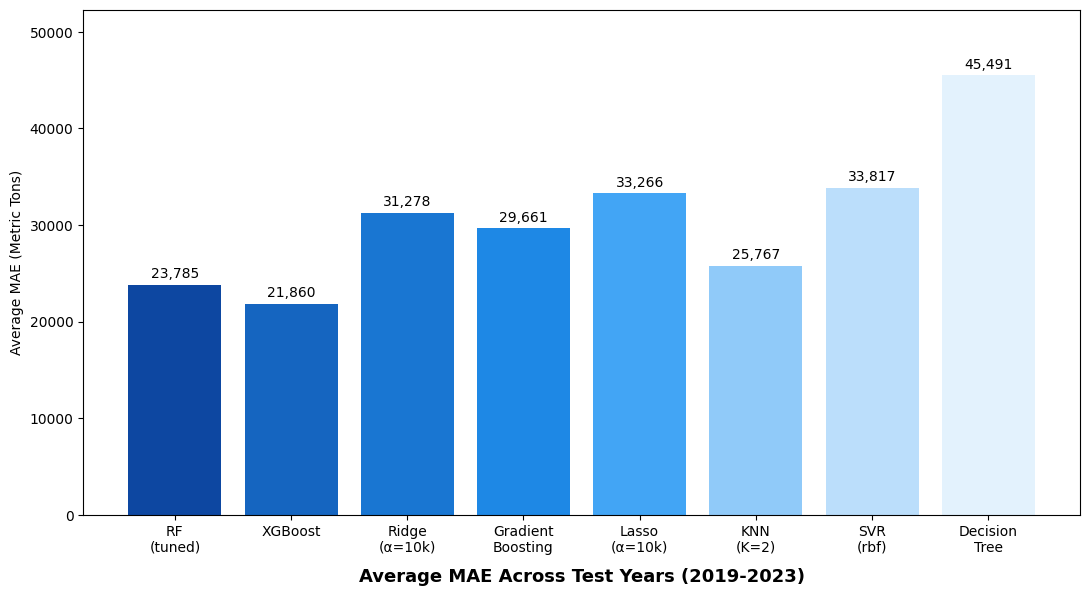

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)', 'SVR\n(rbf)', 'Decision\nTree']
avg_mae = [23785, 21860, 31278, 29661, 33266, 25767, 33817, 45491]

colors = ['#0D47A1', '#1565C0', '#1976D2', '#1E88E5', '#42A5F5', '#90CAF9', '#BBDEFB', '#E3F2FD']

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(models, avg_mae, color=colors)
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_ylabel('Average MAE (Metric Tons)')
ax.set_ylim(0, max(avg_mae) * 1.15)
ax.set_title('Average MAE Across Test Years (2019-2023)', fontsize=13, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('chart3_avg_mae.png', dpi=150, bbox_inches='tight')
plt.show()

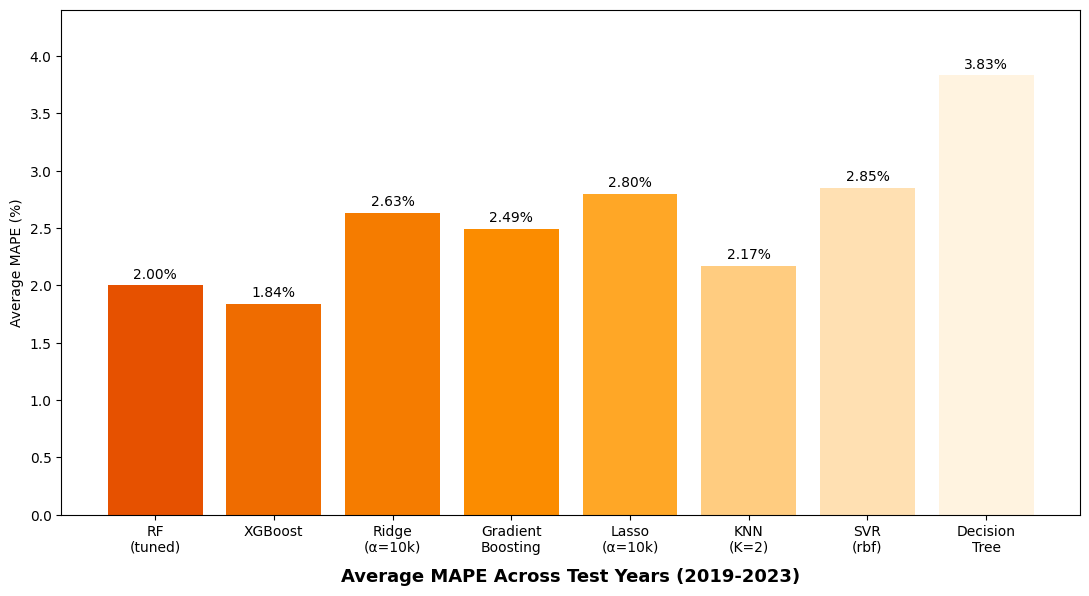

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)', 'SVR\n(rbf)', 'Decision\nTree']
avg_mape = [2.00, 1.84, 2.63, 2.49, 2.80, 2.17, 2.85, 3.83]

colors = ['#E65100', '#EF6C00', '#F57C00', '#FB8C00', '#FFA726', '#FFCC80', '#FFE0B2', '#FFF3E0']

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(models, avg_mape, color=colors)
ax.bar_label(bars, fmt='{:.2f}%', padding=3)
ax.set_ylabel('Average MAPE (%)')
ax.set_ylim(0, max(avg_mape) * 1.15)
ax.set_title('Average MAPE Across Test Years (2019-2023)', fontsize=13, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('chart4_avg_mape.png', dpi=150, bbox_inches='tight')
plt.show()

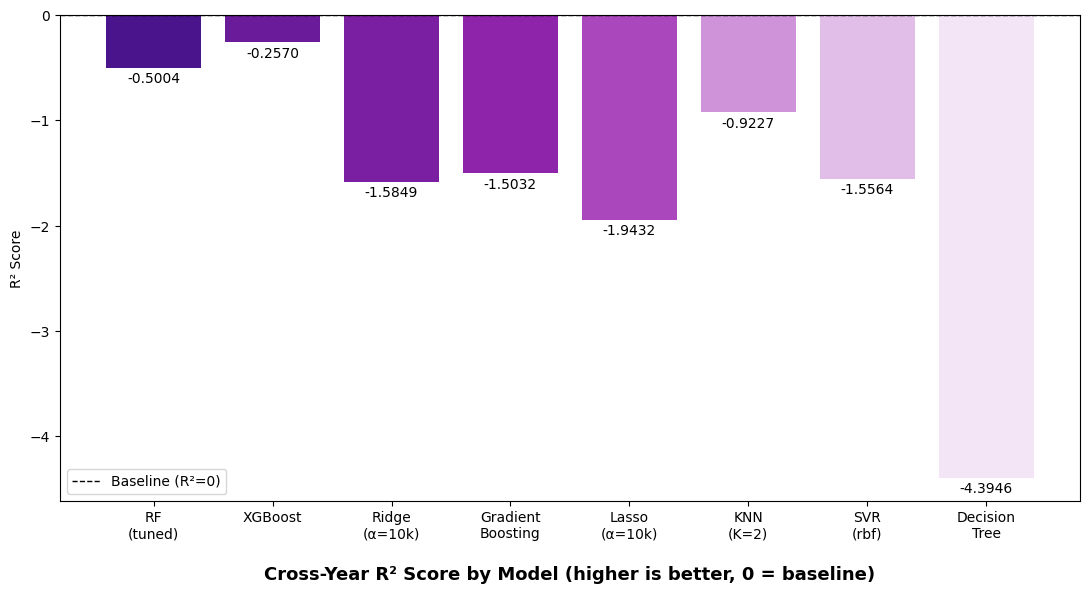

In [ ]:
import matplotlib.pyplot as plt

models = ['RF\n(tuned)', 'XGBoost', 'Ridge\n(α=10k)', 'Gradient\nBoosting', 'Lasso\n(α=10k)', 'KNN\n(K=2)', 'SVR\n(rbf)', 'Decision\nTree']
r2_values = [-0.5004, -0.2570, -1.5849, -1.5032, -1.9432, -0.9227, -1.5564, -4.3946]

colors = ['#4A148C', '#6A1B9A', '#7B1FA2', '#8E24AA', '#AB47BC', '#CE93D8', '#E1BEE7', '#F3E5F5']

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(models, r2_values, color=colors)
ax.bar_label(bars, fmt='{:.4f}', padding=3)
ax.set_ylabel('R² Score')
ax.axhline(y=0, color='black', linestyle='--', linewidth=1, label='Baseline (R²=0)')
ax.legend()
ax.set_title('Cross-Year R² Score by Model (higher is better, 0 = baseline)',
             fontsize=13, fontweight='bold', y=-0.18)
plt.tight_layout()
plt.savefig('chart5_r2.png', dpi=150, bbox_inches='tight')
plt.show()

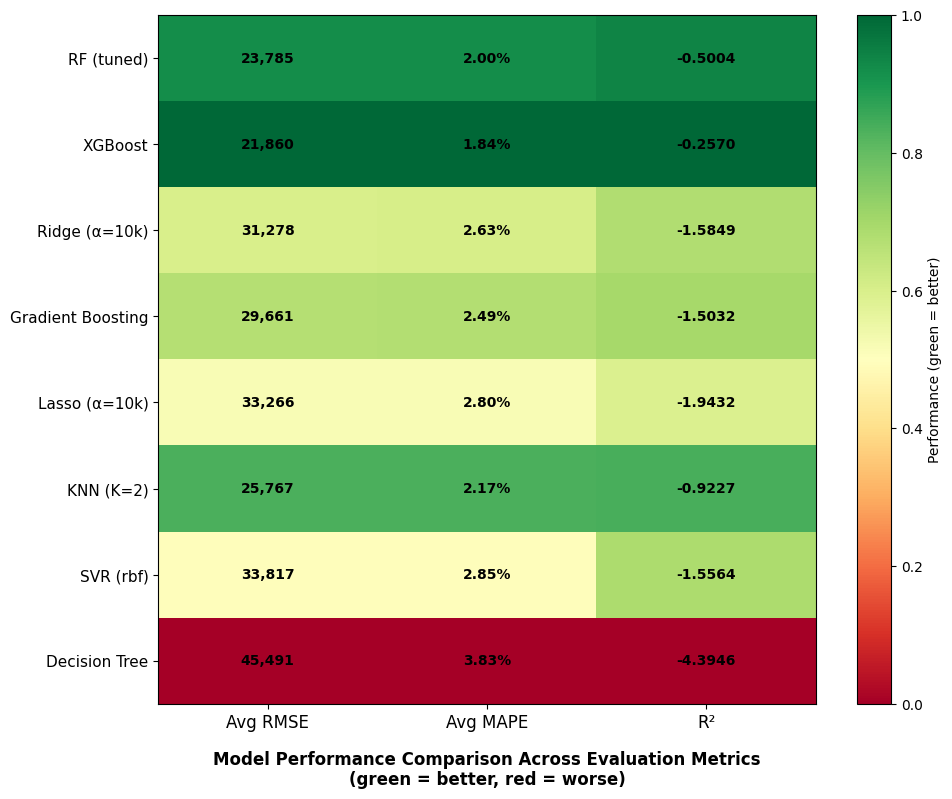

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['RF (tuned)', 'XGBoost', 'Ridge (α=10k)', 'Gradient Boosting', 'Lasso (α=10k)', 'KNN (K=2)', 'SVR (rbf)', 'Decision Tree']

rmse_values = [23785, 21860, 31278, 29661, 33266, 25767, 33817, 45491]
mape_values = [2.00, 1.84, 2.63, 2.49, 2.80, 2.17, 2.85, 3.83]
r2_values = [-0.5004, -0.2570, -1.5849, -1.5032, -1.9432, -0.9227, -1.5564, -4.3946]

def normalize_lower_better(values):
    arr = np.array(values, dtype=float)
    return 1 - (arr - arr.min()) / (arr.max() - arr.min())

def normalize_higher_better(values):
    arr = np.array(values, dtype=float)
    return (arr - arr.min()) / (arr.max() - arr.min())

rmse_norm = normalize_lower_better(rmse_values)
mape_norm = normalize_lower_better(mape_values)
r2_norm = normalize_higher_better(r2_values)

data = np.array([rmse_norm, mape_norm, r2_norm]).T

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Avg RMSE', 'Avg MAPE', 'R²'], fontsize=12)
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=11)

labels = [
    [f'{v:,.0f}' for v in rmse_values],
    [f'{v:.2f}%' for v in mape_values],
    [f'{v:.4f}' for v in r2_values]
]

for i in range(len(models)):
    for j in range(3):
        ax.text(j, i, labels[j][i], ha='center', va='center', fontsize=10, fontweight='bold')

plt.colorbar(im, ax=ax, label='Performance (green = better)')
ax.set_title('Model Performance Comparison Across Evaluation Metrics\n(green = better, red = worse)',
             fontsize=12, fontweight='bold', y=-0.13)
plt.tight_layout()
plt.savefig('chart6_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

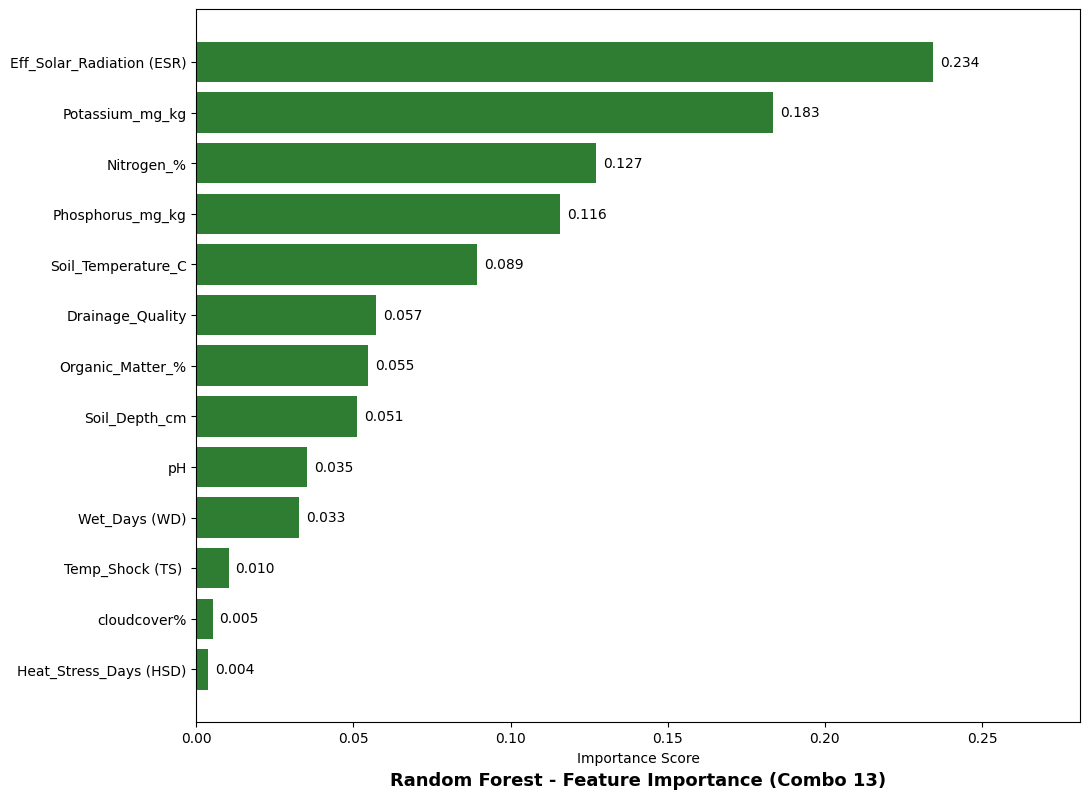

                      Feature  Importance
6   Eff_Solar_Radiation (ESR)    0.234330
8             Potassium_mg_kg    0.183439
5                  Nitrogen_%    0.127205
7            Phosphorus_mg_kg    0.115788
12         Soil_Temperature_C    0.089278
10           Drainage_Quality    0.057133
9            Organic_Matter_%    0.054655
2               Soil_Depth_cm    0.051095
11                         pH    0.035314
4               Wet_Days (WD)    0.032694
1            Temp_Shock (TS)     0.010240
3                 cloudcover%    0.005165
0      Heat_Stress_Days (HSD)    0.003665


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

rf_final = RandomForestRegressor(n_estimators=25, random_state=42)
rf_final.fit(df_train_y[combo14_features], y_train_y)

importances = rf_final.feature_importances_
feature_names = combo14_features

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(importance_df['Feature'], importance_df['Importance'], color='#2E7D32')
ax.set_xlabel('Importance Score')
ax.set_xlim(0, importance_df['Importance'].max() * 1.2)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('Random Forest - Feature Importance (Combo 13)', fontsize=13, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(importance_df.sort_values('Importance', ascending=False))

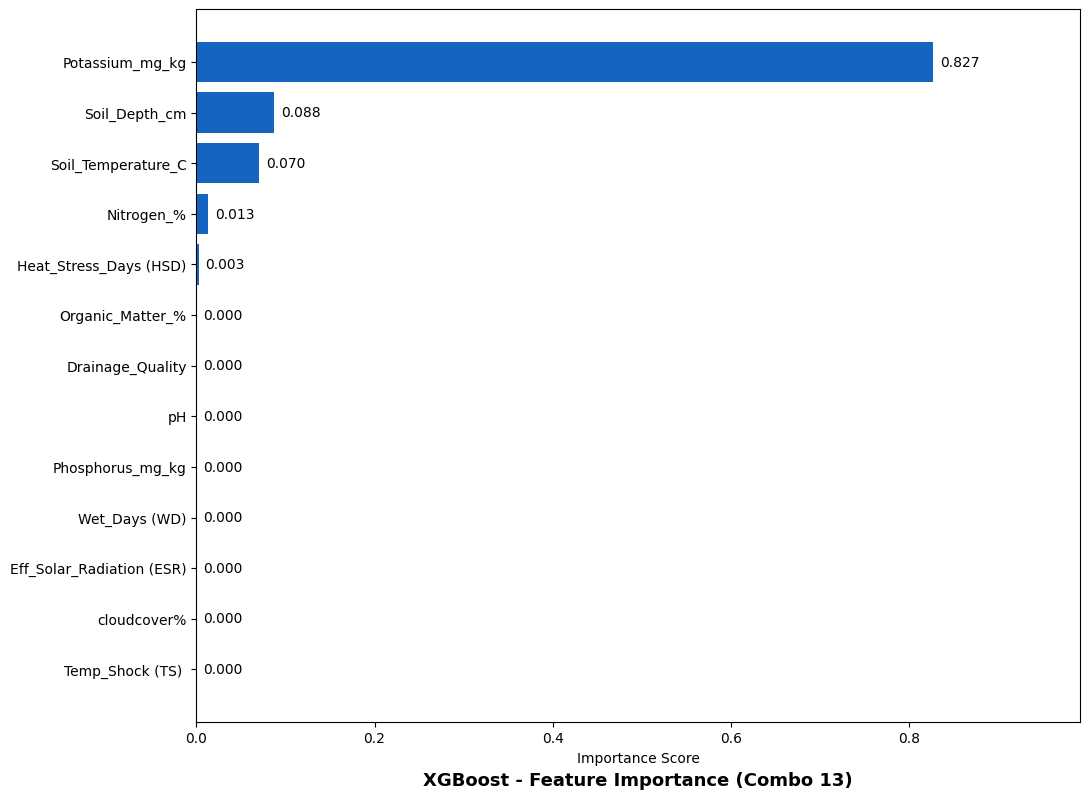

                      Feature    Importance
8             Potassium_mg_kg  8.265477e-01
2               Soil_Depth_cm  8.757011e-02
12         Soil_Temperature_C  7.035875e-02
5                  Nitrogen_%  1.290501e-02
0      Heat_Stress_Days (HSD)  2.618432e-03
9            Organic_Matter_%  4.443369e-10
7            Phosphorus_mg_kg  0.000000e+00
6   Eff_Solar_Radiation (ESR)  0.000000e+00
3                 cloudcover%  0.000000e+00
1            Temp_Shock (TS)   0.000000e+00
4               Wet_Days (WD)  0.000000e+00
11                         pH  0.000000e+00
10           Drainage_Quality  0.000000e+00


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

xgb_final = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0)
xgb_final.fit(df_train_y[combo14_features], y_train_y)

importances_xgb = xgb_final.feature_importances_
feature_names = combo14_features

importance_df_xgb = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances_xgb
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(importance_df_xgb['Feature'], importance_df_xgb['Importance'], color='#1565C0')
ax.set_xlabel('Importance Score')
ax.set_xlim(0, importance_df_xgb['Importance'].max() * 1.2)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('XGBoost - Feature Importance (Combo 13)', fontsize=13, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('xgb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(importance_df_xgb.sort_values('Importance', ascending=False))

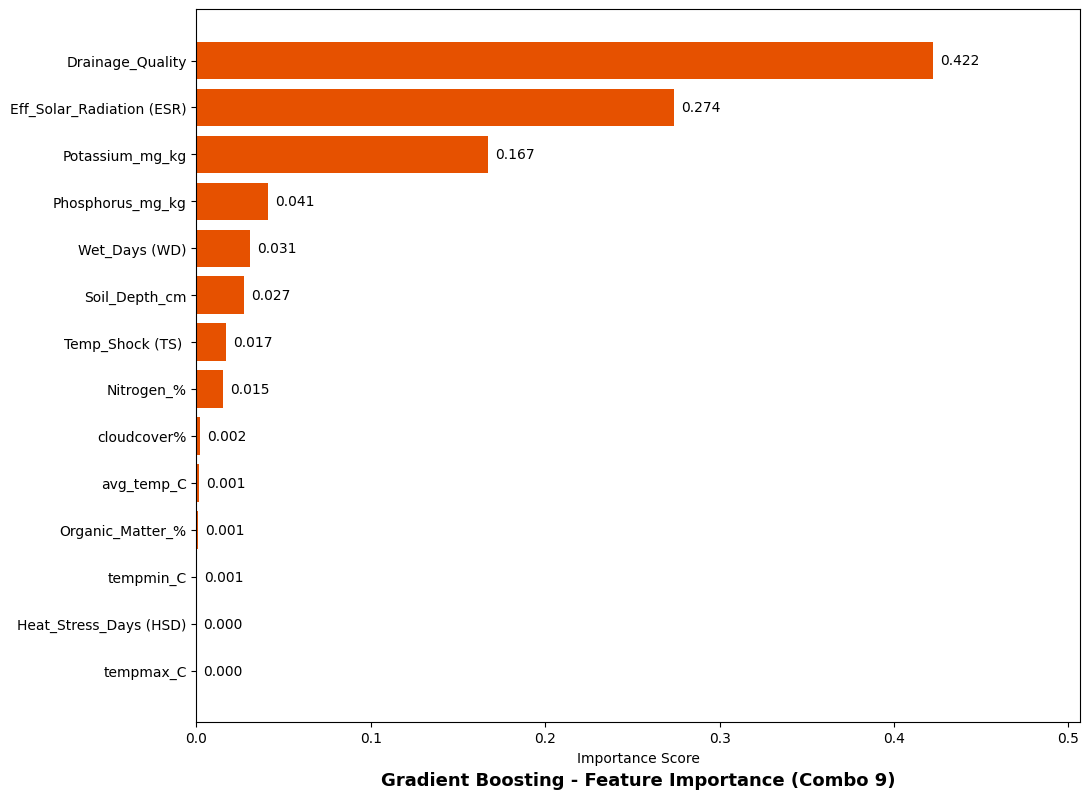

                      Feature  Importance
13           Drainage_Quality    0.422166
9   Eff_Solar_Radiation (ESR)    0.273770
11            Potassium_mg_kg    0.167368
10           Phosphorus_mg_kg    0.041174
7               Wet_Days (WD)    0.030896
5               Soil_Depth_cm    0.027180
4            Temp_Shock (TS)     0.016966
8                  Nitrogen_%    0.015333
6                 cloudcover%    0.002375
0                  avg_temp_C    0.001365
12           Organic_Matter_%    0.000823
1                   tempmin_C    0.000537
3      Heat_Stress_Days (HSD)    0.000028
2                   tempmax_C    0.000019


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

gb_final = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42)
gb_final.fit(df_train_y[combo9_features], y_train_y)

importances_gb = gb_final.feature_importances_
feature_names_gb = combo9_features

importance_df_gb = pd.DataFrame({
    'Feature': feature_names_gb,
    'Importance': importances_gb
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(importance_df_gb['Feature'], importance_df_gb['Importance'], color='#E65100')
ax.set_xlabel('Importance Score')
ax.set_xlim(0, importance_df_gb['Importance'].max() * 1.2)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('Gradient Boosting - Feature Importance (Combo 9)', fontsize=13, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('gb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(importance_df_gb.sort_values('Importance', ascending=False))

In [ ]:
top4_features = ['Potassium_mg_kg', 'Soil_Depth_cm', 'Soil_Temperature_C', 'Nitrogen_%']

xgb_top4 = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0)
xgb_top4.fit(df_train_y[top4_features], y_train_y)
y_pred_top4 = xgb_top4.predict(df_test_y[top4_features])
rmse_top4 = np.sqrt(mean_squared_error(y_test_y, y_pred_top4))

print(f'XGBoost with top 4 features only:')
print(f'Predicted: {y_pred_top4[0]:,.0f}')
print(f'Actual: {y_test_y.values[0]:,.0f}')
print(f'RMSE: {rmse_top4:,.0f}')
print(f'\nCompare to original Combo 13 (all 13 features): RMSE = 19,068')

XGBoost with top 4 features only:
Predicted: 1,169,112
Actual: 1,146,288
RMSE: 22,824

Compare to original Combo 13 (all 13 features): RMSE = 19,068


In [ ]:
top_features_gb = ['Drainage_Quality', 'Eff_Solar_Radiation (ESR)', 'Potassium_mg_kg',
                   'Phosphorus_mg_kg', 'Wet_Days (WD)', 'Soil_Depth_cm',
                   'Temp_Shock (TS) ', 'Nitrogen_%', 'cloudcover%']

gb_top = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42)
gb_top.fit(df_train_y[top_features_gb], y_train_y)
y_pred_top = gb_top.predict(df_test_y[top_features_gb])
rmse_top = np.sqrt(mean_squared_error(y_test_y, y_pred_top))

print(f'Gradient Boosting with non-zero importance features only ({len(top_features_gb)} features):')
print(f'Predicted: {y_pred_top[0]:,.0f}')
print(f'Actual: {y_test_y.values[0]:,.0f}')
print(f'RMSE: {rmse_top:,.0f}')
print(f'\nCompare to original Combo 9 (14 features): RMSE = 6,282')

Gradient Boosting with non-zero importance features only (9 features):
Predicted: 1,166,194
Actual: 1,146,288
RMSE: 19,906

Compare to original Combo 9 (14 features): RMSE = 6,282


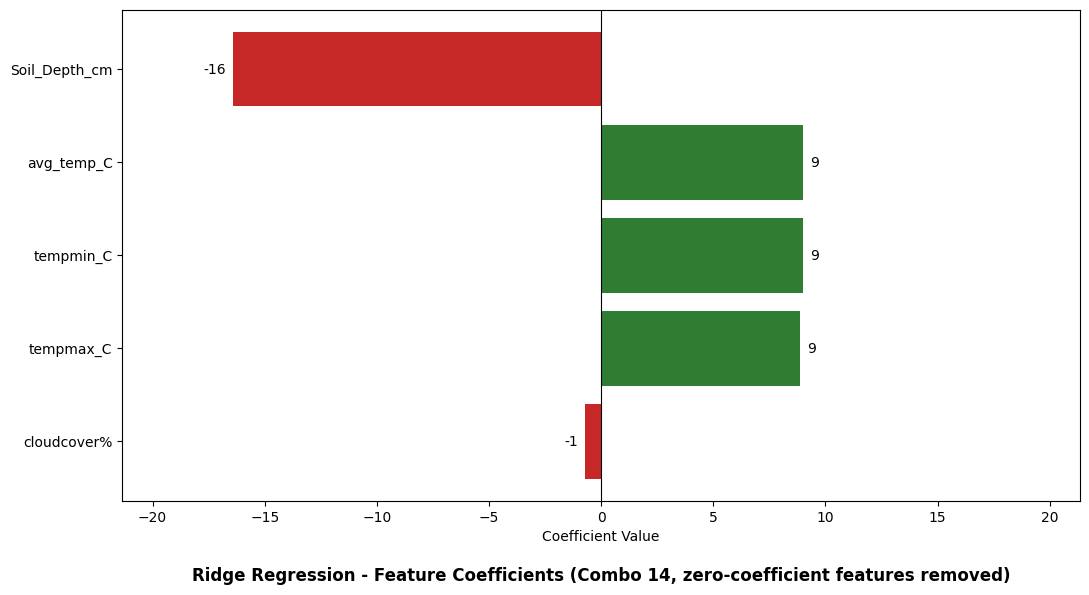

In [ ]:
import pandas as pd

# Ridge - no zero coefficients
ridge_features_no_zero = ['avg_temp_C', 'tempmin_C', 'tempmax_C', 'Soil_Depth_cm', 'cloudcover%']

ridge_clean = Ridge(alpha=10000)
ridge_clean.fit(df_train_y[ridge_features_no_zero], y_train_y)

coef_df_ridge_clean = pd.DataFrame({
    'Feature': ridge_features_no_zero,
    'Coefficient': ridge_clean.coef_
}).sort_values('Coefficient', key=abs, ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
colors = ['#C62828' if c < 0 else '#2E7D32' for c in coef_df_ridge_clean['Coefficient']]
bars = ax.barh(coef_df_ridge_clean['Feature'], coef_df_ridge_clean['Coefficient'], color=colors)
ax.set_xlabel('Coefficient Value')
ax.axvline(x=0, color='black', linewidth=0.8)
max_abs = max(abs(coef_df_ridge_clean['Coefficient'].min()), abs(coef_df_ridge_clean['Coefficient'].max()))
ax.set_xlim(-max_abs * 1.3, max_abs * 1.3)
ax.bar_label(bars, fmt='%.0f', padding=5)
ax.set_title('Ridge Regression - Feature Coefficients (Combo 14, zero-coefficient features removed)', fontsize=12, fontweight='bold', y=-0.18)
plt.tight_layout()
plt.savefig('ridge_coefficients_clean.png', dpi=150, bbox_inches='tight')
plt.show()

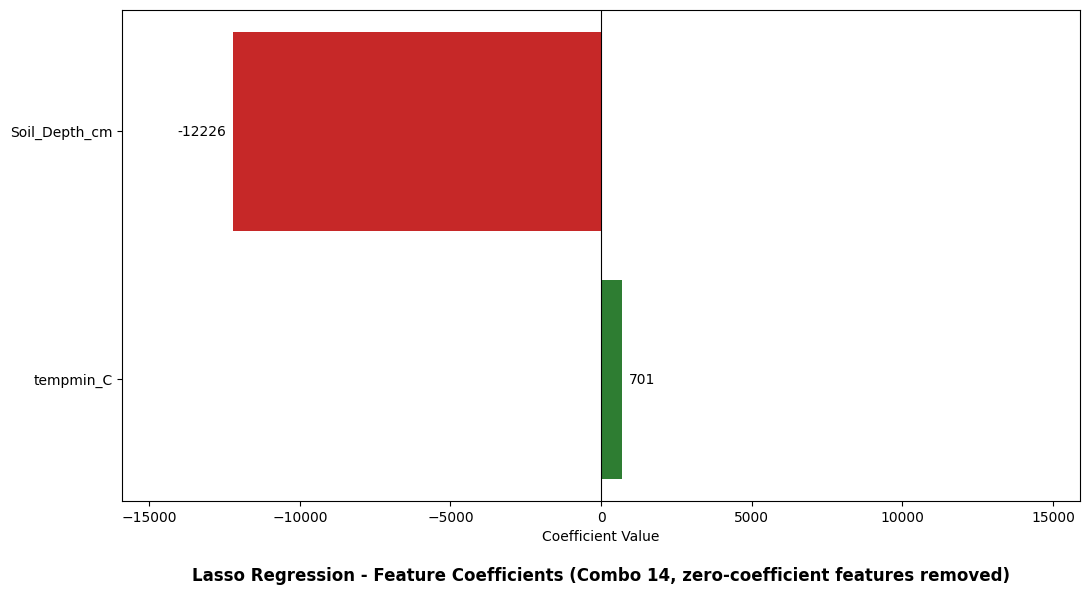

In [ ]:
# Lasso - no zero coefficients
lasso_features_no_zero = ['tempmin_C', 'Soil_Depth_cm']

lasso_clean = Lasso(alpha=10000, max_iter=10000)
lasso_clean.fit(df_train_y[lasso_features_no_zero], y_train_y)

coef_df_lasso_clean = pd.DataFrame({
    'Feature': lasso_features_no_zero,
    'Coefficient': lasso_clean.coef_
}).sort_values('Coefficient', key=abs, ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
colors = ['#C62828' if c < 0 else '#2E7D32' for c in coef_df_lasso_clean['Coefficient']]
bars = ax.barh(coef_df_lasso_clean['Feature'], coef_df_lasso_clean['Coefficient'], color=colors)
ax.set_xlabel('Coefficient Value')
ax.axvline(x=0, color='black', linewidth=0.8)
max_abs = max(abs(coef_df_lasso_clean['Coefficient'].min()), abs(coef_df_lasso_clean['Coefficient'].max()))
ax.set_xlim(-max_abs * 1.3, max_abs * 1.3)
ax.bar_label(bars, fmt='%.0f', padding=5)
ax.set_title('Lasso Regression - Feature Coefficients (Combo 14, zero-coefficient features removed)', fontsize=12, fontweight='bold', y=-0.18)
plt.tight_layout()
plt.savefig('lasso_coefficients_clean.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Combine all 5 years of test data
all_test_data = []
all_test_target = []

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]
    all_test_data.append(df_test_temp[combo1_features])
    all_test_target.append(df_test_temp[target])

X_test_combined = pd.concat(all_test_data)
y_test_combined = pd.concat(all_test_target)

knn_final = KNeighborsRegressor(n_neighbors=2)
knn_final.fit(df_train_y[combo1_features], y_train_y)

perm_importance = permutation_importance(knn_final, X_test_combined, y_test_combined,
                                          n_repeats=30, random_state=42,
                                          scoring='neg_mean_absolute_error')

perm_df = pd.DataFrame({
    'Feature': combo1_features,
    'Importance': perm_importance.importances_mean
}).sort_values('Importance', ascending=False)

print(perm_df)

                  Feature   Importance
5           Soil_Depth_cm  1952.770784
0              avg_temp_C  1117.730849
1               tempmin_C  1117.730849
2               tempmax_C   740.857705
3  Heat_Stress_Days (HSD)     0.000000
4        Temp_Shock (TS)      0.000000


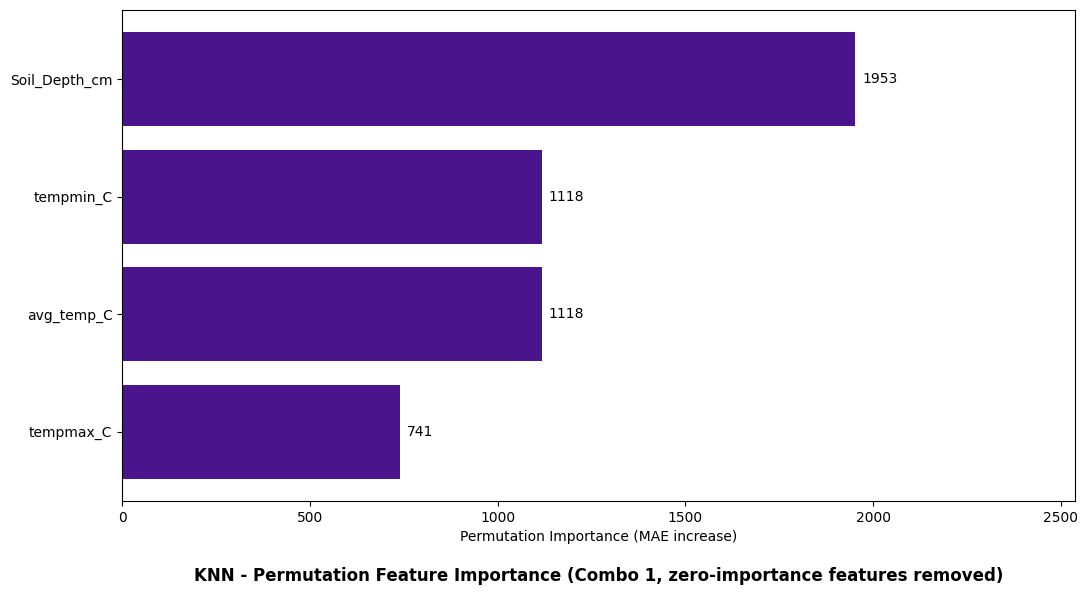

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

perm_df_clean = perm_df[perm_df['Importance'] > 0].sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(perm_df_clean['Feature'], perm_df_clean['Importance'], color='#4A148C')
ax.set_xlabel('Permutation Importance (MAE increase)')
max_val = perm_df_clean['Importance'].max()
ax.set_xlim(0, max_val * 1.3)
ax.bar_label(bars, fmt='%.0f', padding=5)
ax.set_title('KNN - Permutation Feature Importance (Combo 1, zero-importance features removed)', fontsize=12, fontweight='bold', y=-0.18)
plt.tight_layout()
plt.savefig('knn_permutation_importance_clean.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Combine all 5 years of test data with combo12 features
all_test_data_svr = []
all_test_target_svr = []

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]
    all_test_data_svr.append(df_test_temp[combo12_features])
    all_test_target_svr.append(df_test_temp[target])

X_test_combined_svr = pd.concat(all_test_data_svr)
y_test_combined_svr = pd.concat(all_test_target_svr)

scaler_svr_final = StandardScaler()
X_train_svr_final = scaler_svr_final.fit_transform(df_train_y[combo12_features])
X_test_svr_final = scaler_svr_final.transform(X_test_combined_svr)

svr_final = SVR(kernel='rbf')
svr_final.fit(X_train_svr_final, y_train_y)

perm_importance_svr = permutation_importance(svr_final, X_test_svr_final, y_test_combined_svr,
                                              n_repeats=30, random_state=42,
                                              scoring='neg_mean_absolute_error')

perm_df_svr = pd.DataFrame({
    'Feature': combo12_features,
    'Importance': perm_importance_svr.importances_mean
}).sort_values('Importance', ascending=False)

print(perm_df_svr)

                      Feature  Importance
9             Potassium_mg_kg    0.215385
7   Eff_Solar_Radiation (ESR)    0.132550
4                 cloudcover%    0.127780
13         Soil_Temperature_C    0.119705
2                   tempmax_C    0.113329
0                  avg_temp_C    0.112137
1                   tempmin_C    0.111966
5               Wet_Days (WD)    0.077236
8            Phosphorus_mg_kg    0.075118
10           Organic_Matter_%    0.070659
12                         pH    0.058527
11           Drainage_Quality    0.053751
6                  Nitrogen_%    0.023070
3               Soil_Depth_cm    0.006093


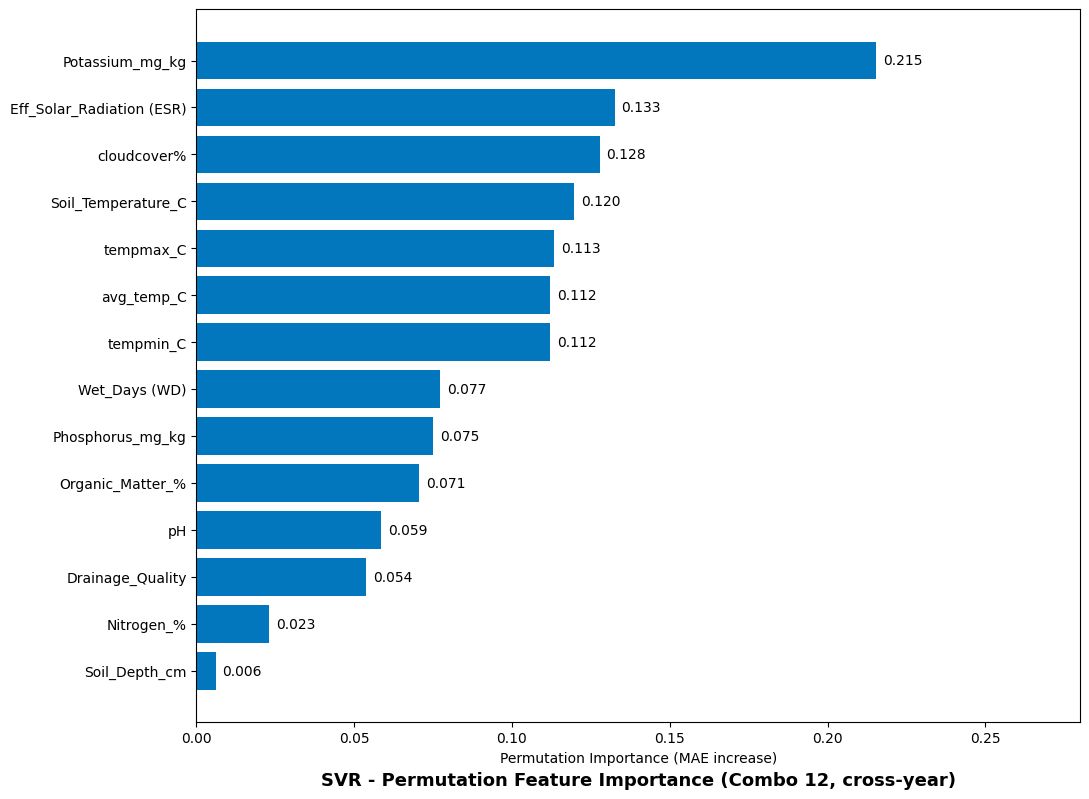

In [ ]:
import matplotlib.pyplot as plt

perm_df_svr_sorted = perm_df_svr.sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(perm_df_svr_sorted['Feature'], perm_df_svr_sorted['Importance'], color='#0277BD')
ax.set_xlabel('Permutation Importance (MAE increase)')
max_val = perm_df_svr_sorted['Importance'].max()
ax.set_xlim(0, max_val * 1.3)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('SVR - Permutation Feature Importance (Combo 12, cross-year)', fontsize=13, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('svr_permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

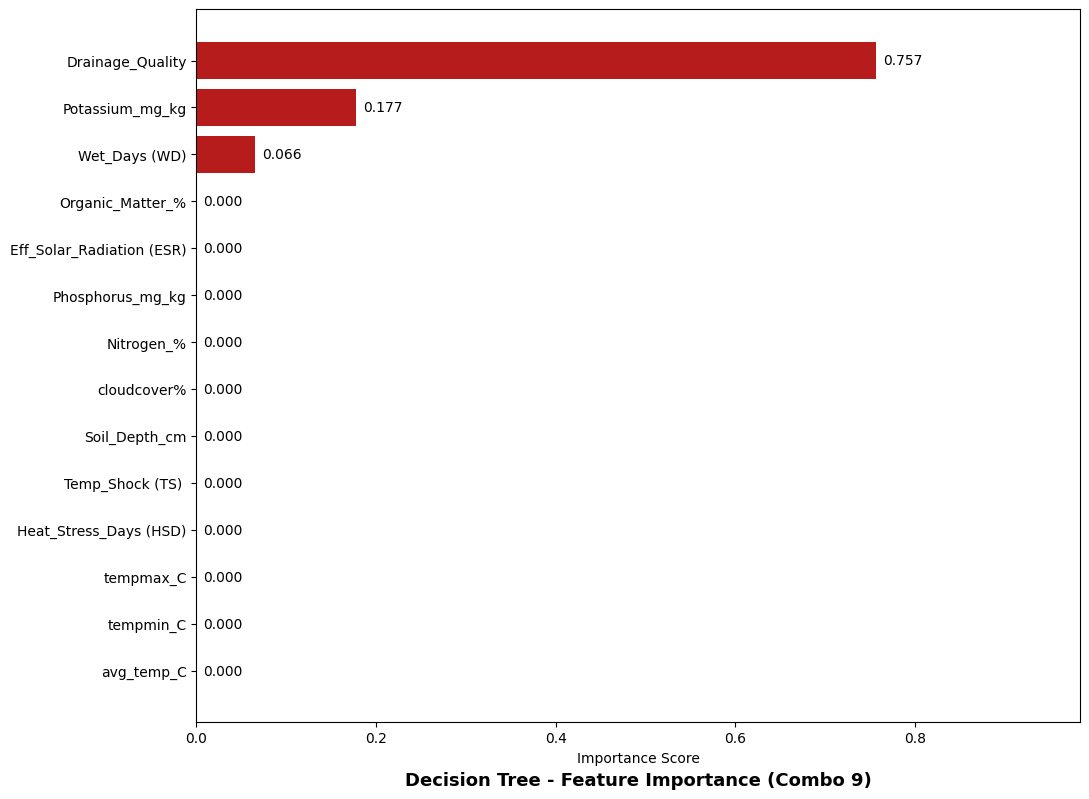

                      Feature  Importance
13           Drainage_Quality    0.756763
11            Potassium_mg_kg    0.177450
7               Wet_Days (WD)    0.065787
2                   tempmax_C    0.000000
0                  avg_temp_C    0.000000
1                   tempmin_C    0.000000
5               Soil_Depth_cm    0.000000
4            Temp_Shock (TS)     0.000000
3      Heat_Stress_Days (HSD)    0.000000
6                 cloudcover%    0.000000
9   Eff_Solar_Radiation (ESR)    0.000000
10           Phosphorus_mg_kg    0.000000
8                  Nitrogen_%    0.000000
12           Organic_Matter_%    0.000000


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

dt_final = DecisionTreeRegressor(max_depth=2, random_state=42)
dt_final.fit(df_train_y[combo9_features], y_train_y)

importances_dt = dt_final.feature_importances_
feature_names_dt = combo9_features

importance_df_dt = pd.DataFrame({
    'Feature': feature_names_dt,
    'Importance': importances_dt
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(importance_df_dt['Feature'], importance_df_dt['Importance'], color='#B71C1C')
ax.set_xlabel('Importance Score')
max_val = importance_df_dt['Importance'].max()
ax.set_xlim(0, max_val * 1.3 if max_val > 0 else 1)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('Decision Tree - Feature Importance (Combo 9)', fontsize=13, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('dt_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(importance_df_dt.sort_values('Importance', ascending=False))

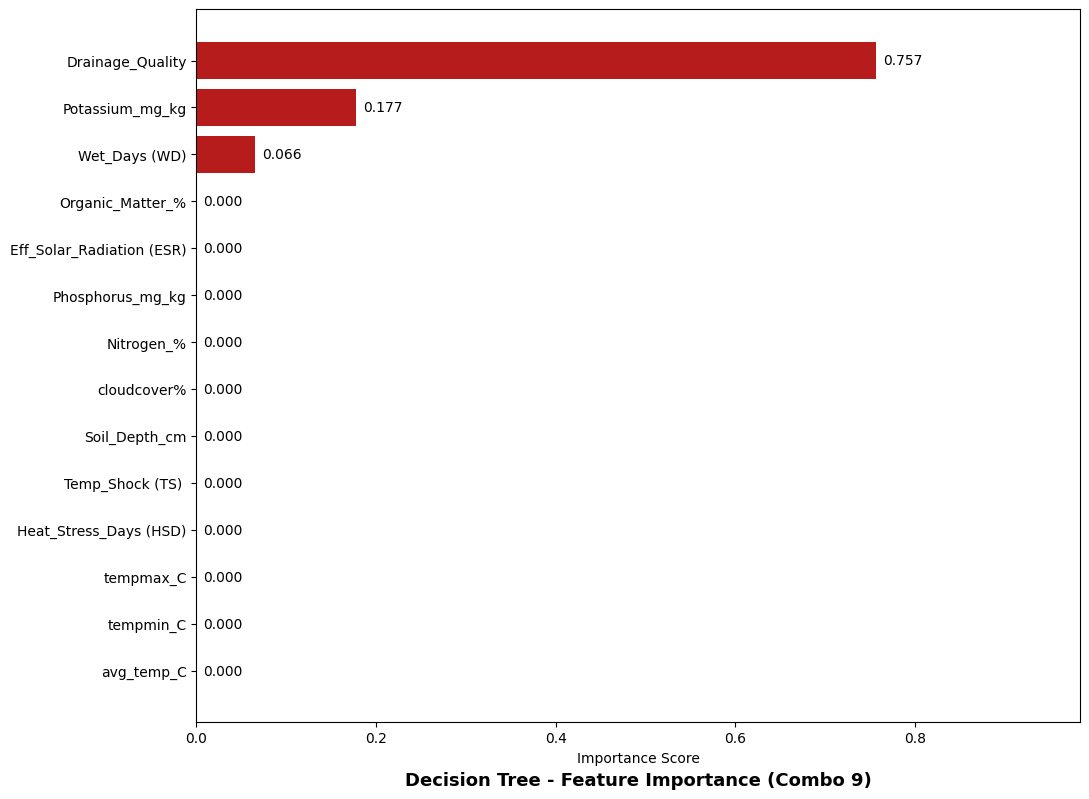

                      Feature  Importance
13           Drainage_Quality    0.756763
11            Potassium_mg_kg    0.177450
7               Wet_Days (WD)    0.065787
2                   tempmax_C    0.000000
0                  avg_temp_C    0.000000
1                   tempmin_C    0.000000
5               Soil_Depth_cm    0.000000
4            Temp_Shock (TS)     0.000000
3      Heat_Stress_Days (HSD)    0.000000
6                 cloudcover%    0.000000
9   Eff_Solar_Radiation (ESR)    0.000000
10           Phosphorus_mg_kg    0.000000
8                  Nitrogen_%    0.000000
12           Organic_Matter_%    0.000000


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

dt_final = DecisionTreeRegressor(max_depth=2, random_state=42)
dt_final.fit(df_train_y[combo9_features], y_train_y)

importances_dt = dt_final.feature_importances_
feature_names_dt = combo9_features

importance_df_dt = pd.DataFrame({
    'Feature': feature_names_dt,
    'Importance': importances_dt
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(importance_df_dt['Feature'], importance_df_dt['Importance'], color='#B71C1C')
ax.set_xlabel('Importance Score')
max_val = importance_df_dt['Importance'].max()
ax.set_xlim(0, max_val * 1.3 if max_val > 0 else 1)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('Decision Tree - Feature Importance (Combo 9)', fontsize=13, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('dt_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(importance_df_dt.sort_values('Importance', ascending=False))

In [ ]:
top_features_dt = ['Drainage_Quality', 'Potassium_mg_kg', 'Wet_Days (WD)']

dt_top = DecisionTreeRegressor(max_depth=2, random_state=42)
dt_top.fit(df_train_y[top_features_dt], y_train_y)
y_pred_dt_top = dt_top.predict(df_test_y[top_features_dt])
rmse_dt_top = np.sqrt(mean_squared_error(y_test_y, y_pred_dt_top))

print(f'Decision Tree with non-zero importance features only ({len(top_features_dt)} features):')
print(f'Predicted: {y_pred_dt_top[0]:,.0f}')
print(f'Actual: {y_test_y.values[0]:,.0f}')
print(f'RMSE: {rmse_dt_top:,.0f}')
print(f'Compare to original Combo 9 (14 features): RMSE = 12,702')

Decision Tree with non-zero importance features only (3 features):
Predicted: 1,158,990
Actual: 1,146,288
RMSE: 12,702
Compare to original Combo 9 (14 features): RMSE = 12,702


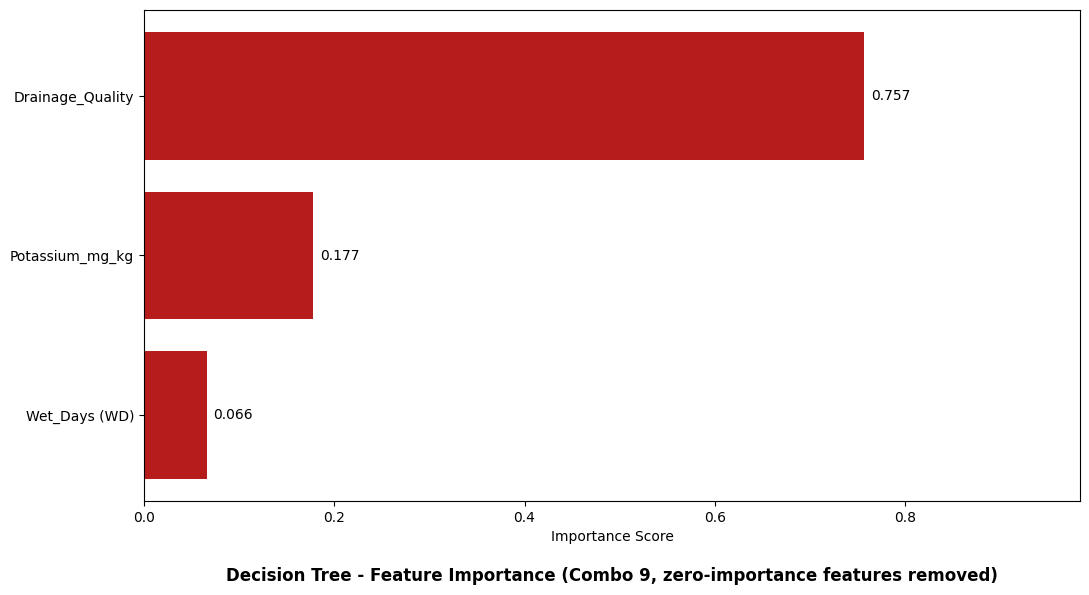

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

importance_df_dt_clean = importance_df_dt[importance_df_dt['Importance'] > 0].sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(importance_df_dt_clean['Feature'], importance_df_dt_clean['Importance'], color='#B71C1C')
ax.set_xlabel('Importance Score')
max_val = importance_df_dt_clean['Importance'].max()
ax.set_xlim(0, max_val * 1.3)
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_title('Decision Tree - Feature Importance (Combo 9, zero-importance features removed)', fontsize=12, fontweight='bold', y=-0.18)
plt.tight_layout()
plt.savefig('dt_feature_importance_clean.png', dpi=150, bbox_inches='tight')
plt.show()

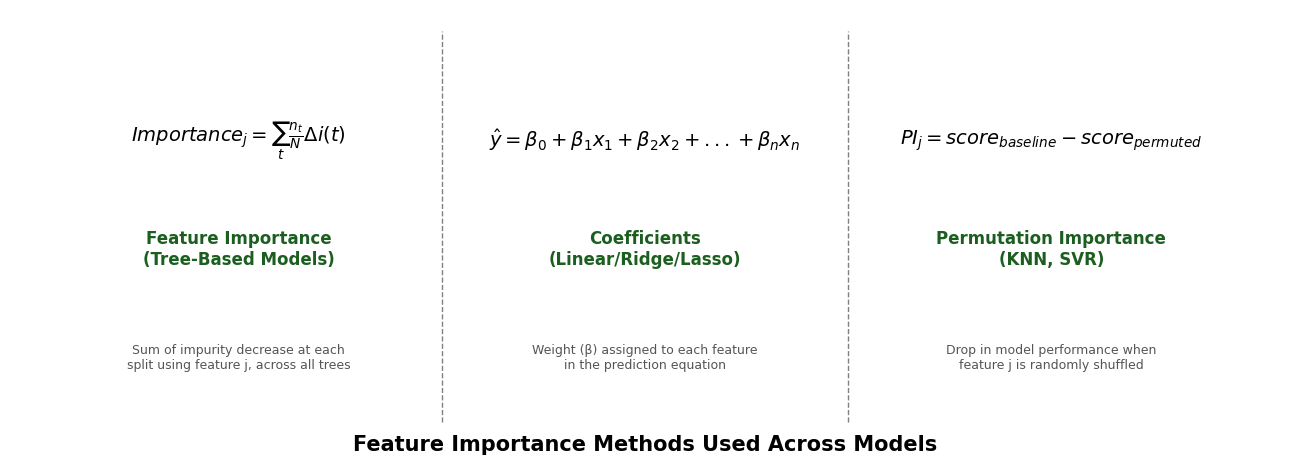

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 5))
ax.axis('off')

formulas = [
    (r'$Importance_j = \sum_{t} \frac{n_t}{N} \Delta i(t)$',
     'Feature Importance\n(Tree-Based Models)',
     'Sum of impurity decrease at each\nsplit using feature j, across all trees'),

    (r'$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_n x_n$',
     'Coefficients\n(Linear/Ridge/Lasso)',
     'Weight (β) assigned to each feature\nin the prediction equation'),

    (r'$PI_j = score_{baseline} - score_{permuted}$',
     'Permutation Importance\n(KNN, SVR)',
     'Drop in model performance when\nfeature j is randomly shuffled'),
]

x_positions = [0.18, 0.5, 0.82]

for x, (formula, label, description) in zip(x_positions, formulas):
    ax.text(x, 0.7, formula, fontsize=14, ha='center', va='center', transform=ax.transAxes)
    ax.text(x, 0.45, label, fontsize=12, ha='center', va='center', fontweight='bold', color='#1B5E20', transform=ax.transAxes)
    ax.text(x, 0.2, description, fontsize=9, ha='center', va='center', color='#555555', transform=ax.transAxes)

# Add vertical divider lines
ax.axvline(x=0.34, color='gray', linestyle='--', linewidth=1, ymin=0.05, ymax=0.95)
ax.axvline(x=0.66, color='gray', linestyle='--', linewidth=1, ymin=0.05, ymax=0.95)

plt.suptitle('Feature Importance Methods Used Across Models', fontsize=15, fontweight='bold', y=0.05)
plt.tight_layout()
plt.savefig('importance_formulas_v2.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Scale the target for ANN only
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

ann_simple = MLPRegressor(
    hidden_layer_sizes=(3,),
    activation='relu',
    max_iter=10000,
    random_state=42,
    learning_rate_init=0.01
)

ann_simple.fit(df_train_y[combo14_features], y_train_scaled)
y_pred_ann_scaled = ann_simple.predict(df_test_y[combo14_features])

# Unscale the prediction back to metric tons
y_pred_ann = scaler_y.inverse_transform(y_pred_ann_scaled.reshape(-1, 1)).ravel()
rmse_ann = np.sqrt(mean_squared_error(y_test_y, y_pred_ann))

print(f'ANN (1 hidden layer, 3 neurons, scaled target):')
print(f'Predicted: {y_pred_ann[0]:,.0f}')
print(f'Actual: {y_test_y.values[0]:,.0f}')
print(f'RMSE: {rmse_ann:,.0f}')

ANN (1 hidden layer, 3 neurons, scaled target):
Predicted: 1,180,056
Actual: 1,146,288
RMSE: 33,768


In [ ]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

architectures = {
    '1 layer, 3 neurons': (3,),
    '1 layer, 5 neurons': (5,),
    '2 layers, 3-3 neurons': (3, 3),
    '2 layers, 5-3 neurons': (5, 3),
    '3 layers, 3-3-3 neurons': (3, 3, 3),
    '3 layers, 5-3-2 neurons': (5, 3, 2),
}

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

print(f"{'Architecture':<30} {'RMSE':>12} {'Predicted':>15}")
print('-' * 60)

for name, layers in architectures.items():
    ann = MLPRegressor(hidden_layer_sizes=layers, activation='relu',
                      max_iter=10000, random_state=42, learning_rate_init=0.01)
    ann.fit(df_train_y[combo14_features], y_train_scaled)
    y_pred_scaled = ann.predict(df_test_y[combo14_features])
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
    print(f'{name:<30} {rmse:>12,.0f} {y_pred[0]:>15,.0f}')

Architecture                           RMSE       Predicted
------------------------------------------------------------
1 layer, 3 neurons                   33,768       1,180,056
1 layer, 5 neurons                   38,116       1,184,404
2 layers, 3-3 neurons                40,849       1,187,137
2 layers, 5-3 neurons                31,380       1,177,668
3 layers, 3-3-3 neurons              49,708       1,195,996
3 layers, 5-3-2 neurons              58,697       1,204,985


In [ ]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

activations = ['relu', 'tanh', 'logistic']
solvers = ['adam', 'sgd', 'lbfgs']

best_rmse = float('inf')
best_params = None

print(f"{'Architecture':<20} {'Activation':<12} {'Solver':<8} {'RMSE':>12}")
print('-' * 60)

for activation in activations:
    for solver in solvers:
        try:
            ann = MLPRegressor(
                hidden_layer_sizes=(5, 3),
                activation=activation,
                solver=solver,
                max_iter=10000,
                random_state=42,
                learning_rate_init=0.01
            )
            ann.fit(df_train_y[combo14_features], y_train_scaled)
            y_pred_scaled = ann.predict(df_test_y[combo14_features])
            y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
            rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
            if rmse < best_rmse:
                best_rmse = rmse
                best_params = {'activation': activation, 'solver': solver}
            print(f'{"(5,3)":<20} {activation:<12} {solver:<8} {rmse:>12,.0f}')
        except:
            print(f'{"(5,3)":<20} {activation:<12} {solver:<8} {"Failed":>12}')

print(f'\nBest: {best_params}, RMSE: {best_rmse:,.0f}')

Architecture         Activation   Solver           RMSE
------------------------------------------------------------
(5,3)                relu         adam           31,380
(5,3)                relu         sgd            35,492
(5,3)                relu         lbfgs          40,442
(5,3)                tanh         adam           65,225
(5,3)                tanh         sgd            60,392
(5,3)                tanh         lbfgs          73,526
(5,3)                logistic     adam           71,559
(5,3)                logistic     sgd            16,700
(5,3)                logistic     lbfgs          34,649

Best: {'activation': 'logistic', 'solver': 'sgd'}, RMSE: 16,700


In [ ]:
import warnings
warnings.filterwarnings('ignore')

architectures = {
    '1 layer, 3 neurons': (3,),
    '1 layer, 5 neurons': (5,),
    '1 layer, 10 neurons': (10,),
    '2 layers, 5-3 neurons': (5, 3),
    '2 layers, 10-5 neurons': (10, 5),
    '3 layers, 5-3-2 neurons': (5, 3, 2),
    '3 layers, 10-5-3 neurons': (10, 5, 3),
}

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

print(f"{'Architecture':<30} {'RMSE':>12} {'Predicted':>15}")
print('-' * 60)

best_rmse = float('inf')
best_arch = None

for name, layers in architectures.items():
    ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                      solver='sgd', max_iter=10000, random_state=42,
                      learning_rate_init=0.01)
    ann.fit(df_train_y[combo14_features], y_train_scaled)
    y_pred_scaled = ann.predict(df_test_y[combo14_features])
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
    if rmse < best_rmse:
        best_rmse = rmse
        best_arch = name
    print(f'{name:<30} {rmse:>12,.0f} {y_pred[0]:>15,.0f}')

print(f'\nBest architecture: {best_arch}, RMSE: {best_rmse:,.0f}')

Architecture                           RMSE       Predicted
------------------------------------------------------------
1 layer, 3 neurons                   66,696       1,212,984
1 layer, 5 neurons                   74,635       1,220,923
1 layer, 10 neurons                  70,360       1,216,648
2 layers, 5-3 neurons                16,700       1,162,988
2 layers, 10-5 neurons               13,092       1,159,380
3 layers, 5-3-2 neurons              24,495       1,170,783
3 layers, 10-5-3 neurons             22,794       1,169,082

Best architecture: 2 layers, 10-5 neurons, RMSE: 13,092


In [ ]:
import warnings
warnings.filterwarnings('ignore')

test_years = [2019, 2020, 2021, 2022, 2023]

print("ANN (2 layers 10-5, logistic, sgd) across different test years:")
print("-" * 65)

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[combo14_features]
    y_train_temp = df_train_temp[target]
    X_test_temp = df_test_temp[combo14_features]
    y_test_temp = df_test_temp[target]

    scaler_y_temp = StandardScaler()
    y_train_scaled_temp = scaler_y_temp.fit_transform(y_train_temp.values.reshape(-1, 1)).ravel()

    ann = MLPRegressor(hidden_layer_sizes=(10, 5), activation='logistic',
                      solver='sgd', max_iter=10000, random_state=42,
                      learning_rate_init=0.01)
    ann.fit(X_train_temp, y_train_scaled_temp)
    y_pred_scaled = ann.predict(X_test_temp)
    y_pred = scaler_y_temp.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    rmse = np.sqrt(mean_squared_error(y_test_temp, y_pred))

    print(f'Test year {test_year}: Predicted={y_pred[0]:,.0f}, Actual={y_test_temp.values[0]:,.0f}, RMSE={rmse:,.0f}')

ANN (2 layers 10-5, logistic, sgd) across different test years:
-----------------------------------------------------------------
Test year 2019: Predicted=1,136,810, Actual=1,180,661, RMSE=43,851
Test year 2020: Predicted=1,144,564, Actual=1,187,289, RMSE=42,725
Test year 2021: Predicted=1,150,671, Actual=1,215,305, RMSE=64,634
Test year 2022: Predicted=1,158,385, Actual=1,168,653, RMSE=10,268
Test year 2023: Predicted=1,159,380, Actual=1,146,288, RMSE=13,092


In [ ]:
import warnings
warnings.filterwarnings('ignore')

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

architectures = [(10, 5), (15, 8), (20, 10), (10, 8, 5), (15, 10, 5), (20, 10, 5)]
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]

best_rmse = float('inf')
best_params = None

print(f"{'Architecture':<20} {'LR':<8} {'RMSE':>12} {'Predicted':>15}")
print('-' * 60)

for layers in architectures:
    for lr in learning_rates:
        ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                          solver='sgd', max_iter=10000, random_state=42,
                          learning_rate_init=lr)
        ann.fit(df_train_y[combo14_features], y_train_scaled)
        y_pred_scaled = ann.predict(df_test_y[combo14_features])
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {'layers': layers, 'lr': lr}
        print(f'{str(layers):<20} {lr:<8} {rmse:>12,.0f} {y_pred[0]:>15,.0f}')

print(f'\nBest: {best_params}, RMSE: {best_rmse:,.0f}')

Architecture         LR               RMSE       Predicted
------------------------------------------------------------
(10, 5)              0.001          20,604       1,166,892
(10, 5)              0.005          15,211       1,161,499
(10, 5)              0.01           13,092       1,159,380
(10, 5)              0.05           79,155       1,225,443
(10, 5)              0.1            79,087       1,225,375
(15, 8)              0.001          18,236       1,164,524
(15, 8)              0.005          20,531       1,166,819
(15, 8)              0.01           20,485       1,166,773
(15, 8)              0.05           75,955       1,222,243
(15, 8)              0.1            76,160       1,222,448
(20, 10)             0.001          19,729       1,166,017
(20, 10)             0.005          17,887       1,164,175
(20, 10)             0.01           19,271       1,165,559
(20, 10)             0.05           78,563       1,224,851
(20, 10)             0.1            78,392       1,224

In [ ]:
import warnings
warnings.filterwarnings('ignore')

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

architectures = [(20, 15, 10), (25, 15, 8), (30, 20, 10), (20, 15, 10, 5), (25, 15, 10, 5), (30, 20, 10, 5)]
learning_rates = [0.005, 0.01, 0.05]

best_rmse = float('inf')
best_params = None

print(f"{'Architecture':<25} {'LR':<8} {'RMSE':>12}")
print('-' * 50)

for layers in architectures:
    for lr in learning_rates:
        ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                          solver='sgd', max_iter=10000, random_state=42,
                          learning_rate_init=lr)
        ann.fit(df_train_y[combo14_features], y_train_scaled)
        y_pred_scaled = ann.predict(df_test_y[combo14_features])
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {'layers': layers, 'lr': lr}
        print(f'{str(layers):<25} {lr:<8} {rmse:>12,.0f}')

print(f'\nBest: {best_params}, RMSE: {best_rmse:,.0f}')

Architecture              LR               RMSE
--------------------------------------------------
(20, 15, 10)              0.005          17,407
(20, 15, 10)              0.01           17,366
(20, 15, 10)              0.05           20,037
(25, 15, 8)               0.005          18,421
(25, 15, 8)               0.01           18,366
(25, 15, 8)               0.05           19,529
(30, 20, 10)              0.005          23,996
(30, 20, 10)              0.01           22,643
(30, 20, 10)              0.05           19,548
(20, 15, 10, 5)           0.005          14,053
(20, 15, 10, 5)           0.01           12,864
(20, 15, 10, 5)           0.05           17,611
(25, 15, 10, 5)           0.005          24,036
(25, 15, 10, 5)           0.01           26,815
(25, 15, 10, 5)           0.05           14,737
(30, 20, 10, 5)           0.005          19,262
(30, 20, 10, 5)           0.01           18,692
(30, 20, 10, 5)           0.05           19,278

Best: {'layers': (20, 15, 10, 5), 'l

In [ ]:
import warnings
warnings.filterwarnings('ignore')

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

architectures = [
    (50, 30, 20, 10),
    (40, 25, 15, 8),
    (30, 20, 15, 10, 5),
    (50, 30, 20, 10, 5),
    (100, 50, 25, 10),
    (100, 50, 25, 10, 5)
]
learning_rates = [0.005, 0.01, 0.05]

best_rmse = float('inf')
best_params = None

print(f"{'Architecture':<30} {'LR':<8} {'RMSE':>12}")
print('-' * 55)

for layers in architectures:
    for lr in learning_rates:
        ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                          solver='sgd', max_iter=10000, random_state=42,
                          learning_rate_init=lr)
        ann.fit(df_train_y[combo14_features], y_train_scaled)
        y_pred_scaled = ann.predict(df_test_y[combo14_features])
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {'layers': layers, 'lr': lr}
        print(f'{str(layers):<30} {lr:<8} {rmse:>12,.0f}')

print(f'\nBest: {best_params}, RMSE: {best_rmse:,.0f}')

Architecture                   LR               RMSE
-------------------------------------------------------
(50, 30, 20, 10)               0.005          20,350
(50, 30, 20, 10)               0.01           20,239
(50, 30, 20, 10)               0.05           18,720
(40, 25, 15, 8)                0.005          17,621
(40, 25, 15, 8)                0.01           17,633
(40, 25, 15, 8)                0.05           20,085
(30, 20, 15, 10, 5)            0.005          21,749
(30, 20, 15, 10, 5)            0.01           23,107
(30, 20, 15, 10, 5)            0.05           16,608
(50, 30, 20, 10, 5)            0.005          20,949
(50, 30, 20, 10, 5)            0.01           21,825
(50, 30, 20, 10, 5)            0.05           17,361
(100, 50, 25, 10)              0.005          19,416
(100, 50, 25, 10)              0.01           19,657
(100, 50, 25, 10)              0.05           18,847
(100, 50, 25, 10, 5)           0.005          21,833
(100, 50, 25, 10, 5)           0.01        

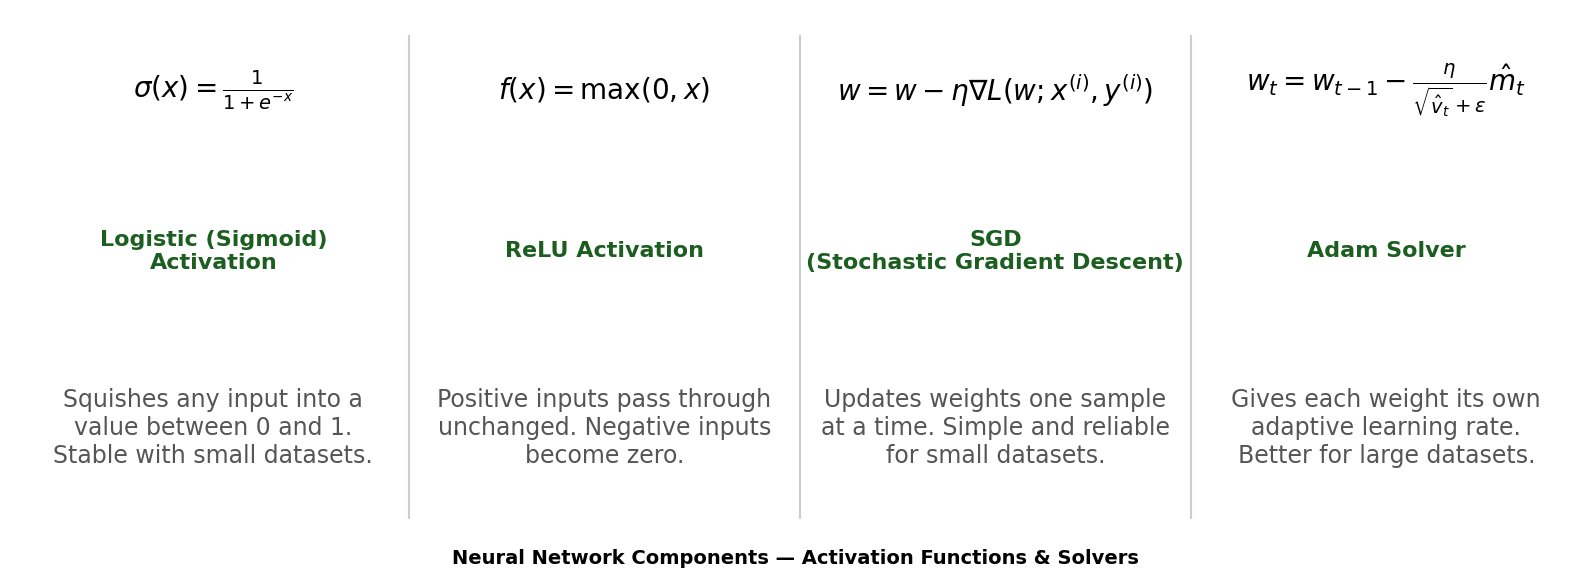

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 6))
ax.axis('off')

formulas = [
    (r'$\sigma(x) = \frac{1}{1 + e^{-x}}$',
     'Logistic (Sigmoid)\nActivation',
     'Squishes any input into a\nvalue between 0 and 1.\nStable with small datasets.'),

    (r'$f(x) = \max(0, x)$',
     'ReLU Activation',
     'Positive inputs pass through\nunchanged. Negative inputs\nbecome zero.'),

    (r'$w = w - \eta \nabla L(w; x^{(i)}, y^{(i)})$',
     'SGD\n(Stochastic Gradient Descent)',
     'Updates weights one sample\nat a time. Simple and reliable\nfor small datasets.'),

    (r'$w_t = w_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$',
     'Adam Solver',
     'Gives each weight its own\nadaptive learning rate.\nBetter for large datasets.'),
]

x_positions = [0.13, 0.38, 0.63, 0.88]

for x, (formula, label, description) in zip(x_positions, formulas):
    ax.text(x, 0.85, formula, fontsize=20, ha='center', va='center', transform=ax.transAxes)
    ax.text(x, 0.55, label, fontsize=16, ha='center', va='center',
            fontweight='bold', color='#1B5E20', transform=ax.transAxes)
    ax.text(x, 0.22, description, fontsize=17, ha='center', va='center',
            color='#555555', transform=ax.transAxes)

for x_div in [0.255, 0.505, 0.755]:
    ax.axvline(x=x_div, color='#CCCCCC', linestyle='-', linewidth=1.5, ymin=0.05, ymax=0.95)

plt.suptitle('Neural Network Components — Activation Functions & Solvers',
             fontsize=14, fontweight='bold', y=0.02)
plt.tight_layout()
plt.savefig('nn_formulas_v3.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

top4_ann_features = ['Potassium_mg_kg', 'Eff_Solar_Radiation (ESR)',
                     'Soil_Depth_cm', 'Nitrogen_%']

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

architectures = [(3,), (5,), (5, 3), (10, 5), (10, 8, 5), (20, 15, 10, 5)]
learning_rates = [0.005, 0.01, 0.05]

best_rmse = float('inf')
best_params = None

for layers in architectures:
    for lr in learning_rates:
        ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                          solver='sgd', max_iter=10000, random_state=42,
                          learning_rate_init=lr)
        ann.fit(df_train_y[top4_ann_features], y_train_scaled)
        y_pred_scaled = ann.predict(df_test_y[top4_ann_features])
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {'layers': layers, 'lr': lr}

print(f'Best ANN with top 4 features: {best_params}, RMSE: {best_rmse:,.0f}')
print(f'Compare to all 13 features: RMSE = 12,864')

Best ANN with top 4 features: {'layers': (10, 8, 5), 'lr': 0.01}, RMSE: 16,642
Compare to all 13 features: RMSE = 12,864


In [ ]:
!pip install tensorflow --quiet
import tensorflow as tf
print(tf.__version__)

2.20.0


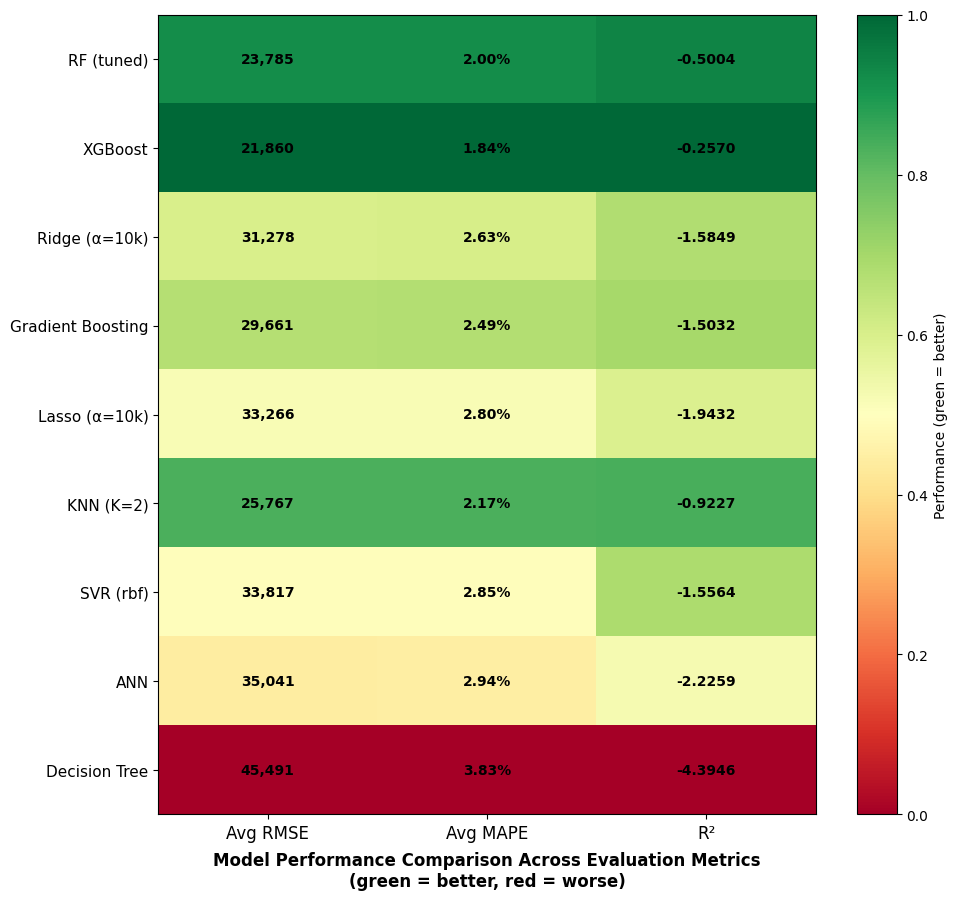

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['RF (tuned)', 'XGBoost', 'Ridge (α=10k)', 'Gradient Boosting',
          'Lasso (α=10k)', 'KNN (K=2)', 'SVR (rbf)', 'ANN', 'Decision Tree']

rmse_values = [23785, 21860, 31278, 29661, 33266, 25767, 33817, 35041, 45491]
mape_values = [2.00, 1.84, 2.63, 2.49, 2.80, 2.17, 2.85, 2.94, 3.83]
r2_values = [-0.5004, -0.2570, -1.5849, -1.5032, -1.9432, -0.9227, -1.5564, -2.2259, -4.3946]

def normalize_lower_better(values):
    arr = np.array(values, dtype=float)
    return 1 - (arr - arr.min()) / (arr.max() - arr.min())

def normalize_higher_better(values):
    arr = np.array(values, dtype=float)
    return (arr - arr.min()) / (arr.max() - arr.min())

rmse_norm = normalize_lower_better(rmse_values)
mape_norm = normalize_lower_better(mape_values)
r2_norm = normalize_higher_better(r2_values)

data = np.array([rmse_norm, mape_norm, r2_norm]).T

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Avg RMSE', 'Avg MAPE', 'R²'], fontsize=12)
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=11)

labels = [
    [f'{v:,.0f}' for v in rmse_values],
    [f'{v:.2f}%' for v in mape_values],
    [f'{v:.4f}' for v in r2_values]
]

for i in range(len(models)):
    for j in range(3):
        ax.text(j, i, labels[j][i], ha='center', va='center', fontsize=10, fontweight='bold')

plt.colorbar(im, ax=ax, label='Performance (green = better)')
ax.set_title('Model Performance Comparison Across Evaluation Metrics\n(green = better, red = worse)',
             fontsize=12, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('performance_heatmap_with_ann.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import warnings


# Scale target
from sklearn.preprocessing import StandardScaler
scaler_y_keras = StandardScaler()
y_train_keras = scaler_y_keras.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

X_train_keras = df_train_y[combo14_features].values
X_test_keras = df_test_y[combo14_features].values

best_rmse = float('inf')
best_config = None

dropout_rates = [0.1, 0.2, 0.3]
architectures = [(10, 5), (20, 10), (20, 15, 10), (20, 15, 10, 5)]

for layers_config in architectures:
    for dropout in dropout_rates:
        model = keras.Sequential()
        model.add(layers.Input(shape=(X_train_keras.shape[1],)))
        for neurons in layers_config:
            model.add(layers.Dense(neurons, activation='sigmoid'))
            model.add(layers.Dropout(dropout))
        model.add(layers.Dense(1))

        model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01),
                     loss='mse')

        model.fit(X_train_keras, y_train_keras,
                 epochs=1000, verbose=0,
                 validation_split=0.1)

        y_pred_scaled = model.predict(X_test_keras, verbose=0).ravel()
        y_pred = scaler_y_keras.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))

        if rmse < best_rmse:
            best_rmse = rmse
            best_config = {'layers': layers_config, 'dropout': dropout}

        print(f'Layers={layers_config}, Dropout={dropout}: RMSE={rmse:,.0f}')

print(f'\nBest Keras result: {best_config}, RMSE: {best_rmse:,.0f}')
print(f'Compare to sklearn best: RMSE = 12,864')

Layers=(10, 5), Dropout=0.1: RMSE=31,222


KeyboardInterrupt: 

In [ ]:
import warnings
warnings.filterwarnings('ignore')

best_config_features = combo14_features
all_years = list(range(2015, 2024))

print("Leave-One-Out Cross Validation - ANN (20,15,10,5 logistic SGD):")
print("-" * 65)

rmse_list = []
for test_year in all_years:
    train_years = [y for y in all_years if y != test_year]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[best_config_features].values
    y_train_temp = df_train_temp[target].values
    X_test_temp = df_test_temp[best_config_features].values
    y_test_temp = df_test_temp[target].values

    scaler_y_temp = StandardScaler()
    y_train_scaled_temp = scaler_y_temp.fit_transform(y_train_temp.reshape(-1, 1)).ravel()

    ann = MLPRegressor(hidden_layer_sizes=(20, 15, 10, 5), activation='logistic',
                      solver='sgd', max_iter=10000, random_state=42,
                      learning_rate_init=0.01)
    ann.fit(X_train_temp, y_train_scaled_temp)
    y_pred_scaled = ann.predict(X_test_temp)
    y_pred = scaler_y_temp.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    rmse = np.sqrt(mean_squared_error(y_test_temp, y_pred))
    rmse_list.append(rmse)
    print(f'Test year {test_year}: Predicted={y_pred[0]:,.0f}, Actual={y_test_temp[0]:,.0f}, RMSE={rmse:,.0f}')

print(f'\nAverage RMSE across all years: {sum(rmse_list)/len(rmse_list):,.0f}')

In [ ]:
import matplotlib.pyplot as plt

steps = ['Step 1\n1 layer, 3 neurons\n(relu, adam)',
         'Step 2\n2 layers (5,3)\n(relu, adam)',
         'Step 3\n2 layers (5,3)\n(logistic, sgd)',
         'Step 4\n2 layers (10,5)\n(logistic, sgd)',
         'Step 5\n4 layers (20,15,10,5)\n(logistic, sgd)',]

rmse_values = [33768, 31380, 16700, 13092, 12864]

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(range(1, 6), rmse_values, marker='o', color='#1B5E20',
        linewidth=2.5, markersize=10)

for i, (step, rmse) in enumerate(zip(steps, rmse_values)):
    ax.annotate(f'{rmse:,.0f}',
                xy=(i+1, rmse),
                xytext=(0, 15),
                textcoords='offset points',
                ha='center', fontsize=10, fontweight='bold', color='#1B5E20')

ax.set_xticks(range(1, 6))
ax.set_xticklabels(steps, fontsize=9)
ax.set_ylabel('RMSE (Metric Tons)')
ax.grid(alpha=0.3)
ax.set_ylim(10000, 38000)
ax.set_title('Strategy 1 — Architecture Simplification Progress',
             fontsize=13, fontweight='bold', y=-0.25)
plt.tight_layout()
plt.savefig('strategy1_progress.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

top4_ann_features = ['Potassium_mg_kg', 'Eff_Solar_Radiation (ESR)',
                     'Soil_Depth_cm', 'Nitrogen_%']

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_y.values.reshape(-1, 1)).ravel()

architectures = [(3,), (5,), (5, 3), (10, 5), (10, 8, 5), (20, 15, 10, 5)]
learning_rates = [0.005, 0.01, 0.05]

print("Top 4 features — best RMSE per architecture:")
print("-" * 50)

top4_results = {}
for layers in architectures:
    best_rmse_arch = float('inf')
    for lr in learning_rates:
        ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                          solver='sgd', max_iter=10000, random_state=42,
                          learning_rate_init=lr)
        ann.fit(df_train_y[top4_ann_features], y_train_scaled)
        y_pred_scaled = ann.predict(df_test_y[top4_ann_features])
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse_arch:
            best_rmse_arch = rmse
    top4_results[str(layers)] = best_rmse_arch
    print(f'{str(layers):<20} RMSE: {best_rmse_arch:,.0f}')

In [ ]:
print("All 13 features — best RMSE per architecture:")
print("-" * 50)

full_results = {}
for layers in architectures:
    best_rmse_arch = float('inf')
    for lr in learning_rates:
        ann = MLPRegressor(hidden_layer_sizes=layers, activation='logistic',
                          solver='sgd', max_iter=10000, random_state=42,
                          learning_rate_init=lr)
        ann.fit(df_train_y[combo14_features], y_train_scaled)
        y_pred_scaled = ann.predict(df_test_y[combo14_features])
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        rmse = np.sqrt(mean_squared_error(y_test_y, y_pred))
        if rmse < best_rmse_arch:
            best_rmse_arch = rmse
    full_results[str(layers)] = best_rmse_arch
    print(f'{str(layers):<20} RMSE: {best_rmse_arch:,.0f}')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

architectures = ['(3,)', '(5,)', '(5,3)', '(10,5)', '(10,8,5)', '(20,15,10,5)']
rmse_full = [63963, 72087, 16700, 13092, 12923, 12864]
rmse_top4 = [44119, 57836, 18767, 22740, 16642, 19032]

x = np.arange(len(architectures))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))
bars1 = ax.bar(x - width/2, rmse_full, width, color='#1B5E20', label='All 13 Features')
bars2 = ax.bar(x + width/2, rmse_top4, width, color='#B71C1C', label='Top 4 Features Only')

ax.bar_label(bars1, fmt='{:,.0f}', padding=3, fontsize=8)
ax.bar_label(bars2, fmt='{:,.0f}', padding=3, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=10)
ax.set_xlabel('Architecture (neurons per layer)')
ax.set_ylabel('RMSE (Metric Tons)')
ax.legend()
ax.grid(alpha=0.3, axis='y')
ax.set_ylim(0, max(max(rmse_full), max(rmse_top4)) * 1.2)
ax.set_title('Strategy 2 — All 13 Features vs Top 4 Features Across Architectures',
             fontsize=12, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('strategy2_detailed.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

architectures = ['(10,5)', '(20,10)', '(20,15,10)', '(20,15,10,5)']
dropout_01 = [20884, 31882, 20414, 19034]
dropout_02 = [19364, 26675, 18123, 18505]
dropout_03 = [23284, 27921, 18844, 18836]

x = np.arange(len(architectures))
width = 0.25

fig, ax = plt.subplots(figsize=(13, 6))
bars1 = ax.bar(x - width, dropout_01, width, color='#1565C0', label='Dropout 0.1 (10%)')
bars2 = ax.bar(x, dropout_02, width, color='#1976D2', label='Dropout 0.2 (20%)')
bars3 = ax.bar(x + width, dropout_03, width, color='#90CAF9', label='Dropout 0.3 (30%)')

ax.bar_label(bars1, fmt='{:,.0f}', padding=3, fontsize=8)
ax.bar_label(bars2, fmt='{:,.0f}', padding=3, fontsize=8)
ax.bar_label(bars3, fmt='{:,.0f}', padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=10)
ax.set_xlabel('Architecture (neurons per layer)')
ax.set_ylabel('RMSE (Metric Tons)')
ax.legend()
ax.grid(alpha=0.3, axis='y')
ax.set_ylim(0, max(max(dropout_01), max(dropout_02), max(dropout_03)) * 1.2)

# Add reference line for sklearn best
ax.axhline(y=12864, color='#1B5E20', linestyle='--', linewidth=1.5,
           label='sklearn best (12,864)')
ax.legend()

ax.set_title('Strategy 3 — Keras with Dropout: RMSE by Architecture and Dropout Rate',
             fontsize=12, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('strategy3_keras.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

years = list(range(2015, 2024))
actual_values = [1095760, 1131130, 1194996, 1149327, 1180661, 1187289, 1215305, 1168653, 1146288]
predicted_values = [1167152, 1161317, 1153312, 1158742, 1154866, 1154130, 1151413, 1156277, 1159152]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(years, actual_values, marker='o', color='#1B5E20', linewidth=2,
        markersize=8, label='Actual Yield')
ax.plot(years, predicted_values, marker='s', color='#E65100', linewidth=2,
        markersize=8, linestyle='--', label='Predicted Yield')

for year, actual, predicted in zip(years, actual_values, predicted_values):
    ax.annotate(f'{abs(actual-predicted):,.0f}',
                xy=(year, (actual+predicted)/2),
                fontsize=8, ha='center', color='#555555')

ax.set_xlabel('Year')
ax.set_ylabel('Yield (Metric Tons)')
ax.legend()
ax.set_xticks(years)
ax.grid(alpha=0.3)
ax.set_title('ANN Leave-One-Out: Actual vs Predicted Yield (error shown between lines)',
             fontsize=12, fontweight='bold', y=-0.15)
plt.tight_layout()
plt.savefig('ann_loo_visual.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

strategies = [
    'Strategy 1\nBest Architecture\n(sklearn)',
    'Strategy 2\nTop 4 Features\n(sklearn)',
    'Strategy 3\nKeras + Dropout\n(best config)',
    'Strategy 4\nLeave-One-Out\n(avg across years)'
]

rmse_values = [12864, 16642, 18123, 33418]
colors = ['#1B5E20', '#B71C1C', '#1565C0', '#E65100']

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(strategies, rmse_values, color=colors, width=0.5)
ax.bar_label(bars, fmt='{:,.0f}', padding=5, fontsize=11, fontweight='bold')
ax.set_ylabel('RMSE (Metric Tons)')
ax.set_ylim(0, max(rmse_values) * 1.2)
ax.grid(alpha=0.3, axis='y')

# Add reference line for best overall model (XGBoost)
ax.axhline(y=21860, color='gray', linestyle='--', linewidth=1.5,
           label='XGBoost avg RMSE (21,860) — best non-ANN model')
ax.legend(fontsize=9)

ax.set_title('Neural Network Strategy Comparison — Best RMSE per Strategy',
             fontsize=13, fontweight='bold', y=-0.18)
plt.tight_layout()
plt.savefig('strategy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

test_years = [2019, 2020, 2021, 2022, 2023]

print("ANN (20,15,10,5 logistic SGD) — 5-year cross validation:")
print("-" * 65)

rmse_list_ann = []
mape_list_ann = []
all_actual_ann = []
all_predicted_ann = []

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    X_train_temp = df_train_temp[combo14_features].values
    y_train_temp = df_train_temp[target].values
    X_test_temp = df_test_temp[combo14_features].values
    y_test_temp = df_test_temp[target].values

    scaler_y_temp = StandardScaler()
    y_train_scaled_temp = scaler_y_temp.fit_transform(y_train_temp.reshape(-1, 1)).ravel()

    ann = MLPRegressor(hidden_layer_sizes=(20, 15, 10, 5), activation='logistic',
                      solver='sgd', max_iter=10000, random_state=42,
                      learning_rate_init=0.01)
    ann.fit(X_train_temp, y_train_scaled_temp)
    y_pred_scaled = ann.predict(X_test_temp)
    y_pred = scaler_y_temp.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    actual = y_test_temp[0]
    predicted = y_pred[0]
    rmse = np.sqrt(mean_squared_error(y_test_temp, y_pred))
    mape = abs(actual - predicted) / actual * 100

    rmse_list_ann.append(rmse)
    mape_list_ann.append(mape)
    all_actual_ann.append(actual)
    all_predicted_ann.append(predicted)

    print(f'Test year {test_year}: Predicted={predicted:,.0f}, Actual={actual:,.0f}, RMSE={rmse:,.0f}')

from sklearn.metrics import r2_score
r2_ann = r2_score(all_actual_ann, all_predicted_ann)
avg_rmse_ann = sum(rmse_list_ann)/len(rmse_list_ann)
avg_mape_ann = sum(mape_list_ann)/len(mape_list_ann)

print(f'\nAvg RMSE: {avg_rmse_ann:,.0f}')
print(f'Avg MAPE: {avg_mape_ann:.2f}%')
print(f'R²: {r2_ann:.4f}')

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np

test_years = [2019, 2020, 2021, 2022, 2023]

print("Ensemble (XGBoost + RF + Gradient Boosting) — 5-year cross validation:")
print("-" * 70)

rmse_list_ens = []
mape_list_ens = []
all_actual_ens = []
all_predicted_ens = []

for test_year in test_years:
    train_years = [y for y in range(2015, test_year)]
    df_train_temp = df_yearly[df_yearly.index.isin(train_years)]
    df_test_temp = df_yearly[df_yearly.index == test_year]

    y_train_temp = df_train_temp[target]
    y_test_temp = df_test_temp[target]

    # XGBoost
    xgb_ens = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3,
                            random_state=42, verbosity=0)
    xgb_ens.fit(df_train_temp[combo14_features], y_train_temp)
    pred_xgb = xgb_ens.predict(df_test_temp[combo14_features])

    # RF
    rf_ens = RandomForestRegressor(n_estimators=25, random_state=42)
    rf_ens.fit(df_train_temp[combo14_features], y_train_temp)
    pred_rf = rf_ens.predict(df_test_temp[combo14_features])

    # Gradient Boosting
    gb_ens = GradientBoostingRegressor(n_estimators=100, max_depth=5,
                                        learning_rate=0.3, random_state=42)
    gb_ens.fit(df_train_temp[combo9_features], y_train_temp)
    pred_gb = gb_ens.predict(df_test_temp[combo9_features])

    # Average predictions
    pred_ensemble = (pred_xgb + pred_rf + pred_gb) / 3

    actual = y_test_temp.values[0]
    predicted = pred_ensemble[0]
    rmse = np.sqrt(mean_squared_error(y_test_temp, pred_ensemble))
    mape = abs(actual - predicted) / actual * 100

    rmse_list_ens.append(rmse)
    mape_list_ens.append(mape)
    all_actual_ens.append(actual)
    all_predicted_ens.append(predicted)

    print(f'Test year {test_year}: Predicted={predicted:,.0f}, Actual={actual:,.0f}, RMSE={rmse:,.0f}')

r2_ens = r2_score(all_actual_ens, all_predicted_ens)
avg_rmse_ens = sum(rmse_list_ens)/len(rmse_list_ens)
avg_mape_ens = sum(mape_list_ens)/len(mape_list_ens)

print(f'\nAvg RMSE: {avg_rmse_ens:,.0f}')
print(f'Avg MAPE: {avg_mape_ens:.2f}%')
print(f'R²: {r2_ens:.4f}')

In [ ]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

n_bootstrap = 1000
test_year = 2023
train_years = list(range(2015, 2023))

df_train_boot = df_yearly[df_yearly.index.isin(train_years)]
df_test_boot = df_yearly[df_yearly.index == test_year]
actual_yield = df_test_boot[target].values[0]

models_boot = {
    'XGBoost': (XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0), combo14_features),
    'RF tuned': (RandomForestRegressor(n_estimators=25, random_state=42), combo14_features),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42), combo9_features),
    'Ridge (α=10k)': (Ridge(alpha=10000), combo2_lean),
    'Lasso (α=10k)': (Lasso(alpha=10000, max_iter=10000), combo2_lean),
    'KNN (K=2)': (KNeighborsRegressor(n_neighbors=2), combo1_features),
    'SVR (rbf)': (SVR(kernel='rbf'), combo12_features),
    'Decision Tree': (DecisionTreeRegressor(max_depth=2, random_state=42), combo9_features),
}

results_boot = {}

for model_name, (model, features) in models_boot.items():
    X_train_boot = df_train_boot[features].values
    y_train_boot = df_train_boot[target].values
    X_test_boot = df_test_boot[features].values

    bootstrap_preds = []
    for i in range(n_bootstrap):
        indices = np.random.choice(len(X_train_boot), len(X_train_boot), replace=True)
        X_sample = X_train_boot[indices]
        y_sample = y_train_boot[indices]
        try:
            m = type(model)(**model.get_params())
            m.fit(X_sample, y_sample)
            pred = m.predict(X_test_boot)[0]
            bootstrap_preds.append(pred)
        except:
            bootstrap_preds.append(np.nan)

    bootstrap_preds = [p for p in bootstrap_preds if not np.isnan(p)]
    lower = np.percentile(bootstrap_preds, 2.5)
    upper = np.percentile(bootstrap_preds, 97.5)
    mean_pred = np.mean(bootstrap_preds)

    results_boot[model_name] = {
        'mean': mean_pred,
        'lower': lower,
        'upper': upper,
        'captured': lower <= actual_yield <= upper
    }
    print(f'{model_name}: [{lower:,.0f} — {upper:,.0f}], Mean={mean_pred:,.0f}, Captured={lower <= actual_yield <= upper}')

# Visual
fig, ax = plt.subplots(figsize=(12, 8))

model_names = list(results_boot.keys())
y_positions = range(len(model_names))

for i, model_name in enumerate(model_names):
    r = results_boot[model_name]
    color = '#1B5E20' if r['captured'] else '#B71C1C'
    ax.plot([r['lower'], r['upper']], [i, i], color=color, linewidth=4, alpha=0.7)
    ax.scatter(r['mean'], i, color=color, zorder=5, s=80)

ax.axvline(x=actual_yield, color='black', linestyle='--', linewidth=2, label=f'Actual Yield ({actual_yield:,.0f})')
ax.set_yticks(y_positions)
ax.set_yticklabels(model_names, fontsize=10)
ax.set_xlabel('Yield (Metric Tons)')
ax.legend(fontsize=10)
ax.grid(alpha=0.3, axis='x')

from matplotlib.patches import Patch
legend_elements = [
    Patch(color='#1B5E20', label='Actual yield within interval'),
    Patch(color='#B71C1C', label='Actual yield outside interval'),
]
ax.legend(handles=legend_elements + [plt.Line2D([0], [0], color='black', linestyle='--', label=f'Actual Yield ({actual_yield:,.0f})')],
          fontsize=9)

ax.set_title('95% Bootstrap Confidence Intervals by Model (2023 Test Year)',
             fontsize=12, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('confidence_intervals.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Add ANN bootstrap
X_train_boot = df_train_boot[combo14_features].values
y_train_boot = df_train_boot[target].values
X_test_boot = df_test_boot[combo14_features].values

ann_preds = []
for i in range(n_bootstrap):
    indices = np.random.choice(len(X_train_boot), len(X_train_boot), replace=True)
    X_sample = X_train_boot[indices]
    y_sample = y_train_boot[indices]

    scaler_y_boot = StandardScaler()
    y_sample_scaled = scaler_y_boot.fit_transform(y_sample.reshape(-1, 1)).ravel()

    ann_boot = MLPRegressor(hidden_layer_sizes=(20, 15, 10, 5), activation='logistic',
                           solver='sgd', max_iter=10000, random_state=i,
                           learning_rate_init=0.01)
    ann_boot.fit(X_sample, y_sample_scaled)
    pred_scaled = ann_boot.predict(X_test_boot)
    pred = scaler_y_boot.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()[0]
    ann_preds.append(pred)

results_boot['ANN'] = {
    'mean': np.mean(ann_preds),
    'lower': np.percentile(ann_preds, 2.5),
    'upper': np.percentile(ann_preds, 97.5),
    'captured': np.percentile(ann_preds, 2.5) <= actual_yield <= np.percentile(ann_preds, 97.5)
}
print(f'ANN: [{np.percentile(ann_preds, 2.5):,.0f} — {np.percentile(ann_preds, 97.5):,.0f}], Captured={results_boot["ANN"]["captured"]}')

# Add Ensemble bootstrap
ens_preds = []
for i in range(n_bootstrap):
    indices = np.random.choice(len(df_train_boot), len(df_train_boot), replace=True)
    df_sample = df_train_boot.iloc[indices]

    xgb_b = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=i, verbosity=0)
    rf_b = RandomForestRegressor(n_estimators=25, random_state=i)
    gb_b = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=i)

    xgb_b.fit(df_sample[combo14_features], df_sample[target])
    rf_b.fit(df_sample[combo14_features], df_sample[target])
    gb_b.fit(df_sample[combo9_features], df_sample[target])

    pred = (xgb_b.predict(df_test_boot[combo14_features])[0] +
            rf_b.predict(df_test_boot[combo14_features])[0] +
            gb_b.predict(df_test_boot[combo9_features])[0]) / 3
    ens_preds.append(pred)

results_boot['Ensemble'] = {
    'mean': np.mean(ens_preds),
    'lower': np.percentile(ens_preds, 2.5),
    'upper': np.percentile(ens_preds, 97.5),
    'captured': np.percentile(ens_preds, 2.5) <= actual_yield <= np.percentile(ens_preds, 97.5)
}
print(f'Ensemble: [{np.percentile(ens_preds, 2.5):,.0f} — {np.percentile(ens_preds, 97.5):,.0f}], Captured={results_boot["Ensemble"]["captured"]}')

# Rebuild visual with all 10 models
fig, ax = plt.subplots(figsize=(13, 10))

model_na

In [ ]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

n_bootstrap = 1000
test_year = 2023
train_years = list(range(2015, 2023))

df_train_boot = df_yearly[df_yearly.index.isin(train_years)]
df_test_boot = df_yearly[df_yearly.index == test_year]
actual_yield = df_test_boot[target].values[0]

models_boot = {
    'XGBoost': (XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42, verbosity=0), combo14_features),
    'RF tuned': (RandomForestRegressor(n_estimators=25, random_state=42), combo14_features),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=42), combo9_features),
    'Ridge (α=10k)': (Ridge(alpha=10000), combo2_lean),
    'Lasso (α=10k)': (Lasso(alpha=10000, max_iter=10000), combo2_lean),
    'KNN (K=2)': (KNeighborsRegressor(n_neighbors=2), combo1_features),
    'SVR (rbf)': (SVR(kernel='rbf'), combo12_features),
    'Decision Tree': (DecisionTreeRegressor(max_depth=2, random_state=42), combo9_features),
}

results_boot = {}

for model_name, (model, features) in models_boot.items():
    X_train_boot = df_train_boot[features].values
    y_train_boot = df_train_boot[target].values
    X_test_boot = df_test_boot[features].values

    bootstrap_preds = []
    for i in range(n_bootstrap):
        indices = np.random.choice(len(X_train_boot), len(X_train_boot), replace=True)
        X_sample = X_train_boot[indices]
        y_sample = y_train_boot[indices]
        try:
            m = type(model)(**model.get_params())
            m.fit(X_sample, y_sample)
            pred = m.predict(X_test_boot)[0]
            bootstrap_preds.append(pred)
        except:
            bootstrap_preds.append(np.nan)

    bootstrap_preds = [p for p in bootstrap_preds if not np.isnan(p)]
    lower = np.percentile(bootstrap_preds, 2.5)
    upper = np.percentile(bootstrap_preds, 97.5)
    mean_pred = np.mean(bootstrap_preds)
    results_boot[model_name] = {'mean': mean_pred, 'lower': lower, 'upper': upper,
                                 'captured': lower <= actual_yield <= upper}

# ANN bootstrap
X_train_boot_ann = df_train_boot[combo14_features].values
y_train_boot_ann = df_train_boot[target].values
X_test_boot_ann = df_test_boot[combo14_features].values

ann_preds = []
for i in range(n_bootstrap):
    indices = np.random.choice(len(X_train_boot_ann), len(X_train_boot_ann), replace=True)
    X_sample = X_train_boot_ann[indices]
    y_sample = y_train_boot_ann[indices]
    scaler_y_boot = StandardScaler()
    y_sample_scaled = scaler_y_boot.fit_transform(y_sample.reshape(-1, 1)).ravel()
    ann_boot = MLPRegressor(hidden_layer_sizes=(20, 15, 10, 5), activation='logistic',
                           solver='sgd', max_iter=10000, random_state=i,
                           learning_rate_init=0.01)
    ann_boot.fit(X_sample, y_sample_scaled)
    pred_scaled = ann_boot.predict(X_test_boot_ann)
    pred = scaler_y_boot.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()[0]
    ann_preds.append(pred)

results_boot['ANN'] = {
    'mean': np.mean(ann_preds),
    'lower': np.percentile(ann_preds, 2.5),
    'upper': np.percentile(ann_preds, 97.5),
    'captured': np.percentile(ann_preds, 2.5) <= actual_yield <= np.percentile(ann_preds, 97.5)
}

# Ensemble bootstrap
ens_preds = []
for i in range(n_bootstrap):
    indices = np.random.choice(len(df_train_boot), len(df_train_boot), replace=True)
    df_sample = df_train_boot.iloc[indices]
    xgb_b = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=i, verbosity=0)
    rf_b = RandomForestRegressor(n_estimators=25, random_state=i)
    gb_b = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.3, random_state=i)
    xgb_b.fit(df_sample[combo14_features], df_sample[target])
    rf_b.fit(df_sample[combo14_features], df_sample[target])
    gb_b.fit(df_sample[combo9_features], df_sample[target])
    pred = (xgb_b.predict(df_test_boot[combo14_features])[0] +
            rf_b.predict(df_test_boot[combo14_features])[0] +
            gb_b.predict(df_test_boot[combo9_features])[0]) / 3
    ens_preds.append(pred)

results_boot['Ensemble'] = {
    'mean': np.mean(ens_preds),
    'lower': np.percentile(ens_preds, 2.5),
    'upper': np.percentile(ens_preds, 97.5),
    'captured': np.percentile(ens_preds, 2.5) <= actual_yield <= np.percentile(ens_preds, 97.5)
}

# Visual
fig, ax = plt.subplots(figsize=(13, 10))

model_names = list(results_boot.keys())
y_positions = range(len(model_names))

for i, model_name in enumerate(model_names):
    r = results_boot[model_name]
    color = '#1B5E20' if r['captured'] else '#B71C1C'
    ax.plot([r['lower'], r['upper']], [i, i], color=color, linewidth=4, alpha=0.7)
    ax.scatter(r['mean'], i, color=color, zorder=5, s=80)

ax.axvline(x=actual_yield, color='black', linestyle='--', linewidth=2)
ax.set_yticks(y_positions)
ax.set_yticklabels(model_names, fontsize=10)
ax.set_xlabel('Yield (Metric Tons)')
ax.grid(alpha=0.3, axis='x')

from matplotlib.patches import Patch
legend_elements = [
    Patch(color='#1B5E20', label='Actual yield within interval'),
    Patch(color='#B71C1C', label='Actual yield outside interval'),
    plt.Line2D([0], [0], color='black', linestyle='--', label=f'Actual Yield ({actual_yield:,.0f})')
]
ax.legend(handles=legend_elements, fontsize=9)
ax.set_title('95% Bootstrap Confidence Intervals by Model (2023 Test Year)',
             fontsize=12, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('confidence_intervals_full.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['RF (tuned)', 'XGBoost', 'Ridge (α=10k)', 'Gradient Boosting',
          'Lasso (α=10k)', 'KNN (K=2)', 'SVR (rbf)', 'ANN', 'Decision Tree']

rmse_values = [23785, 21860, 31278, 29661, 33266, 25767, 33817, 35041, 45491]
mape_values = [2.00, 1.84, 2.63, 2.49, 2.80, 2.17, 2.85, 2.94, 3.83]
r2_values = [-0.5004, -0.2570, -1.5849, -1.5032, -1.9432, -0.9227, -1.5564, -2.2259, -4.3946]

def normalize_lower_better(values):
    arr = np.array(values, dtype=float)
    return 1 - (arr - arr.min()) / (arr.max() - arr.min())

def normalize_higher_better(values):
    arr = np.array(values, dtype=float)
    return (arr - arr.min()) / (arr.max() - arr.min())

rmse_norm = normalize_lower_better(rmse_values)
mape_norm = normalize_lower_better(mape_values)
r2_norm = normalize_higher_better(r2_values)

data = np.array([rmse_norm, mape_norm, r2_norm]).T

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Avg RMSE', 'Avg MAPE', 'R²'], fontsize=12)
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=11)

labels = [
    [f'{v:,.0f}' for v in rmse_values],
    [f'{v:.2f}%' for v in mape_values],
    [f'{v:.4f}' for v in r2_values]
]

for i in range(len(models)):
    for j in range(3):
        ax.text(j, i, labels[j][i], ha='center', va='center', fontsize=10, fontweight='bold')

plt.colorbar(im, ax=ax, label='Performance (green = better)')
ax.set_title('Model Performance Comparison Across Evaluation Metrics\n(green = better, red = worse)',
             fontsize=12, fontweight='bold', y=-0.1)
plt.tight_layout()
plt.savefig('performance_heatmap_with_ann.png', dpi=150, bbox_inches='tight')
plt.show()